## Phase 4 — Machine Learning & Model Evaluation

### 4.1 Modeling Feasibility & Target Definition

**Objective:** Evaluate the feature-engineered Namma Yatri datasets to identify a defensible machine learning target, select prediction-time features, and design an appropriate validation strategy.

**Key questions:**
1. Which prediction targets are supported by the available data?
2. Which features are genuinely available before the predicted outcome?
3. How can we evaluate model performance without target leakage or misleading validation?

**Important limitation:** The available city-level observations cover only three calendar dates, including one partial day. Future-demand forecasting must therefore be assessed carefully before model development.

We will begin by auditing Phase 3 outputs before committing to any particular model.

Connecting google colab to my repository

In [ ]:

import os
import subprocess
from pathlib import Path

REPO_URL = "https://github.com/Narasimhan15/NammaFlow.git"
REPO_PATH = Path("/content/NammaFlow")

if not REPO_PATH.exists():
    subprocess.run(
        ["git", "clone", REPO_URL, str(REPO_PATH)],
        check=True
    )

os.chdir(REPO_PATH)

print("Working directory:", os.getcwd())
print("\nRepository folders:")
print(sorted(os.listdir(".")))


Working directory: /content/NammaFlow

Repository folders:
['.git', '.gitignore', 'README.md', 'data', 'notebooks', 'requirements.txt']


Inspecting our featured-engineered datasets

In [ ]:

from pathlib import Path
import pandas as pd

processed_dir = Path("data/processed")

print("Available processed data files:\n")

if not processed_dir.exists():
    print("Processed data folder was not found.")
else:
    files = sorted(
        p for p in processed_dir.rglob("*")
        if p.is_file()
    )

    for file in files:
        print(
            f"{file} | "
            f"{file.stat().st_size / 1024:.2f} KB"
        )

    print(f"\nTotal files: {len(files)}")


Available processed data files:

data/processed/city_demand_bengaluru.csv | 29.47 KB
data/processed/city_operations_bengaluru.csv | 49.06 KB
data/processed/date_coverage.csv | 0.10 KB
data/processed/driver_supply_clean.csv | 11.36 KB
data/processed/ward_funnel_clean.csv | 248.37 KB

Total files: 5


### 4.1.1 Dataset Structure & Feature Audit

**Objective:** Load all five processed Namma Yatri datasets and inspect their dimensions, columns, and availability of engineered features.

**Why this step matters:** Machine learning requires clearly defined target variables, reliable input features, and appropriate observational granularity. Before training, we must verify the available data and determine whether Phase 3 feature engineering needs to be reproduced.

**Expected outcome:** A validated inventory of datasets and features suitable for further modeling feasibility analysis.

In [ ]:

import pandas as pd
from pathlib import Path

data_dir = Path("data/processed")

datasets = {
    "city_demand": pd.read_csv(data_dir / "city_demand_bengaluru.csv"),
    "city_operations": pd.read_csv(data_dir / "city_operations_bengaluru.csv"),
    "ward_funnel": pd.read_csv(data_dir / "ward_funnel_clean.csv"),
    "driver_supply": pd.read_csv(data_dir / "driver_supply_clean.csv"),
    "date_coverage": pd.read_csv(data_dir / "date_coverage.csv")
}

for name, df in datasets.items():
    print(f"\n{'=' * 65}")
    print(f"DATASET: {name.upper()}")
    print(f"{'=' * 65}")
    print(f"Shape: {df.shape}")
    print(f"Columns: {df.columns.tolist()}")
    print(f"Duplicate rows: {df.duplicated().sum()}")



DATASET: CITY_DEMAND
Shape: (306, 24)
Columns: ['date', 'hour', 'trip_category', 'vehicle_type', 'srch_rqst', 'srch_which_got_e', 'srch_fr_q', 'srch_which_got_q', 'booking', 'rides', 'done_ride', 'earning', 'cancel_ride', 'drvr_cancel', 'rider_cancel', 'srch_fr_q_variant', 'srch_which_got_q_variant', 'cnvr_rate', 'q_accept_rate', 'city', 'booking_type', 'city_code', 'bkng_cancel_rate', 'is_complete_day']
Duplicate rows: 0

DATASET: CITY_OPERATIONS
Shape: (505, 24)
Columns: ['date', 'hour', 'trip_category', 'vehicle_type', 'srch_rqst', 'srch_which_got_e', 'srch_fr_q', 'srch_which_got_q', 'booking', 'rides', 'done_ride', 'earning', 'cancel_ride', 'drvr_cancel', 'rider_cancel', 'srch_fr_q_variant', 'srch_which_got_q_variant', 'cnvr_rate', 'q_accept_rate', 'city', 'booking_type', 'city_code', 'bkng_cancel_rate', 'is_complete_day']
Duplicate rows: 0

DATASET: WARD_FUNNEL
Shape: (2928, 29)
Columns: ['ward_num', 'srch_fr_e', 'srch_which_got_e', 'srch_fr_q', 'srch_which_got_q', 'booking', 'on

Why are we running this code?
We're checking four important things:
- Dataset dimensions: How many rows and columns we have.
- Available features: Whether engineered variables such as hour_sin, hour_cos, and capacity_pressure_score are present.
- Duplicates: Whether any exact duplicate records exist.
- Dataset readiness: Whether we need to reproduce Phase 3 feature engineering before training.

**Phase : 3 Features presistence audit**

In [ ]:

from pathlib import Path
import json

phase3_path = Path(
    "notebooks/03_feature_engineering.ipynb"
)

with open(phase3_path, "r", encoding="utf-8") as f:
    notebook = json.load(f)

print("PHASE 3 FEATURE EXPORT AUDIT")
print("=" * 65)

keywords = [
    ".to_csv(",
    ".to_parquet(",
    ".to_pickle(",
    "joblib.dump(",
    "pickle.dump("
]

matches = []

for cell_number, cell in enumerate(
    notebook.get("cells", []), start=1
):
    if cell.get("cell_type") != "code":
        continue

    source = "".join(cell.get("source", []))

    for line in source.splitlines():
        if any(keyword in line for keyword in keywords):
            matches.append((cell_number, line.strip()))

if matches:
    for cell_number, line in matches:
        print(f"Cell {cell_number}: {line}")
else:
    print("No common file-export commands found.")

print("\nTotal matching lines:", len(matches))


PHASE 3 FEATURE EXPORT AUDIT
Cell 112: ward_intelligence.to_csv(

Total matching lines: 1


In [ ]:

# Inspect the Phase 3 export cell and nearby context

for cell_number in range(110, 115):
    if cell_number > len(notebook["cells"]):
        continue

    cell = notebook["cells"][cell_number - 1]

    print(f"\n{'=' * 60}")
    print(f"CELL {cell_number}")
    print(f"{'=' * 60}")

    source = "".join(cell.get("source", []))
    print(source[:6000])



CELL 110
# ============================================================
# FINAL PHASE 3 FEATURE AUDIT
# ============================================================

import numpy as np
import pandas as pd

print("=" * 65)
print("NAMMAFLOW — FINAL PHASE 3 FEATURE AUDIT")
print("=" * 65)

# ------------------------------------------------------------
# 1. DATASET SHAPE
# ------------------------------------------------------------

print("\n1. DATASET SHAPE")
print("-" * 65)

print(f"ward_intelligence shape : {ward_intelligence.shape}")
print(f"Total wards             : {ward_intelligence['ward_num'].nunique()}")
print(f"Total columns           : {ward_intelligence.shape[1]}")


# ------------------------------------------------------------
# 2. WARD UNIQUENESS
# ------------------------------------------------------------

print("\n2. WARD UNIQUENESS")
print("-" * 65)

duplicate_wards = ward_intelligence["ward_num"].duplicated().sum()

print(f"Duplicate ward rows : {duplicate_wards}")


**Feature engineered dataset availability verification**

In [ ]:

from pathlib import Path
import pandas as pd

feature_path = Path("data/features/ward_intelligence.csv")

print("=" * 60)
print("NAMMAFLOW — PHASE 3 FEATURE AVAILABILITY")
print("=" * 60)

print("Expected path:", feature_path)
print("File exists:", feature_path.exists())

if feature_path.exists():
    ward_ml = pd.read_csv(feature_path)

    print("\nDataset shape:", ward_ml.shape)
    print("Unique wards:", ward_ml["ward_num"].nunique())
    print("Duplicate ward IDs:",
          ward_ml["ward_num"].duplicated().sum())

    print("\nFirst five records:")
    display(ward_ml.head())

    print("\nAvailable columns:")
    for col in ward_ml.columns:
        print("-", col)

else:
    print("\nFeature dataset not found.")
    print("Available files inside data/:")

    for path in sorted(Path("data").rglob("*")):
        if path.is_file():
            print(path)


NAMMAFLOW — PHASE 3 FEATURE AVAILABILITY
Expected path: data/features/ward_intelligence.csv
File exists: True

Dataset shape: (244, 65)
Unique wards: 244
Duplicate ward IDs: 0

First five records:


,ward_num,ward_searches,ward_searches_got_e,ward_q_requests,ward_q_received,ward_search_to_e_rate,ward_e_to_q_request_rate,ward_q_accept_rate,ward_search_to_q_request_rate,ward_search_to_q_received_rate,...,searches_per_notonride_driver,q_requests_per_notonride_driver,q_supply_gap_per_notonride_driver,pre_q_loss_rate,q_to_booking_loss_rate,booking_to_completion_loss_rate,overall_search_completion_loss_rate,capacity_pressure_score,allocation_pressure_score,pressure_score_sum
0,b_1,72,72,39,21,1.0,0.541667,0.538462,0.541667,0.291667,...,0.230032,0.124601,0.057508,0.708333,0.095238,0.368421,0.833333,0.031593,0.429945,0.461538
1,b_10,188,188,139,65,1.0,0.739362,0.467626,0.739362,0.345745,...,0.471178,0.348371,0.185464,0.654255,0.000000,0.507692,0.829787,0.099752,0.432622,0.532374
2,b_100,159,159,129,56,1.0,0.811321,0.434109,0.811321,0.352201,...,0.732719,0.594470,0.336406,0.647799,0.000000,0.339286,0.767296,0.152429,0.413463,0.565891
3,b_101,43,43,29,19,1.0,0.674419,0.655172,0.674419,0.441860,...,0.716667,0.483333,0.166667,0.558140,0.000000,0.736842,0.883721,0.104250,0.240577,0.344828
4,b_102,127,127,110,52,1.0,0.866142,0.472727,0.866142,0.409449,...,1.984375,1.718750,0.906250,0.590551,0.038462,0.540000,0.818898,0.139394,0.387879,0.527273



Available columns:
- ward_num
- ward_searches
- ward_searches_got_e
- ward_q_requests
- ward_q_received
- ward_search_to_e_rate
- ward_e_to_q_request_rate
- ward_q_accept_rate
- ward_search_to_q_request_rate
- ward_search_to_q_received_rate
- ward_q_supply_gap
- ward_q_supply_gap_rate
- ward_search_to_q_received_gap
- ward_bookings
- ward_rides
- ward_completed_rides
- ward_cancellations
- ward_driver_cancellations
- ward_rider_cancellations
- ward_earnings
- ward_booking_to_ride_rate
- ward_ride_completion_rate
- ward_booking_completion_rate
- ward_cancel_per_booking
- ward_other_cancellations
- ward_driver_cancel_share
- ward_rider_cancel_share
- ward_other_cancel_share
- ward_earning_per_ride
- ward_earning_per_completed_ride
- ward_booking_to_ride_gap
- ward_ride_completion_gap
- ward_booking_to_completion_gap
- ward_ride_booking_mismatch
- supply_vehicle_coverage
- active_drvr_auto_cab
- notonride_drvr_auto_cab
- onride_drvr_auto_cab
- has_auto_supply
- has_cab_supply
- complete_

**Next: Section 4.2 — Target Selection & Data Leakage Audit**


Before training, we need to choose the problem that our model will solve.

Our leading candidate is identifying wards with poor booking conversion, potentially helping Namma Yatri prioritize operational interventions.

For example:

A ward receives 200 searches but converts only 40 into bookings. Can we identify characteristics associated with that underperformance, without giving the model the booking outcome itself?

This is different from forecasting future demand. Our ward dataset contains aggregated observations rather than a long history of ward-by-ward timestamps, so we must avoid claiming temporal forecasting capability.

##**4.2.1 Candidate Target Assessment**

**Objective:** Evaluate ward-level booking conversion, search demand, and supply pressure as potential machine learning targets.


**Method:** Examine target availability, missing values, distributions, and variability before selecting an appropriate predictive task.


**Leakage consideration:** Derived metrics containing target outcomes cannot be used as independent predictors.

Prediction-time feature availability must also be verified.

In [ ]:

import pandas as pd

candidate_targets = [
    "ward_searches",
    "ward_search_to_booking_rate",
    "ward_search_to_completion_rate",
    "ward_q_accept_rate",
    "ward_q_supply_gap_rate",
    "capacity_pressure_score",
    "allocation_pressure_score"
]

print("=" * 65)
print("NAMMAFLOW — CANDIDATE ML TARGET AUDIT")
print("=" * 65)

available_targets = [
    col for col in candidate_targets
    if col in ward_ml.columns
]

for col in candidate_targets:
    if col not in ward_ml.columns:
        print(f"\nNOT FOUND: {col}")
        continue

    series = ward_ml[col]

    print(f"\nTARGET: {col}")
    print("-" * 55)

    print("Non-null observations:", series.notna().sum())
    print("Missing values:", series.isna().sum())
    print("Unique values:", series.nunique(dropna=True))

    print("\nDistribution:")
    print(series.describe().round(4).to_string())

print("\n" + "=" * 65)
print("CANDIDATE TARGET AUDIT COMPLETE")
print("=" * 65)


NAMMAFLOW — CANDIDATE ML TARGET AUDIT

TARGET: ward_searches
-------------------------------------------------------
Non-null observations: 244
Missing values: 0
Unique values: 140

Distribution:
count     244.0000
mean      148.0000
std       424.7028
min         2.0000
25%        26.7500
50%        48.5000
75%       117.7500
max      4862.0000

TARGET: ward_search_to_booking_rate
-------------------------------------------------------
Non-null observations: 244
Missing values: 0
Unique values: 188

Distribution:
count    244.0000
mean       0.3389
std        0.1134
min        0.0000
25%        0.2719
50%        0.3333
75%        0.4052
max        0.7600

TARGET: ward_search_to_completion_rate
-------------------------------------------------------
Non-null observations: 244
Missing values: 0
Unique values: 177

Distribution:
count    244.0000
mean       0.1819
std        0.0857
min        0.0000
25%        0.1250
50%        0.1796
75%        0.2331
max        0.5000

TARGET: ward_q_a

**Why are we doing this?**

A model needs a target variable, often represented as y.

For example, if we eventually select ward_search_to_booking_rate, our task could be a regression problem:

**y = Ward_Booking_Conversion_rate**


But we must not include ward_bookings, ward_search_to_booking_gap, or other same-period outcome-derived features as predictors. Doing so could allow the model to reconstruct the answer rather than genuinely predict it.

Also, with only 244 ward observations, we'll need conservative validation and comparison against a simple baseline.

**Recommended ML target**

**Ward Booking Conversion Rate**
**33.89%**

Average observed ward-level conversion rate

**Target column: ward_search_to_booking_rate**

ML problem: Regression, subject to feature feasibility and leakage checks.

**Why this target?**

Our NammaFlow business problem is to identify areas where passengers search for rides but fail to convert those searches into bookings.

If we can model booking conversion using information available before the outcome, we could help Namma Yatri identify underserved wards.

For example, a ward may receive 200 searches but only 50 bookings:

**Conversion rate = 50 / 200 = 25%**

A sufficiently validated model might estimate conversion performance under different operational conditions.


**Important:** Our current data contains aggregated outcomes rather than repeated historical ward-level observations. We cannot yet claim that this model predicts future conversion accurately.

##**4.2.2 Target Leakage & Feature Availability Audit**

**Objective:** Assess whether the engineered ward-level features can be used to model booking conversion without exposing booking outcomes or information unavailable at prediction time.

**Target: ward_search_to_booking_rate**

**Key concern:** Same-period bookings, funnel outcomes, downstream rates, and engineered variables derived from them may cause target leakage.

**Decision rule:** No feature will be approved for modeling solely because it correlates with the target. Its definition, source and availability must first be verified.

In [ ]:

import pandas as pd

target = "ward_search_to_booking_rate"

audit = pd.DataFrame({
    "feature": ward_ml.columns,
    "dtype": ward_ml.dtypes.astype(str).values,
    "missing_count": ward_ml.isna().sum().values,
    "unique_values": ward_ml.nunique(dropna=True).values
})

# Descriptive screening only.
# These labels are NOT final leakage decisions.
audit["screening_flag"] = "Requires manual review"

audit.loc[
    audit["feature"] == target,
    "screening_flag"
] = "Target"

audit.loc[
    audit["feature"] == "ward_num",
    "screening_flag"
] = "Ward identifier"

print("=" * 70)
print("NAMMAFLOW — ML FEATURE AVAILABILITY AUDIT")
print("=" * 70)

print("Target:", target)
print("Total columns:", len(audit))
print("Total rows:", len(ward_ml))

display(audit.to_string(index=False))


NAMMAFLOW — ML FEATURE AVAILABILITY AUDIT
Target: ward_search_to_booking_rate
Total columns: 65
Total rows: 244


'                            feature   dtype  missing_count  unique_values         screening_flag\n                           ward_num  object              0            244        Ward identifier\n                      ward_searches   int64              0            140 Requires manual review\n                ward_searches_got_e   int64              0            141 Requires manual review\n                    ward_q_requests   int64              0            116 Requires manual review\n                    ward_q_received   int64              0             87 Requires manual review\n              ward_search_to_e_rate float64              0              7 Requires manual review\n           ward_e_to_q_request_rate float64              0            193 Requires manual review\n                 ward_q_accept_rate float64              1            170 Requires manual review\n      ward_search_to_q_request_rate float64              0            194 Requires manual review\n     ward_search_to

**What does this code do?**

It creates an audit table containing each feature's name, datatype, number of missing observations and number of unique values.

We'll use that information alongside the feature definitions from Phase 3 to determine which variables should be excluded.

- Target: ward_search_to_booking_rate
- Total columns: 65
- Ward observations: 244
- Screening: Features marked for manual review, as intended.

**Fixing the audit table dsiplay**

In [ ]:
display(audit)

,feature,dtype,missing_count,unique_values,screening_flag
0,ward_num,object,0,244,Ward identifier
1,ward_searches,int64,0,140,Requires manual review
2,ward_searches_got_e,int64,0,141,Requires manual review
3,ward_q_requests,int64,0,116,Requires manual review
4,ward_q_received,int64,0,87,Requires manual review
...,...,...,...,...,...
60,booking_to_completion_loss_rate,float64,3,135,Requires manual review
61,overall_search_completion_loss_rate,float64,0,177,Requires manual review
62,capacity_pressure_score,float64,3,225,Requires manual review
63,allocation_pressure_score,float64,3,230,Requires manual review


##**4.2.3 Preliminary Feature Leakage Classification**

**Objective:** Screen the 65 ward-level columns for potential target leakage before building machine learning models.

**Target variable: ward_search_to_booking_rate**

**Approach:** Identify direct outcome-related variables, separate the ward identifier, and flag remaining features for manual review of their definitions and measurement timing.

**Important** This is an initial screening, not final feature selection.

In [ ]:

target = "ward_search_to_booking_rate"

outcome_terms = [
    "booking",
    "cancel",
    "completion",
    "completed",
    "ride",
    "earning",
    "loss"
]

feature_classification = []

for col in ward_ml.columns:

    if col == target:
        category = "TARGET"

    elif col == "ward_num":
        category = "IDENTIFIER"

    elif any(term in col.lower() for term in outcome_terms):
        category = "OUTCOME-RELATED — REVIEW/EXCLUDE"

    else:
        category = "REQUIRES SOURCE/TIMING REVIEW"

    feature_classification.append({
        "feature": col,
        "category": category
    })

leakage_audit = pd.DataFrame(feature_classification)

print("=" * 65)
print("NAMMAFLOW — PRELIMINARY FEATURE LEAKAGE AUDIT")
print("=" * 65)

display(leakage_audit)

print("\nCATEGORY SUMMARY")
display(
    leakage_audit["category"]
    .value_counts()
    .rename_axis("category")
    .reset_index(name="feature_count")
)


NAMMAFLOW — PRELIMINARY FEATURE LEAKAGE AUDIT


,feature,category
0,ward_num,IDENTIFIER
1,ward_searches,REQUIRES SOURCE/TIMING REVIEW
2,ward_searches_got_e,REQUIRES SOURCE/TIMING REVIEW
3,ward_q_requests,REQUIRES SOURCE/TIMING REVIEW
4,ward_q_received,REQUIRES SOURCE/TIMING REVIEW
...,...,...
60,booking_to_completion_loss_rate,OUTCOME-RELATED — REVIEW/EXCLUDE
61,overall_search_completion_loss_rate,OUTCOME-RELATED — REVIEW/EXCLUDE
62,capacity_pressure_score,REQUIRES SOURCE/TIMING REVIEW
63,allocation_pressure_score,REQUIRES SOURCE/TIMING REVIEW



CATEGORY SUMMARY


,category,feature_count
0,OUTCOME-RELATED — REVIEW/EXCLUDE,36
1,REQUIRES SOURCE/TIMING REVIEW,27
2,IDENTIFIER,1
3,TARGET,1


**What do these results mean?**

We've flagged 36 outcome-related columns because their names contain terms associated with bookings, cancellations, rides, earnings or downstream events.

The remaining 27 columns require closer examination. Some may be useful, but others could still leak target information indirectly.

For example, ward_q_received may be recorded during the same period as the bookings we're trying to predict. Likewise, capacity_pressure_score may contain a variable that depends on an operational outcome.

We should not automatically use all 27 remaining columns.

##**4.2.4 Candidate Feature Review**

**Objective:** Inspect the features not flagged as obvious outcome variables and determine which require further investigation before model development.

**Approach:** Review feature names, data types, missing values, and Phase 3 derivation logic.

**Important:** Features will only be approved after their source variables and availability at prediction time have been verified.



In [ ]:

# Examine the 27 features requiring further review

candidate_features = leakage_audit.loc[
    leakage_audit["category"] == "REQUIRES SOURCE/TIMING REVIEW",
    "feature"
].tolist()

candidate_review = pd.DataFrame({
    "feature": candidate_features,
    "dtype": ward_ml[candidate_features].dtypes.astype(str).values,
    "missing": ward_ml[candidate_features].isna().sum().values,
    "unique_values": ward_ml[candidate_features].nunique(dropna=True).values
})

print("=" * 65)
print("NAMMAFLOW — CANDIDATE FEATURE REVIEW")
print("=" * 65)

print("Candidate features:", len(candidate_features))

display(candidate_review)


NAMMAFLOW — CANDIDATE FEATURE REVIEW
Candidate features: 27


,feature,dtype,missing,unique_values
0,ward_searches,int64,0,140
1,ward_searches_got_e,int64,0,141
2,ward_q_requests,int64,0,116
3,ward_q_received,int64,0,87
4,ward_search_to_e_rate,float64,0,7
5,ward_e_to_q_request_rate,float64,0,193
6,ward_q_accept_rate,float64,1,170
7,ward_search_to_q_request_rate,float64,0,194
8,ward_search_to_q_received_rate,float64,0,188
9,ward_q_supply_gap,int64,0,83


**Why are we doing this?**

We're narrowing our initial 65-column inventory to a manageable set that needs detailed examination.

The important distinction is between explaining historical outcomes and predicting future outcomes.

For instance, a feature may be statistically associated with booking conversion but unavailable until after bookings happen.
It may support retrospective operational analysis without being a valid forecasting input.

Once we've inspected these 27 features, we'll audit their Phase 3 formulas, establish a realistic prediction scenario and select the final modeling inputs.

Three findings deserve attention:
- Constant features: has_auto_supply, ward_driver_count_gap, and ward_driver_share_sum each contain only one unique value. They cannot distinguish one ward from another, so they provide no useful variation for our initial model.
- Funnel features: ward_q_received, ward_q_accept_rate, and ward_q_supply_gap_rate describe events that occur during the booking funnel. Their timing needs careful consideration.
- Pressure features: capacity_pressure_score and allocation_pressure_score are valuable for diagnosing operational conditions, but we still need to verify their formulas before using them as predictors.


An important distinction: a feature can be valuable for operational diagnosis without being suitable for future prediction.

##4.2.5 Feature Formula & Leakage Verification

**Objective:** Trace selected engineered features to their original calculation logic in Phase 3.

**Features under investigation:** Driver availability, utilization, Q-stage supply gaps, capacity pressure, and allocation pressure.

**Decision criteria:** Identify source variables, determine whether calculations depend on booking outcomes, and assess whether the feature could exist before the prediction event.

**Expected outcome:** Evidence-based feature eligibility decisions before machine learning model development.

In [ ]:

# Inspect Phase 3 feature calculation logic

from pathlib import Path
import json

phase3_path = Path("notebooks/03_feature_engineering.ipynb")

with open(phase3_path, "r", encoding="utf-8") as f:
    phase3_nb = json.load(f)

features_to_trace = [
    "capacity_pressure_score",
    "allocation_pressure_score",
    "ward_driver_utilization_rate",
    "active_drvr_auto_cab",
    "ward_q_supply_gap"
]

print("=" * 70)
print("NAMMAFLOW — FEATURE FORMULA TRACE")
print("=" * 70)

for feature in features_to_trace:

    print(f"\nFEATURE: {feature}")
    print("-" * 70)

    matches = []

    for idx, cell in enumerate(
        phase3_nb["cells"], start=1
    ):
        if cell.get("cell_type") != "code":
            continue

        source = "".join(cell.get("source", []))
        lines = source.splitlines()

        for line_no, line in enumerate(lines):
            if feature in line and not line.lstrip().startswith("#"):

                start = max(0, line_no - 3)
                end = min(len(lines), line_no + 6)

                snippet = "\n".join(lines[start:end])

                matches.append((idx, snippet))

    print("Matching code locations:", len(matches))

    for cell_idx, snippet in matches[:5]:
        print(f"\nCell {cell_idx}:")
        print(snippet)


NAMMAFLOW — FEATURE FORMULA TRACE

FEATURE: capacity_pressure_score
----------------------------------------------------------------------
Matching code locations: 11

Cell 99:
)

# Initialise as undefined
ward_intelligence["capacity_pressure_score"] = np.nan
ward_intelligence["allocation_pressure_score"] = np.nan

# ---------------------------------------------
# Gap occurring while drivers are highly used
# ---------------------------------------------

Cell 99:

ward_intelligence.loc[
    diagnostic_supply_mask,
    "capacity_pressure_score"
] = (
    ward_intelligence.loc[
        diagnostic_supply_mask,
        "ward_q_supply_gap_rate"
    ]

Cell 101:
print("=" * 60)

pressure_score_cols = [
    "capacity_pressure_score",
    "allocation_pressure_score"
]

print("\nScore ranges:")


Cell 101:

# The two components should reconstruct the Q supply-gap rate
ward_intelligence["pressure_score_sum"] = (
    ward_intelligence["capacity_pressure_score"]
    + ward_intelligence["allocatio

**Why does this matter?**

Imagine Namma Yatri wants to predict booking conversion at 9 AM.
The model cannot use information describing booking failures that will occur between 9 AM and 10 AM. That information hasn't happened yet.

This is why the prediction time matters just as much as the formula.

##**2. Our next modeling decision**

We should keep two distinct outputs in NammaFlow:

**Operational diagnostics:** Our complete 65-column ward dataset can explain historical funnel losses, demand–supply imbalances and pressure patterns.

**Machine learning:** We'll investigate whether a smaller set of features can support an exploratory model of ward conversion. Since our ward data is aggregated and has limited temporal history, its results must not be presented as validated future forecasts.

This separation will make the final project substantially more credible.

##**4.2.6 Predictor Timing & Feasibility Audit**

**Objective:** Identify a conservative group of potential predictors for ward-level booking-conversion modeling.

**Approach:** Compare demand, driver availability and utilization variables while documenting their dependence on observation timing.

**Limitation:** Current aggregate features do not establish that they were available before the booking outcomes. No future-prediction claims will be made without further temporal validation.

In [ ]:

import pandas as pd

features_to_review = [
    "ward_searches",
    "active_drvr_auto_cab",
    "ward_log_active_drivers",
    "ward_driver_utilization_rate",
    "supply_vehicle_coverage",
    "has_cab_supply",
    "ward_q_requests",
    "ward_q_received",
    "ward_q_supply_gap_rate",
    "capacity_pressure_score",
    "allocation_pressure_score"
]

review_notes = {
    "ward_searches": "Demand volume; timing unknown",
    "active_drvr_auto_cab": "Driver supply; timing unknown",
    "ward_log_active_drivers": "Derived from active drivers",
    "ward_driver_utilization_rate": "Observed driver utilization",
    "supply_vehicle_coverage": "Supply coverage indicator",
    "has_cab_supply": "Cab coverage indicator",
    "ward_q_requests": "Same-period funnel activity",
    "ward_q_received": "Same-period funnel outcome",
    "ward_q_supply_gap_rate": "Derived from Q-stage outcomes",
    "capacity_pressure_score": "Uses observed supply-gap rate",
    "allocation_pressure_score": "Uses observed supply-gap rate"
}

rows = []

for col in features_to_review:
    if col not in ward_ml.columns:
        continue

    rows.append({
        "feature": col,
        "missing": int(ward_ml[col].isna().sum()),
        "unique": int(ward_ml[col].nunique(dropna=True)),
        "review_note": review_notes[col]
    })

timing_review = pd.DataFrame(rows)

print("NAMMAFLOW — PREDICTOR FEASIBILITY REVIEW")
print("=" * 60)

display(timing_review)

print("\nFeatures reviewed:", len(timing_review))
print("Prediction-time availability: NOT YET VERIFIED")


NAMMAFLOW — PREDICTOR FEASIBILITY REVIEW


,feature,missing,unique,review_note
0,ward_searches,0,140,Demand volume; timing unknown
1,active_drvr_auto_cab,0,170,Driver supply; timing unknown
2,ward_log_active_drivers,0,170,Derived from active drivers
3,ward_driver_utilization_rate,0,217,Observed driver utilization
4,supply_vehicle_coverage,0,2,Supply coverage indicator
5,has_cab_supply,0,2,Cab coverage indicator
6,ward_q_requests,0,116,Same-period funnel activity
7,ward_q_received,0,87,Same-period funnel outcome
8,ward_q_supply_gap_rate,1,170,Derived from Q-stage outcomes
9,capacity_pressure_score,3,225,Uses observed supply-gap rate



Features reviewed: 11
Prediction-time availability: NOT YET VERIFIED


**1. What we've learned**

Feature group	Findings	Decision
Demand volume	ward_searches has no missing values	Timing review required

Driver availability	active_drvr_auto_cab has no missing values	Potential modeling input

Supply coverage	Two indicators with no missing values	Potential modeling inputs

Driver utilization	217 unique values	Same-period timing concern
Q-stage funnel	Contains observed funnel outcomes	Exclude from advance prediction

Pressure scores	Derived from observed Q-stage supply gaps	Retain for diagnostics

The most important result is the final line in your output:

Prediction-time availability: NOT YET VERIFIED

That's correct. Our current features do not establish what was known before bookings occurred.

**2. Our modeling decision**

We're going to separate our work into two parts:

**A. Exploratory ward-level ML:** Model historical booking-conversion differences using a restricted set of demand and supply features, without claiming future predictive performance.

**B. Operational decision intelligence:** Use our full Phase 3 dataset to diagnose historical supply shortages, allocation issues and conversion bottlenecks.

This is a stronger and more defensible approach than claiming to predict future demand from only a few dates of aggregated data.

##**4.3.1 Initial Exploratory Modeling Dataset**

**Objective:** Prepare a compact ward-level dataset for investigating historical booking-conversion variation.

**Target variable: ward_search_to_booking_rate**

**Candidate predictors:** Demand volume, active driver count and supply-coverage indicators.

**Scope:** Retrospective, cross-sectional analysis across 244 Bengaluru wards. The model does not represent a validated future forecasting system.

**Data handling:** Preserve the original feature-engineered dataset, inspect missingness and eliminate constant predictors before modeling.

In [ ]:

import pandas as pd

target = "ward_search_to_booking_rate"

initial_features = [
    "ward_searches",
    "active_drvr_auto_cab",
    "supply_vehicle_coverage",
    "has_cab_supply"
]

# Verify all required columns exist
required_columns = initial_features + [target]

missing_columns = [
    col for col in required_columns
    if col not in ward_ml.columns
]

if missing_columns:
    raise ValueError(
        f"Missing required columns: {missing_columns}"
    )

# Prepare an independent modeling dataset
model_df = ward_ml[
    ["ward_num"] + required_columns
].copy()

print("=" * 65)
print("NAMMAFLOW — INITIAL MODEL DATASET")
print("=" * 65)

print("Dataset shape:", model_df.shape)
print("Unique wards:", model_df["ward_num"].nunique())
print("Duplicate ward IDs:",
      model_df["ward_num"].duplicated().sum())

print("\nMissing values:")
display(model_df.isna().sum().to_frame("missing_count"))

print("\nFeature variation:")
display(
    model_df[initial_features]
    .nunique()
    .to_frame("unique_values")
)

print("\nFirst five records:")
display(model_df.head())

print("\nTarget distribution:")
display(model_df[target].describe().round(4))


NAMMAFLOW — INITIAL MODEL DATASET
Dataset shape: (244, 6)
Unique wards: 244
Duplicate ward IDs: 0

Missing values:


,missing_count
ward_num,0
ward_searches,0
active_drvr_auto_cab,0
supply_vehicle_coverage,0
has_cab_supply,0
ward_search_to_booking_rate,0



Feature variation:


,unique_values
ward_searches,140
active_drvr_auto_cab,170
supply_vehicle_coverage,2
has_cab_supply,2



First five records:


,ward_num,ward_searches,active_drvr_auto_cab,supply_vehicle_coverage,has_cab_supply,ward_search_to_booking_rate
0,b_1,72,336,2,1,0.263889
1,b_10,188,491,2,1,0.345745
2,b_100,159,297,2,1,0.352201
3,b_101,43,86,2,1,0.441860
4,b_102,127,87,2,1,0.393701



Target distribution:


,ward_search_to_booking_rate
count,244.0000
mean,0.3389
std,0.1134
min,0.0000
25%,0.2719
50%,0.3333
75%,0.4052
max,0.7600


**Why this is important**

Previously, our dataset contained 65 columns, including many outcomes and derived operational measurements.

Now we're deliberately creating a smaller dataset for an interpretable exploratory baseline.

We're also preserving ward_num only for tracking which predictions correspond to which wards. It will not be included as a numerical model input.

Our next step will be to review the dataset checks, establish a validation strategy, and compare a simple baseline against an appropriate ML model

## 4.4 Exploratory Target and Feature Diagnostics

### 4.4.1 Initial ML Dataset Inspection

**Objective:** Validate the structure, target variable, feature types, missing values, and uniqueness of the prepared machine learning dataset before modeling.

This step helps identify data-quality problems, unsuitable predictors, and potential modeling risks before train/test splitting and model training.

In [ ]:

# ============================================================
# 4.4.1 INITIAL ML DATASET INSPECTION
# ============================================================

import pandas as pd
import numpy as np

# Confirm the available modeling dataframe
print("Ward ML dataset shape:", ward_ml.shape)

print("\nFirst 5 rows:")
display(ward_ml.head())

print("\nColumn names:")
print(ward_ml.columns.tolist())

print("\nData types:")
print(ward_ml.dtypes.value_counts())

print("\nMissing values (columns with missing data):")
missing = ward_ml.isna().sum()
display(missing[missing > 0].sort_values(ascending=False))

print("\nExact duplicate rows:", ward_ml.duplicated().sum())

print("\nUnique wards:", ward_ml["ward_num"].nunique())

print("\nNumeric summary:")
display(ward_ml.describe().T)


Ward ML dataset shape: (244, 65)

First 5 rows:


,ward_num,ward_searches,ward_searches_got_e,ward_q_requests,ward_q_received,ward_search_to_e_rate,ward_e_to_q_request_rate,ward_q_accept_rate,ward_search_to_q_request_rate,ward_search_to_q_received_rate,...,searches_per_notonride_driver,q_requests_per_notonride_driver,q_supply_gap_per_notonride_driver,pre_q_loss_rate,q_to_booking_loss_rate,booking_to_completion_loss_rate,overall_search_completion_loss_rate,capacity_pressure_score,allocation_pressure_score,pressure_score_sum
0,b_1,72,72,39,21,1.0,0.541667,0.538462,0.541667,0.291667,...,0.230032,0.124601,0.057508,0.708333,0.095238,0.368421,0.833333,0.031593,0.429945,0.461538
1,b_10,188,188,139,65,1.0,0.739362,0.467626,0.739362,0.345745,...,0.471178,0.348371,0.185464,0.654255,0.000000,0.507692,0.829787,0.099752,0.432622,0.532374
2,b_100,159,159,129,56,1.0,0.811321,0.434109,0.811321,0.352201,...,0.732719,0.594470,0.336406,0.647799,0.000000,0.339286,0.767296,0.152429,0.413463,0.565891
3,b_101,43,43,29,19,1.0,0.674419,0.655172,0.674419,0.441860,...,0.716667,0.483333,0.166667,0.558140,0.000000,0.736842,0.883721,0.104250,0.240577,0.344828
4,b_102,127,127,110,52,1.0,0.866142,0.472727,0.866142,0.409449,...,1.984375,1.718750,0.906250,0.590551,0.038462,0.540000,0.818898,0.139394,0.387879,0.527273



Column names:
['ward_num', 'ward_searches', 'ward_searches_got_e', 'ward_q_requests', 'ward_q_received', 'ward_search_to_e_rate', 'ward_e_to_q_request_rate', 'ward_q_accept_rate', 'ward_search_to_q_request_rate', 'ward_search_to_q_received_rate', 'ward_q_supply_gap', 'ward_q_supply_gap_rate', 'ward_search_to_q_received_gap', 'ward_bookings', 'ward_rides', 'ward_completed_rides', 'ward_cancellations', 'ward_driver_cancellations', 'ward_rider_cancellations', 'ward_earnings', 'ward_booking_to_ride_rate', 'ward_ride_completion_rate', 'ward_booking_completion_rate', 'ward_cancel_per_booking', 'ward_other_cancellations', 'ward_driver_cancel_share', 'ward_rider_cancel_share', 'ward_other_cancel_share', 'ward_earning_per_ride', 'ward_earning_per_completed_ride', 'ward_booking_to_ride_gap', 'ward_ride_completion_gap', 'ward_booking_to_completion_gap', 'ward_ride_booking_mismatch', 'supply_vehicle_coverage', 'active_drvr_auto_cab', 'notonride_drvr_auto_cab', 'onride_drvr_auto_cab', 'has_auto_su

,0
ward_driver_cancel_share,19
ward_other_cancel_share,19
ward_rider_cancel_share,19
ward_earning_per_completed_ride,7
ward_booking_completion_rate,3
ward_ride_completion_rate,3
ward_booking_to_ride_rate,3
pressure_score_sum,3
booking_to_completion_loss_rate,3
ward_cancel_per_booking,3



Exact duplicate rows: 0

Unique wards: 244

Numeric summary:


,count,mean,std,min,25%,50%,75%,max
ward_searches,244.0,148.000000,424.702820,2.000000,26.750000,48.500000,117.750000,4862.000000
ward_searches_got_e,244.0,147.909836,424.239150,2.000000,26.750000,48.500000,117.750000,4862.000000
ward_q_requests,244.0,113.188525,369.715369,0.000000,15.000000,31.000000,78.750000,4522.000000
ward_q_received,244.0,47.577869,154.160964,0.000000,8.750000,18.000000,44.250000,2217.000000
ward_search_to_e_rate,244.0,0.999592,0.003957,0.944444,1.000000,1.000000,1.000000,1.000000
...,...,...,...,...,...,...,...,...
booking_to_completion_loss_rate,241.0,0.464935,0.185113,0.000000,0.375000,0.484375,0.564516,1.000000
overall_search_completion_loss_rate,244.0,0.818147,0.085700,0.500000,0.766878,0.820369,0.875000,1.000000
capacity_pressure_score,241.0,0.073403,0.061583,0.000000,0.025482,0.058111,0.113169,0.337237
allocation_pressure_score,241.0,0.351648,0.155868,0.000000,0.239509,0.363636,0.451499,0.974359


**Target Identification**

In [ ]:

# ============================================================
# 4.4.2 MODELING DATASET & TARGET AUDIT
# ============================================================

# Find likely modeling variables already defined in Colab
keywords = [
    "target", "feature", "model", "train",
    "predict", "label", "screen", "leak"
]

candidates = [
    (name, type(value).__name__,
     value.shape if hasattr(value, "shape") else "")
    for name, value in globals().copy().items()
    if not name.startswith("_")
    and any(word in name.lower() for word in keywords)
    and not callable(value)
]

print("Potential modeling variables:")
display(pd.DataFrame(
    candidates, columns=["Variable", "Type", "Shape"]
))

print("\nAvailable pressure-related columns:")
print([
    col for col in ward_ml.columns
    if "pressure" in col.lower()
])


Potential modeling variables:


,Variable,Type,Shape
0,feature_path,PosixPath,
1,candidate_targets,list,
2,available_targets,list,
3,target,str,
4,feature_classification,list,
5,leakage_audit,DataFrame,"(65, 2)"
6,candidate_features,list,
7,features_to_trace,list,
8,feature,str,
9,features_to_review,list,



Available pressure-related columns:
['capacity_pressure_score', 'allocation_pressure_score', 'pressure_score_sum']


**one final check before target distribution analysis**

In [ ]:

# ============================================================
# 4.4.3 CONFIRM EXISTING TARGET AND MODEL FEATURES
# ============================================================

print("SELECTED TARGET:")
print(target)

print("\nINITIAL FEATURES:")
for i, col in enumerate(initial_features, start=1):
    print(f"{i}. {col}")

print("\nMODEL DATASET SHAPE:")
print(model_df.shape)

print("\nMODEL DATASET COLUMNS:")
print(model_df.columns.tolist())

print("\nMODEL DATASET PREVIEW:")
display(model_df.head())

print("\nMODEL DATASET MISSING VALUES:")
display(model_df.isna().sum())

print("\nTARGET DESCRIPTIVE STATISTICS:")
display(model_df[target].describe())


SELECTED TARGET:
ward_search_to_booking_rate

INITIAL FEATURES:
1. ward_searches
2. active_drvr_auto_cab
3. supply_vehicle_coverage
4. has_cab_supply

MODEL DATASET SHAPE:
(244, 6)

MODEL DATASET COLUMNS:
['ward_num', 'ward_searches', 'active_drvr_auto_cab', 'supply_vehicle_coverage', 'has_cab_supply', 'ward_search_to_booking_rate']

MODEL DATASET PREVIEW:


,ward_num,ward_searches,active_drvr_auto_cab,supply_vehicle_coverage,has_cab_supply,ward_search_to_booking_rate
0,b_1,72,336,2,1,0.263889
1,b_10,188,491,2,1,0.345745
2,b_100,159,297,2,1,0.352201
3,b_101,43,86,2,1,0.441860
4,b_102,127,87,2,1,0.393701



MODEL DATASET MISSING VALUES:


,0
ward_num,0
ward_searches,0
active_drvr_auto_cab,0
supply_vehicle_coverage,0
has_cab_supply,0
ward_search_to_booking_rate,0



TARGET DESCRIPTIVE STATISTICS:


,ward_search_to_booking_rate
count,244.000000
mean,0.338872
std,0.113377
min,0.000000
25%,0.271882
50%,0.333333
75%,0.405240
max,0.760000


**Why this matters**

We have 65 engineered columns in ward_ml, but only six columns in model_df. That's potentially a sensible starting point for modeling with just 244 wards, provided the feature selection and prediction timing are justified.

**What exactly are we predicting?**

Our selected target is ward_search_to_booking_rate.

In simple terms, **we want to estimate the proportion of searches that turn into bookings in each Bengaluru ward**, based on demand and available driver-supply information.

This is a regression problem, because we're estimating a continuous value between 0 and 1, rather than predicting a category.

The mean and median are close, which is encouraging, but that alone doesn't establish whether the target is normally distributed.

We also need to pay attention to wards with very low search volumes. Their conversion rates may be much less statistically stable than rates in high-volume wards.

### 4.4.4 Target Distribution Analysis

**Objective:** Examine the distribution, spread, skewness, and extreme values of the ward-level search-to-booking conversion rate.

**Business relevance:** Understanding variation in booking conversion across Bengaluru wards helps identify low-performing areas and provides context for evaluating regression models.

**Method:** Use a histogram, boxplot, and distribution statistics. Interpret extreme conversion rates alongside search volume before making decisions about outliers.

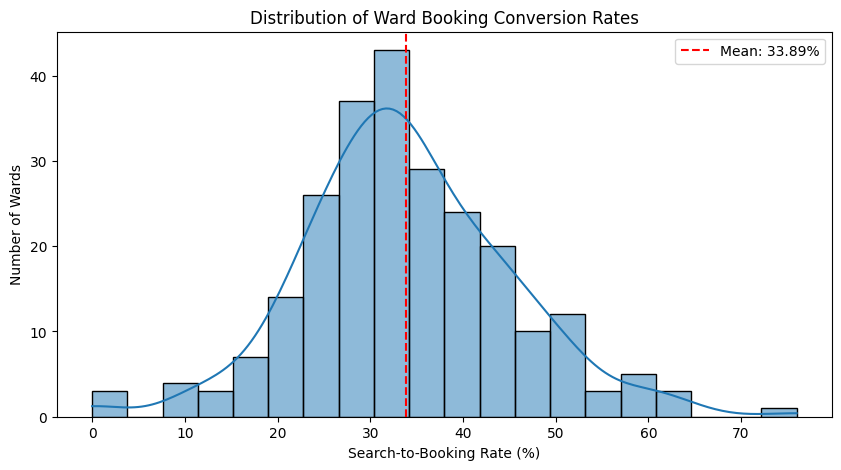

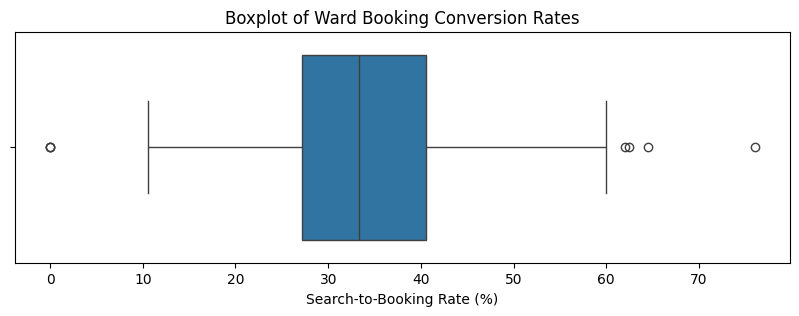

Mean: 0.3389
Median: 0.3333
Skewness: 0.2115
Kurtosis: 1.0569

Wards with zero conversion: 3
Wards below 20% conversion: 18
Wards above 50% conversion: 16

IQR lower bound: 0.0718
IQR upper bound: 0.6053
Potential outlier wards: 7


,ward_num,ward_searches,ward_search_to_booking_rate
162,b_26,8,0.000000
76,b_168,13,0.000000
182,b_44,2,0.000000
235,b_92,50,0.620000
196,b_57,16,0.625000
45,b_14,31,0.645161
49,b_143,25,0.760000


In [ ]:

# ============================================================
# 4.4.4 TARGET DISTRIBUTION ANALYSIS
# ============================================================

import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np

y = model_df[target]

# Histogram
plt.figure(figsize=(10, 5))
sns.histplot(y * 100, bins=20, kde=True)
plt.axvline(
    y.mean() * 100,
    color="red",
    linestyle="--",
    label=f"Mean: {y.mean()*100:.2f}%"
)
plt.xlabel("Search-to-Booking Rate (%)")
plt.ylabel("Number of Wards")
plt.title("Distribution of Ward Booking Conversion Rates")
plt.legend()
plt.show()

# Boxplot
plt.figure(figsize=(10, 3))
sns.boxplot(x=y * 100)
plt.xlabel("Search-to-Booking Rate (%)")
plt.title("Boxplot of Ward Booking Conversion Rates")
plt.show()

# Numerical diagnostics
print("Mean:", round(y.mean(), 4))
print("Median:", round(y.median(), 4))
print("Skewness:", round(y.skew(), 4))
print("Kurtosis:", round(y.kurt(), 4))

print("\nWards with zero conversion:", (y == 0).sum())
print("Wards below 20% conversion:", (y < 0.20).sum())
print("Wards above 50% conversion:", (y > 0.50).sum())

# IQR outlier screening
q1 = y.quantile(0.25)
q3 = y.quantile(0.75)
iqr = q3 - q1

lower = q1 - 1.5 * iqr
upper = q3 + 1.5 * iqr

outliers = model_df[
    (y < lower) | (y > upper)
]

print("\nIQR lower bound:", round(lower, 4))
print("IQR upper bound:", round(upper, 4))
print("Potential outlier wards:", len(outliers))

display(
    outliers[
        ["ward_num", "ward_searches", target]
    ].sort_values(target)
)


**4.4.4 Key Findings and Interpretation**

- **Target Distribution:** Booking conversion rates are approximately bell-shaped, with most wards between 25% and 45%. The mean conversion rate is 33.89%, with slight positive skewness (0.2115).
- **Outlier Detection:** Using the IQR method, 7 outlier wards were identified, with conversion rates below 7.18% or above 60.53%.
- **Low Search Volume:** All 7 outlier wards have 50 or fewer searches, meaning their conversion rates may be less reliable due to limited data.
- **Outlier Handling:** All 7 wards will be retained because these values may represent genuine business activity rather than data errors.
- **Modeling Strategy:** We will compare regular regression with search-volume-weighted regression to account for differences in the reliability of ward conversion rates.

**Conclusion:** The target is suitable for initial regression modeling. However, low-volume wards require careful evaluation, and the model's ability to predict future conversion remains unverified.

### 4.4.5 Search-Volume Reliability Diagnostics

**Objective:** Investigate whether extreme ward-level conversion rates are concentrated in wards with low search volumes.

**Method:** Examine the relationship between search counts and conversion rates, and summarize conversion across search-volume groups.

**Business relevance:** Wards with very few searches may exhibit unstable conversion percentages. These observations should be assessed carefully rather than automatically removed.

**Modeling consideration:** Compare equal-ward modeling with search-volume-weighted alternatives during model evaluation. Search volume indicates the precision of an observed rate but does not, by itself, prove the rate is accurate or free of bias.

SEARCH-VOLUME GROUP SUMMARY:


,search_group,wards,total_searches,mean_conversion,std_conversion,min_conversion,max_conversion
0,1-20,46,529,0.3323,0.1495,0.0000,0.6250
1,21-50,79,2725,0.3585,0.1293,0.1071,0.7600
2,51-100,51,3760,0.3422,0.0867,0.1111,0.5172
3,101-500,58,12453,0.3333,0.0663,0.1810,0.4957
4,500+,10,16645,0.2290,0.0594,0.1144,0.2949


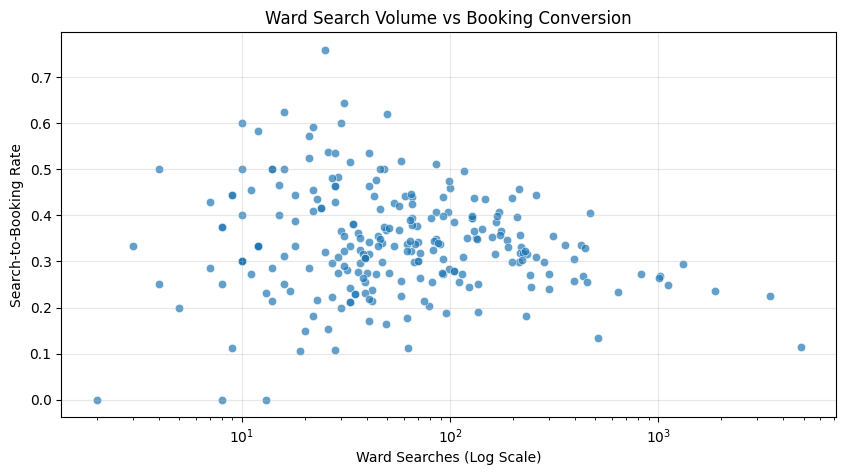

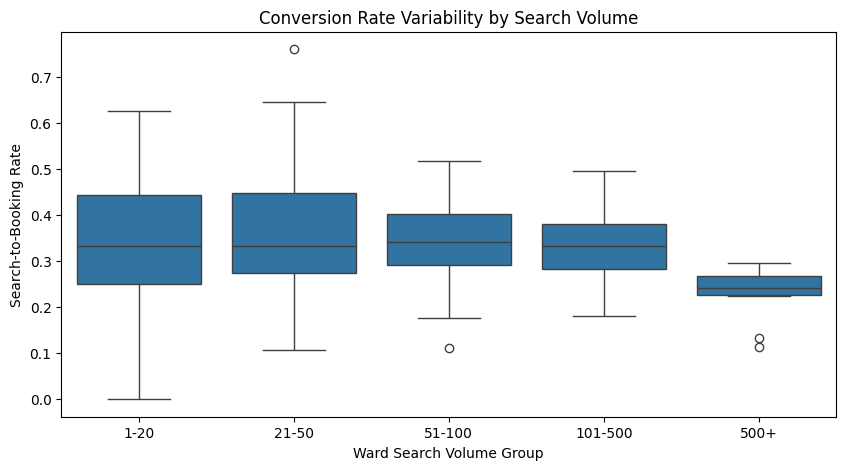

Equal-ward mean conversion: 0.3389
Search-weighted conversion: 0.2751
Wards with <= 50 searches: 125


In [ ]:

# ============================================================
# 4.4.5 SEARCH-VOLUME RELIABILITY DIAGNOSTICS
# ============================================================

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Read-only diagnostic copy
volume_df = model_df[
    ["ward_num", "ward_searches", target]
].copy()

# Search-volume groups
volume_df["search_group"] = pd.cut(
    volume_df["ward_searches"],
    bins=[0, 20, 50, 100, 500, np.inf],
    labels=[
        "1-20", "21-50", "51-100",
        "101-500", "500+"
    ],
    include_lowest=True
)

# Group-level summary
volume_summary = (
    volume_df.groupby(
        "search_group", observed=True
    )
    .agg(
        wards=("ward_num", "count"),
        total_searches=("ward_searches", "sum"),
        mean_conversion=(target, "mean"),
        std_conversion=(target, "std"),
        min_conversion=(target, "min"),
        max_conversion=(target, "max")
    )
    .reset_index()
)

print("SEARCH-VOLUME GROUP SUMMARY:")
display(volume_summary.round(4))

# Search volume vs conversion
plt.figure(figsize=(10, 5))

sns.scatterplot(
    data=volume_df,
    x="ward_searches",
    y=target,
    alpha=0.7
)

plt.xscale("log")
plt.xlabel("Ward Searches (Log Scale)")
plt.ylabel("Search-to-Booking Rate")
plt.title("Ward Search Volume vs Booking Conversion")
plt.grid(alpha=0.3)
plt.show()

# Group-wise conversion distribution
plt.figure(figsize=(10, 5))

sns.boxplot(
    data=volume_df,
    x="search_group",
    y=target
)

plt.xlabel("Ward Search Volume Group")
plt.ylabel("Search-to-Booking Rate")
plt.title("Conversion Rate Variability by Search Volume")
plt.show()

# Volume-weighted conversion summary
weighted_conversion = np.average(
    volume_df[target],
    weights=volume_df["ward_searches"]
)

print(
    "Equal-ward mean conversion:",
    round(volume_df[target].mean(), 4)
)

print(
    "Search-weighted conversion:",
    round(weighted_conversion, 4)
)

print(
    "Wards with <= 50 searches:",
    (volume_df["ward_searches"] <= 50).sum()
)


**Why this step matters for NammaFlow**

Suppose two Bengaluru wards have different conversion rates:
- Ward A: 2 bookings from 4 searches = 50%.
- Ward B: 500 bookings from 1,000 searches = 50%.

Both have the same observed conversion percentage, but Ward B provides much more evidence about the underlying conversion probability, assuming comparable search behavior.

This distinction will matter when we select a regression strategy and interpret model errors.

**4.4.5 Key Findings and Interpretation**

- **Search Volume:** 125 of 244 wards have 50 or fewer searches, indicating that many wards have relatively limited demand observations.
- **Conversion Variability:** Low-search wards show greater variation in conversion rates, while high-search wards have more stable observed rates.
- **High-Demand Challenge:** The 10 wards with more than 500 searches have an average conversion rate of only 22.90%, suggesting potential operational improvement opportunities.
- **Weighted vs Unweighted Conversion:** Average ward conversion is 33.89%, but search-weighted conversion is only 27.51%, showing that high-volume wards perform worse overall.
- **Modeling Decision:** Retain all wards and compare standard regression with search-volume-weighted regression during model evaluation.

**Conclusion:** Search volume is an important factor when interpreting ward-level conversion. NammaFlow should evaluate both prediction accuracy across wards and performance weighted by search volume.

### 4.4.6 Feature Relationship and Correlation Analysis

**Objective:** Examine the relationships between selected predictor variables and ward-level booking conversion.

**Method:** Calculate Pearson and Spearman correlations, visualize the correlation matrix, and examine relationships between demand, driver supply, and booking conversion.

**Business relevance:** Understand whether demand and driver availability are associated with booking conversion across Bengaluru wards.

**Modeling consideration:** Correlation does not imply causation. Highly correlated predictors may require further examination, particularly for interpretable linear regression models.

PEARSON CORRELATION WITH TARGET:


,ward_search_to_booking_rate
ward_search_to_booking_rate,1.0000
has_cab_supply,-0.0067
supply_vehicle_coverage,-0.0067
active_drvr_auto_cab,-0.0741
ward_searches,-0.1967



SPEARMAN CORRELATION WITH TARGET:


,ward_search_to_booking_rate
ward_search_to_booking_rate,1.0000
has_cab_supply,-0.0048
supply_vehicle_coverage,-0.0048
active_drvr_auto_cab,-0.0187
ward_searches,-0.1132


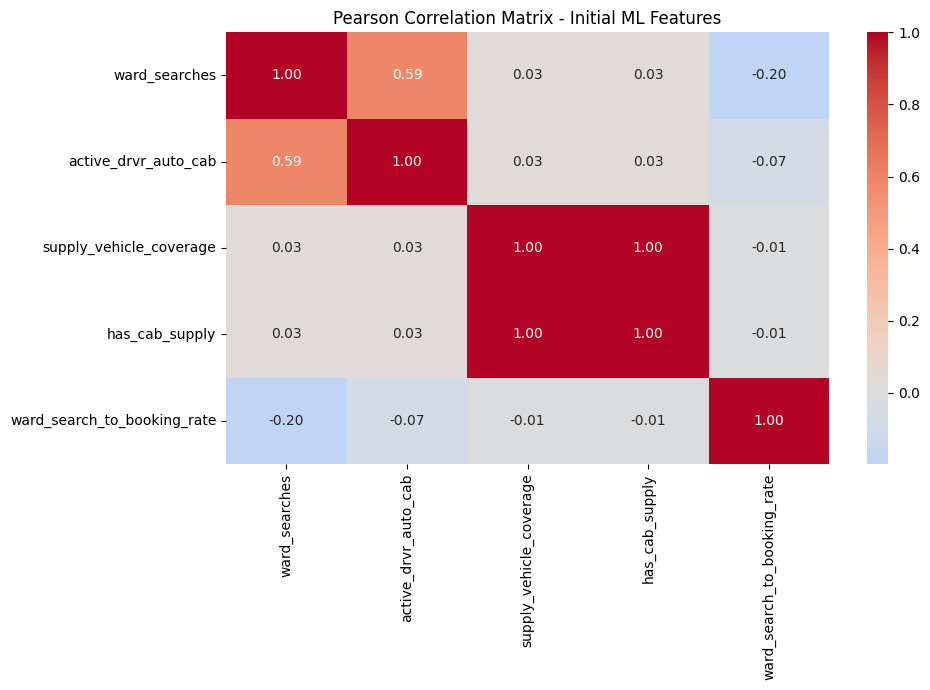

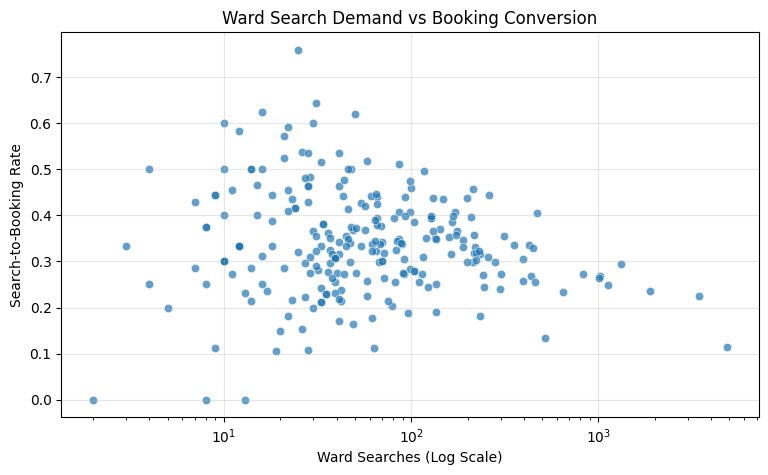

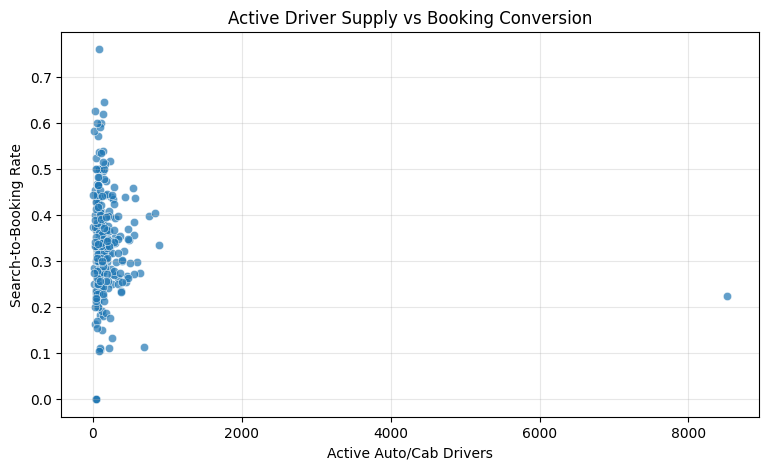


FEATURE-TO-FEATURE CORRELATION:


,ward_searches,active_drvr_auto_cab,supply_vehicle_coverage,has_cab_supply
ward_searches,1.0000,0.5895,0.0304,0.0304
active_drvr_auto_cab,0.5895,1.0000,0.0315,0.0315
supply_vehicle_coverage,0.0304,0.0315,1.0000,1.0000
has_cab_supply,0.0304,0.0315,1.0000,1.0000


In [ ]:

# ============================================================
# 4.4.6 FEATURE RELATIONSHIP & CORRELATION ANALYSIS
# ============================================================

import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt

# Selected modeling features and target
analysis_cols = initial_features + [target]

corr_df = model_df[analysis_cols].copy()

# Pearson correlation
pearson_corr = corr_df.corr(method="pearson")

print("PEARSON CORRELATION WITH TARGET:")
display(
    pearson_corr[target]
    .sort_values(ascending=False)
    .round(4)
)

# Spearman correlation
spearman_corr = corr_df.corr(method="spearman")

print("\nSPEARMAN CORRELATION WITH TARGET:")
display(
    spearman_corr[target]
    .sort_values(ascending=False)
    .round(4)
)

# Correlation heatmap
plt.figure(figsize=(10, 7))

sns.heatmap(
    pearson_corr,
    annot=True,
    fmt=".2f",
    cmap="coolwarm",
    center=0
)

plt.title("Pearson Correlation Matrix - Initial ML Features")
plt.tight_layout()
plt.show()

# Demand vs booking conversion
plt.figure(figsize=(9, 5))

sns.scatterplot(
    data=model_df,
    x="ward_searches",
    y=target,
    alpha=0.7
)

plt.xscale("log")
plt.title("Ward Search Demand vs Booking Conversion")
plt.xlabel("Ward Searches (Log Scale)")
plt.ylabel("Search-to-Booking Rate")
plt.grid(alpha=0.3)
plt.show()

# Driver supply vs booking conversion
plt.figure(figsize=(9, 5))

sns.scatterplot(
    data=model_df,
    x="active_drvr_auto_cab",
    y=target,
    alpha=0.7
)

plt.title("Active Driver Supply vs Booking Conversion")
plt.xlabel("Active Auto/Cab Drivers")
plt.ylabel("Search-to-Booking Rate")
plt.grid(alpha=0.3)
plt.show()

# Check predictor-to-predictor correlations
print("\nFEATURE-TO-FEATURE CORRELATION:")
display(
    pearson_corr.loc[
        initial_features, initial_features
    ].round(4)
)


**4.4.6 Key Findings and Interpretation**

- **Search Demand:** A weak negative correlation (-0.1967) indicates that wards with higher search demand tend to have slightly lower booking conversion rates.
- **Driver Supply:** Active drivers show a very weak negative correlation (-0.0741), suggesting that driver count alone may not explain booking conversion.
- **Feature Redundancy:** `supply_vehicle_coverage` and `has_cab_supply` have a perfect correlation (1.0), indicating redundant information that needs further investigation.
- **Demand vs Supply:** Search volume and active driver count have a moderate positive correlation (0.5895), meaning busier wards generally have more active drivers.
- **Extreme Values:** One ward has over 8,000 active drivers, which requires validation before modeling.

**Conclusion:** The initial predictors show weak individual relationships with booking conversion. We will investigate redundant features and extreme driver counts before finalizing our ML dataset. Correlation alone does not establish causation or predictive performance.

### 4.4.7 Feature Redundancy and Extreme-Value Audit

**Objective:** Investigate highly correlated predictors and unusually large driver-supply values before model training.

**Key findings from correlation analysis:**
- Search demand has a weak negative relationship with booking conversion (Pearson = -0.1967).
- Active driver supply has a very weak negative relationship with booking conversion (-0.0741).
- Supply coverage and cab availability are perfectly correlated (1.0000), requiring further inspection.
- Search volume and active driver supply show moderate positive correlation (0.5895).

**Next action:** Verify redundant feature values, examine driver-count extremes, and finalize a defensible predictor set without modifying the original engineered dataset.

In [ ]:

# ============================================================
# 4.4.7 FEATURE REDUNDANCY AND EXTREME-VALUE AUDIT
# ============================================================

import pandas as pd
import numpy as np

# 1. Examine unique values and relationships
print("SUPPLY FEATURE VALUE COUNTS:")

for col in [
    "supply_vehicle_coverage",
    "has_cab_supply"
]:
    print(f"\n{col}:")
    print(model_df[col].value_counts(dropna=False).sort_index())

print("\nSUPPLY FEATURE CROSS-TABULATION:")
display(
    pd.crosstab(
        model_df["supply_vehicle_coverage"],
        model_df["has_cab_supply"],
        dropna=False
    )
)

# 2. Test exact equality
are_equal = model_df[
    "supply_vehicle_coverage"
].equals(model_df["has_cab_supply"])

print("\nAre both columns identical?", are_equal)

# 3. Inspect extreme driver-supply wards
print("\nTOP 10 WARDS BY ACTIVE DRIVER SUPPLY:")

display(
    model_df[
        [
            "ward_num",
            "ward_searches",
            "active_drvr_auto_cab",
            "supply_vehicle_coverage",
            "has_cab_supply",
            target
        ]
    ]
    .sort_values(
        "active_drvr_auto_cab",
        ascending=False
    )
    .head(10)
)

# 4. Driver count summary
print("\nDRIVER COUNT DISTRIBUTION:")
display(
    model_df["active_drvr_auto_cab"].describe(
        percentiles=[0.50, 0.75, 0.90, 0.95, 0.99]
    )
)

# 5. Verify driver count is nonnegative
print(
    "\nNegative driver counts:",
    (model_df["active_drvr_auto_cab"] < 0).sum()
)

# 6. Check whether modeling variables are finite
numeric_df = model_df.select_dtypes(include=np.number)

print(
    "\nInfinite numeric values:",
    np.isinf(numeric_df.to_numpy()).sum()
)


SUPPLY FEATURE VALUE COUNTS:

supply_vehicle_coverage:
supply_vehicle_coverage
1      2
2    242
Name: count, dtype: int64

has_cab_supply:
has_cab_supply
0      2
1    242
Name: count, dtype: int64

SUPPLY FEATURE CROSS-TABULATION:


has_cab_supply,0,1
supply_vehicle_coverage,,
1,2,0
2,0,242



Are both columns identical? False

TOP 10 WARDS BY ACTIVE DRIVER SUPPLY:


,ward_num,ward_searches,active_drvr_auto_cab,supply_vehicle_coverage,has_cab_supply,ward_search_to_booking_rate
243,w_0,3460,8519,2,1,0.224277
17,b_114,355,892,2,1,0.335211
19,b_116,472,835,2,1,0.404661
18,b_115,168,752,2,1,0.398810
91,b_181,4862,686,2,1,0.114356
32,b_128,300,628,2,1,0.273333
13,b_110,198,598,2,1,0.297980
221,b_8,199,571,2,1,0.437186
8,b_106,216,554,2,1,0.356481
10,b_108,166,547,2,1,0.385542



DRIVER COUNT DISTRIBUTION:


,active_drvr_auto_cab
count,244.000000
mean,200.659836
std,555.865724
min,1.000000
50%,116.000000
75%,211.250000
90%,379.300000
95%,500.350000
99%,799.310000
max,8519.000000



Negative driver counts: 0

Infinite numeric values: 0


**4.4.7 Key Findings and Interpretation**

- **Feature Redundancy:** `supply_vehicle_coverage` and `has_cab_supply` are perfectly correlated because one is exactly the other plus 1. We will retain `has_cab_supply` and remove the redundant feature from the initial model.
- **Limited Feature Variation:** Cab supply is present in 242 of 244 wards, so this feature may have limited predictive value.
- **Extreme Driver Supply:** Ward `w_0` has 8,519 active drivers, compared with a median of 116. This unusual observation requires further investigation.
- **Data Quality:** No negative driver counts or infinite numeric values were found.

**Conclusion:** The initial dataset contains one redundant predictor and one extreme driver-supply observation. Both will be handled carefully before model training, without automatically deleting valid ward data.

**Validate ward w_0**

In [ ]:

# ============================================================
# 4.4.8 W_0 SOURCE CONSISTENCY CHECK
# ============================================================

import pandas as pd
from pathlib import Path

# Repository location
repo_path = Path("/content/NammaFlow")

# Source dataset paths
driver_path = (
    repo_path / "data/processed/driver_supply_clean.csv"
)

funnel_path = (
    repo_path / "data/processed/ward_funnel_clean.csv"
)

# Load source files
driver_supply_check = pd.read_csv(driver_path)
ward_funnel_check = pd.read_csv(funnel_path)

# Check source columns
print("DRIVER SUPPLY COLUMNS:")
print(driver_supply_check.columns.tolist())

print("\nWARD FUNNEL COLUMNS:")
print(ward_funnel_check.columns.tolist())

# Inspect W_0
print("\nW_0 DRIVER SUPPLY SOURCE RECORDS:")
display(
    driver_supply_check.loc[
        driver_supply_check["ward_num"] == "w_0"
    ]
)

print("\nW_0 FUNNEL SOURCE RECORDS:")
display(
    ward_funnel_check.loc[
        ward_funnel_check["ward_num"] == "w_0"
    ]
)

# Engineered dataset comparison
print("\nW_0 ENGINEERED FEATURES:")
display(
    ward_ml.loc[
        ward_ml["ward_num"] == "w_0",
        [
            "ward_num",
            "ward_searches",
            "active_drvr_auto_cab",
            "notonride_drvr_auto_cab",
            "onride_drvr_auto_cab",
            "ward_search_to_booking_rate"
        ]
    ]
)


DRIVER SUPPLY COLUMNS:
['ward_num', 'active', 'vehicle_type', 'active_drvr', 'drvr_notonride', 'drvr_onride']

WARD FUNNEL COLUMNS:
['ward_num', 'srch_fr_e', 'srch_which_got_e', 'srch_fr_q', 'srch_which_got_q', 'booking', 'ongng_ride', 'done_ride', 'rides', 'cancel_ride', 'drvr_cancel', 'rider_cancel', 'earning', 'dist', 'avg_dist_pr_trip', 'avg_fare', 'trip_category', 'vehicle_type', 'srch_fr_q_variant', 'srch_which_got_q_variant', 'is_bike', 'is_cab', 'is_auto', 'srch_to_e_rate', 'e_to_q_srch_rate', 'q_accept_rate', 'q_to_bkng_rate', 'cnvr_rate', 'bkng_cancel_rate']

W_0 DRIVER SUPPLY SOURCE RECORDS:


,ward_num,active,vehicle_type,active_drvr,drvr_notonride,drvr_onride
484,w_0,True,Auto,3410,3214,196
485,w_0,True,Cab,5109,4921,188



W_0 FUNNEL SOURCE RECORDS:


,ward_num,srch_fr_e,srch_which_got_e,srch_fr_q,srch_which_got_q,booking,ongng_ride,done_ride,rides,cancel_ride,...,srch_which_got_q_variant,is_bike,is_cab,is_auto,srch_to_e_rate,e_to_q_srch_rate,q_accept_rate,q_to_bkng_rate,cnvr_rate,bkng_cancel_rate
2916,w_0,58,58,57,57,0,0,0,0,0,...,0,False,False,False,1.0000,0.9828,1.0000,0.0,0.0,NaN
2917,w_0,0,0,0,0,0,0,0,0,0,...,0,False,False,True,NaN,NaN,NaN,NaN,NaN,NaN
2918,w_0,0,0,0,0,0,0,0,0,0,...,0,True,False,False,NaN,NaN,NaN,NaN,NaN,NaN
2919,w_0,0,0,0,0,17,3,1,9,11,...,46,False,True,False,NaN,NaN,NaN,NaN,NaN,0.6471
2920,w_0,3401,3387,2588,2159,0,0,0,0,0,...,0,False,False,False,0.9959,0.7641,0.8342,0.0,0.0,NaN
2921,w_0,0,0,0,0,120,14,64,120,37,...,122,False,False,True,NaN,NaN,NaN,NaN,NaN,0.3083
2922,w_0,0,0,0,0,0,0,0,0,0,...,0,True,False,False,NaN,NaN,NaN,NaN,NaN,NaN
2923,w_0,0,0,0,0,639,25,305,427,266,...,2038,False,True,False,NaN,NaN,NaN,NaN,NaN,0.4163
2924,w_0,1,1,1,1,0,0,0,0,0,...,0,False,False,False,1.0000,1.0000,1.0000,0.0,0.0,NaN
2925,w_0,0,0,0,0,0,0,0,0,0,...,1,False,False,True,NaN,NaN,NaN,NaN,NaN,NaN



W_0 ENGINEERED FEATURES:


,ward_num,ward_searches,active_drvr_auto_cab,notonride_drvr_auto_cab,onride_drvr_auto_cab,ward_search_to_booking_rate
243,w_0,3460,8519,8135,384,0.224277


**4.4.8 Key Findings and Interpretation**

- **Source Validation:** Ward `w_0` contains 3,410 Auto drivers and 5,109 Cab drivers, totaling 8,519 active drivers.
- **Consistency Check:** The 8,135 not-on-ride drivers and 384 on-ride drivers correctly sum to 8,519.
- **Demand and Conversion:** The ward recorded 3,460 searches with a booking conversion rate of 22.43%.
- **Outlier Decision:** The extreme driver count matches the processed source data. However, the geographic meaning of `w_0` remains unverified.

**Conclusion:** Retain `w_0` for initial modeling and perform sensitivity analysis later to determine whether this unusual observation significantly affects model performance.

### 4.4.9 Final Initial Feature Selection

**Objective:** Create a clean, non-redundant modeling dataset before train/test splitting.

**Feature decisions:**
- Retain ward search demand and active driver supply.
- Retain cab availability provisionally.
- Remove `supply_vehicle_coverage` because it duplicates information contained in `has_cab_supply`.
- Preserve all 244 wards, including `w_0`, for initial analysis.

**Modeling approach:** Use a separate DataFrame to avoid modifying the original dataset. Investigate the impact of extreme observations during model validation.

In [ ]:

# ============================================================
# 4.4.9 FINAL INITIAL FEATURE SELECTION
# ============================================================

# Final initial predictors
final_features = [
    "ward_searches",
    "active_drvr_auto_cab",
    "has_cab_supply"
]

# Create separate modeling dataset
model_final = model_df[
    ["ward_num"] + final_features + [target]
].copy()

# Validate dimensions and integrity
print("FINAL MODEL DATASET SHAPE:")
print(model_final.shape)

print("\nFINAL MODEL COLUMNS:")
print(model_final.columns.tolist())

print("\nMISSING VALUES:")
print(model_final.isna().sum())

print("\nDUPLICATE WARD IDS:")
print(model_final["ward_num"].duplicated().sum())

print("\nTARGET RANGE:")
print(
    model_final[target].min(),
    model_final[target].max()
)

# Final feature matrix and target
X = model_final[final_features].copy()
y = model_final[target].copy()

print("\nFEATURE MATRIX SHAPE:", X.shape)
print("TARGET SHAPE:", y.shape)

print("\nFINAL MODEL PREVIEW:")
display(model_final.head())

# Validation assertions
assert model_final.shape == (244, 5)
assert not model_final.isna().any().any()
assert model_final["ward_num"].is_unique
assert y.between(0, 1).all()

print("\nAll initial modeling checks passed.")


FINAL MODEL DATASET SHAPE:
(244, 5)

FINAL MODEL COLUMNS:
['ward_num', 'ward_searches', 'active_drvr_auto_cab', 'has_cab_supply', 'ward_search_to_booking_rate']

MISSING VALUES:
ward_num                       0
ward_searches                  0
active_drvr_auto_cab           0
has_cab_supply                 0
ward_search_to_booking_rate    0
dtype: int64

DUPLICATE WARD IDS:
0

TARGET RANGE:
0.0 0.76

FEATURE MATRIX SHAPE: (244, 3)
TARGET SHAPE: (244,)

FINAL MODEL PREVIEW:


,ward_num,ward_searches,active_drvr_auto_cab,has_cab_supply,ward_search_to_booking_rate
0,b_1,72,336,1,0.263889
1,b_10,188,491,1,0.345745
2,b_100,159,297,1,0.352201
3,b_101,43,86,1,0.441860
4,b_102,127,87,1,0.393701



All initial modeling checks passed.


**4.4.9 Key Findings and Conclusion**

The final initial ML dataset contains 244 unique Bengaluru ward records, 3 predictor features, and 1 target variable (`ward_search_to_booking_rate`).

The redundant supply coverage feature was removed, and all 244 wards were retained, including the unusual `w_0` observation.

The dataset contains no missing values or duplicate ward IDs, and all validation checks passed.

**Conclusion:** The initial dataset is structurally ready for train/test splitting and baseline regression modeling. Its predictive performance and generalizability still need to be evaluated.

## 4.5 Train/Test Splitting and Preprocessing

### 4.5.1 Reproducible Train/Test Split

**Objective:** Divide the final ward-level dataset into separate training and testing sets to evaluate model performance on unseen wards.

**Method:** Use an 80/20 random split with `random_state=42` for reproducibility.

**Important considerations:**
- Preserve ward identifiers for validation and error analysis.
- Keep the target separate from predictor features.
- Check that no ward appears in both datasets.
- Fit preprocessing transformations using training data only.
- Treat test results as cross-sectional generalization, not future-period forecasting.

In [ ]:

# ============================================================
# 4.5.1 REPRODUCIBLE TRAIN/TEST SPLIT
# ============================================================

from sklearn.model_selection import train_test_split

# Separate feature matrix, target and ward identifiers
X = model_final[final_features].copy()
y = model_final[target].copy()
ward_ids = model_final["ward_num"].copy()

# Split all three together to maintain row alignment
(
    X_train, X_test,
    y_train, y_test,
    wards_train, wards_test
) = train_test_split(
    X,
    y,
    ward_ids,
    test_size=0.20,
    random_state=42
)

print("TRAIN/TEST SPLIT SUMMARY")
print("-" * 40)

print("X_train:", X_train.shape)
print("X_test:", X_test.shape)
print("y_train:", y_train.shape)
print("y_test:", y_test.shape)

print("\nTRAIN TARGET SUMMARY:")
display(y_train.describe())

print("\nTEST TARGET SUMMARY:")
display(y_test.describe())

print("\nWARD OVERLAP:")
overlap = set(wards_train) & set(wards_test)
print("Overlapping ward IDs:", len(overlap))

print("\nW_0 ASSIGNMENT:")
print(
    "Training:" if "w_0" in set(wards_train)
    else "Testing:" if "w_0" in set(wards_test)
    else "Not found"
)

# Assertions
assert len(overlap) == 0
assert len(X_train) + len(X_test) == len(model_final)
assert X_train.index.equals(y_train.index)
assert X_test.index.equals(y_test.index)

print("\nTrain/test integrity checks passed.")


TRAIN/TEST SPLIT SUMMARY
----------------------------------------
X_train: (195, 3)
X_test: (49, 3)
y_train: (195,)
y_test: (49,)

TRAIN TARGET SUMMARY:


,ward_search_to_booking_rate
count,195.000000
mean,0.335269
std,0.113401
min,0.000000
25%,0.266119
50%,0.333333
75%,0.399219
max,0.760000



TEST TARGET SUMMARY:


,ward_search_to_booking_rate
count,49.000000
mean,0.353210
std,0.113307
min,0.105263
25%,0.278846
50%,0.333333
75%,0.421053
max,0.645161



WARD OVERLAP:
Overlapping ward IDs: 0

W_0 ASSIGNMENT:
Training:

Train/test integrity checks passed.


**4.5.1 Key Findings and Interpretation**

- **Dataset Split:** The 244 wards were divided into 195 training wards (80%) and 49 testing wards (20%).
- **Target Distribution:** Training and testing conversion averages are 33.53% and 35.32%, with similar medians and standard deviations.
- **Data Leakage Check:** No overlapping ward IDs were found between the two sets.
- **Extreme Observation:** Ward `w_0` is included in the training dataset and will be considered during sensitivity analysis.
- **Reproducibility:** `random_state=42` ensures the same split can be reproduced.

**Conclusion:** The train/test split passed all integrity checks and is ready for preprocessing. This split evaluates performance on held-out wards, not future time periods.

### 4.5.2 Leakage-Safe Feature Preprocessing

**Objective:** Prepare numerical and binary predictor variables for machine learning while preventing preprocessing leakage.

**Method:**
- Apply `log1p` to search demand and driver counts to reduce extreme right-skewness.
- Standardize transformed numerical variables using training-set statistics.
- Preserve the binary cab-supply indicator without scaling.
- Use a Scikit-learn `ColumnTransformer` and `Pipeline` for consistent preprocessing.

**Important:** All transformations are fitted exclusively on training data. Test data remains held out for unbiased final evaluation.

In [ ]:

# ============================================================
# 4.5.2 LEAKAGE-SAFE FEATURE PREPROCESSING
# NAMMAFLOW - COMPLETE CORRECTED VERSION
# ============================================================

import numpy as np

from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import (
    FunctionTransformer,
    StandardScaler
)

# ------------------------------------------------------------
# STEP 1: Define feature groups
# ------------------------------------------------------------

numeric_features = [
    "ward_searches",
    "active_drvr_auto_cab"
]

binary_features = [
    "has_cab_supply"
]

# ------------------------------------------------------------
# STEP 2: Validate input data
# ------------------------------------------------------------

# Log transformation requires nonnegative count values
assert (X_train[numeric_features] >= 0).all().all(), \
    "Negative values detected in training count features!"

assert (X_test[numeric_features] >= 0).all().all(), \
    "Negative values detected in testing count features!"

# ------------------------------------------------------------
# STEP 3: Create numerical preprocessing pipeline
# ------------------------------------------------------------

numeric_pipeline = Pipeline(
    steps=[
        (
            "log_transform",
            FunctionTransformer(
                np.log1p,
                validate=False,
                feature_names_out="one-to-one"
            )
        ),
        (
            "scaler",
            StandardScaler()
        )
    ]
)

# ------------------------------------------------------------
# STEP 4: Create ColumnTransformer
# ------------------------------------------------------------

preprocessor = ColumnTransformer(
    transformers=[
        (
            "numeric",
            numeric_pipeline,
            numeric_features
        ),
        (
            "binary",
            "passthrough",
            binary_features
        )
    ],
    remainder="drop"
)

# ------------------------------------------------------------
# STEP 5: Fit ONLY on training data
# ------------------------------------------------------------

X_train_processed = preprocessor.fit_transform(X_train)

# Use training-fitted transformations on test data
X_test_processed = preprocessor.transform(X_test)

# ------------------------------------------------------------
# STEP 6: Display preprocessing results
# ------------------------------------------------------------

print("PREPROCESSING RESULTS")
print("-" * 40)

print("Training shape:", X_train_processed.shape)
print("Testing shape:", X_test_processed.shape)

print("\nProcessed feature names:")
print(preprocessor.get_feature_names_out())

print("\nTraining numeric feature means:")
print(
    np.round(
        X_train_processed[:, :2].mean(axis=0),
        6
    )
)

print("\nTraining numeric feature standard deviations:")
print(
    np.round(
        X_train_processed[:, :2].std(axis=0),
        6
    )
)

print("\nNon-finite training values:")
print((~np.isfinite(X_train_processed)).sum())

print("\nNon-finite testing values:")
print((~np.isfinite(X_test_processed)).sum())

# ------------------------------------------------------------
# STEP 7: Final validation
# ------------------------------------------------------------

assert X_train_processed.shape == (195, 3), \
    "Unexpected training dataset shape!"

assert X_test_processed.shape == (49, 3), \
    "Unexpected testing dataset shape!"

assert np.isfinite(X_train_processed).all(), \
    "Invalid values found in training data!"

assert np.isfinite(X_test_processed).all(), \
    "Invalid values found in testing data!"

print("\nPreprocessing validation passed.")


PREPROCESSING RESULTS
----------------------------------------
Training shape: (195, 3)
Testing shape: (49, 3)

Processed feature names:
['numeric__ward_searches' 'numeric__active_drvr_auto_cab'
 'binary__has_cab_supply']

Training numeric feature means:
[-0. -0.]

Training numeric feature standard deviations:
[1. 1.]

Non-finite training values:
0

Non-finite testing values:
0

Preprocessing validation passed.


**4.5.2 Key Findings and Interpretation**

- **Preprocessing:** Applied log transformation and standardization to ward searches and active driver counts.
- **Binary Feature:** Preserved `has_cab_supply` without scaling.
- **Leakage Prevention:** Preprocessing parameters were learned only from the training data.
- **Validation:** Training (195 × 3) and testing (49 × 3) datasets contain no missing or infinite values.
- **Result:** Numerical training features have means close to zero and standard deviations of one.

**Conclusion:** Preprocessing was completed successfully, and the transformed datasets are ready for baseline regression modeling.

## 4.6 Baseline Model Development

### 4.6.1 Dummy Regressor Baseline

**Objective:** Establish a simple benchmark for predicting ward-level booking conversion rates.

**Method:** Use `DummyRegressor(strategy="mean")`, which predicts the average training conversion rate for every ward.

**Evaluation:** Apply 5-fold cross-validation on the training dataset using Mean Absolute Error (MAE), Root Mean Squared Error (RMSE), and R².

**Business relevance:** Advanced models should outperform this simple benchmark to demonstrate meaningful predictive value.

**Validation approach:** Reserve the held-out test set for final evaluation after model selection.

In [ ]:

# ============================================================
# 4.6.1 DUMMY REGRESSOR BASELINE
# ============================================================

import numpy as np
import pandas as pd

from sklearn.dummy import DummyRegressor
from sklearn.model_selection import KFold, cross_validate

# 5-fold cross-validation on training data only
cv = KFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

# Model predicts training-fold mean
dummy_model = DummyRegressor(strategy="mean")

# Evaluation metrics
scoring = {
    "MAE": "neg_mean_absolute_error",
    "MSE": "neg_mean_squared_error",
    "R2": "r2"
}

# Cross-validation
dummy_cv = cross_validate(
    dummy_model,
    X_train,
    y_train,
    cv=cv,
    scoring=scoring
)

# Convert negative errors to positive values
dummy_mae = -dummy_cv["test_MAE"]
dummy_rmse = np.sqrt(-dummy_cv["test_MSE"])
dummy_r2 = dummy_cv["test_R2"]

# Results table
dummy_results = pd.DataFrame({
    "Fold": [1, 2, 3, 4, 5],
    "MAE": dummy_mae,
    "RMSE": dummy_rmse,
    "R2": dummy_r2
})

print("DUMMY REGRESSOR - 5 FOLD CV RESULTS")
display(dummy_results.round(4))

print("\nAVERAGE CROSS-VALIDATION PERFORMANCE")
print("MAE:", round(dummy_mae.mean(), 4))
print("RMSE:", round(dummy_rmse.mean(), 4))
print("R2:", round(dummy_r2.mean(), 4))

print("\nMAE IN PERCENTAGE POINTS:")
print(round(dummy_mae.mean() * 100, 2))

# Store results for future comparisons
model_comparison = [{
    "Model": "Dummy Regressor",
    "CV_MAE": dummy_mae.mean(),
    "CV_RMSE": dummy_rmse.mean(),
    "CV_R2": dummy_r2.mean()
}]

print("\nBaseline validation completed.")


DUMMY REGRESSOR - 5 FOLD CV RESULTS


,Fold,MAE,RMSE,R2
0,1,0.0808,0.0962,-0.0006
1,2,0.0987,0.1389,-0.0005
2,3,0.0791,0.0968,-0.0061
3,4,0.0724,0.0969,-0.0042
4,5,0.0990,0.1291,-0.0000



AVERAGE CROSS-VALIDATION PERFORMANCE
MAE: 0.086
RMSE: 0.1116
R2: -0.0023

MAE IN PERCENTAGE POINTS:
8.6

Baseline validation completed.


**4.6.1 Key Findings and Interpretation**

- **Baseline Model:** A Dummy Regressor was evaluated using 5-fold cross-validation on 195 training wards.
- **MAE:** 0.0860, representing an average prediction error of 8.60 percentage points.
- **RMSE:** 0.1116, indicating greater penalties for larger prediction errors.
- **R²:** -0.0023, showing performance approximately equivalent to predicting the mean conversion rate.
- **Benchmark:** Future regression models will be compared against these baseline metrics.

**Conclusion:** The Dummy Regressor establishes a reference for model performance. More advanced models must demonstrate improvement before being considered useful for NammaFlow.

### 4.6.2 Linear Regression Baseline

**Objective:** Evaluate whether a linear model using ward demand and driver-supply features can predict booking conversion more accurately than the Dummy Regressor.

**Method:** Use Linear Regression with log-transformed and standardized numerical predictors. Preprocessing is included inside the model pipeline to prevent data leakage during cross-validation.

**Evaluation:** Apply the same 5-fold cross-validation strategy used for the Dummy Regressor and compare mean MAE, RMSE, and R².

**Important:** The held-out test set remains untouched until final model selection.

In [ ]:

# ============================================================
# 4.6.2 LINEAR REGRESSION BASELINE
# ============================================================

import numpy as np
import pandas as pd

from sklearn.base import clone
from sklearn.linear_model import LinearRegression
from sklearn.pipeline import Pipeline
from sklearn.model_selection import cross_validate

# Build a fresh model pipeline
# Preprocessing is fitted separately within each CV fold
linear_pipeline = Pipeline(
    steps=[
        ("preprocessing", clone(preprocessor)),
        ("model", LinearRegression())
    ]
)

# Use the SAME cv and scoring defined in Section 4.6.1
linear_cv = cross_validate(
    linear_pipeline,
    X_train,
    y_train,
    cv=cv,
    scoring=scoring,
    error_score="raise"
)

# Convert error metrics to positive values
linear_mae = -linear_cv["test_MAE"]
linear_rmse = np.sqrt(-linear_cv["test_MSE"])
linear_r2 = linear_cv["test_R2"]

linear_results = pd.DataFrame({
    "Fold": [1, 2, 3, 4, 5],
    "MAE": linear_mae,
    "RMSE": linear_rmse,
    "R2": linear_r2
})

print("LINEAR REGRESSION - 5 FOLD CV RESULTS")
display(linear_results.round(4))

print("\nAVERAGE CROSS-VALIDATION PERFORMANCE")
print("MAE:", round(linear_mae.mean(), 4))
print("RMSE:", round(linear_rmse.mean(), 4))
print("R2:", round(linear_r2.mean(), 4))

print("\nMAE IN PERCENTAGE POINTS:")
print(round(linear_mae.mean() * 100, 2))

# Compare with Dummy Regressor
comparison = pd.DataFrame([
    {
        "Model": "Dummy Regressor",
        "CV_MAE": dummy_mae.mean(),
        "CV_RMSE": dummy_rmse.mean(),
        "CV_R2": dummy_r2.mean()
    },
    {
        "Model": "Linear Regression",
        "CV_MAE": linear_mae.mean(),
        "CV_RMSE": linear_rmse.mean(),
        "CV_R2": linear_r2.mean()
    }
])

print("\nBASELINE MODEL COMPARISON:")
display(comparison.round(4))

print("\nMAE IMPROVEMENT OVER DUMMY:")
print(
    round(
        (dummy_mae.mean() - linear_mae.mean()) * 100,
        2
    ),
    "percentage points"
)

print("\nLinear Regression cross-validation completed.")


LINEAR REGRESSION - 5 FOLD CV RESULTS


,Fold,MAE,RMSE,R2
0,1,0.0807,0.0962,-0.0000
1,2,0.1000,0.1417,-0.0409
2,3,0.0788,0.0954,0.0233
3,4,0.0771,0.0992,-0.0520
4,5,0.0974,0.1277,0.0227



AVERAGE CROSS-VALIDATION PERFORMANCE
MAE: 0.0868
RMSE: 0.112
R2: -0.0094

MAE IN PERCENTAGE POINTS:
8.68

BASELINE MODEL COMPARISON:


,Model,CV_MAE,CV_RMSE,CV_R2
0,Dummy Regressor,0.0860,0.1116,-0.0023
1,Linear Regression,0.0868,0.1120,-0.0094



MAE IMPROVEMENT OVER DUMMY:
-0.08 percentage points

Linear Regression cross-validation completed.


**4.6.2 Key Findings and Interpretation**

- **Linear Regression Performance:** MAE = 0.0868, RMSE = 0.1120, and R² = -0.0094.
- **Baseline Comparison:** Linear Regression performed slightly worse than the Dummy Regressor (MAE = 0.0860).
- **Predictive Limitations:** The selected features show limited linear predictive signal for ward booking conversion.
- **Modeling Decision:** Continue evaluating regularized and nonlinear models using the same cross-validation strategy without accessing the held-out test set.

**Conclusion:** Linear Regression did not outperform the simple baseline. More flexible models and carefully justified features may be needed to improve performance.

### 4.6.3 Ridge Regression Baseline

**Objective:** Evaluate whether regularization improves prediction of ward-level booking conversion compared with ordinary Linear Regression.

**Method:** Use Ridge Regression with `alpha=1.0`, applying the existing log transformation and standardization inside a leakage-safe Scikit-learn pipeline.

**Evaluation:** Perform 5-fold cross-validation on the training wards and compare MAE, RMSE, and R² against the Dummy Regressor and Linear Regression.

**Note:** This is an initial fixed-parameter Ridge baseline, not a hyperparameter-tuned model.

In [ ]:

# ============================================================
# 4.6.3 RIDGE REGRESSION BASELINE
# ============================================================

import numpy as np
import pandas as pd

from sklearn.base import clone
from sklearn.linear_model import Ridge
from sklearn.pipeline import Pipeline
from sklearn.model_selection import cross_validate

# Create a fresh preprocessing + Ridge pipeline
ridge_pipeline = Pipeline(
    steps=[
        ("preprocessing", clone(preprocessor)),
        ("model", Ridge(alpha=1.0))
    ]
)

# Same five folds and evaluation metrics
ridge_cv = cross_validate(
    ridge_pipeline,
    X_train,
    y_train,
    cv=cv,
    scoring=scoring,
    error_score="raise"
)

# Calculate fold metrics
ridge_mae = -ridge_cv["test_MAE"]
ridge_rmse = np.sqrt(-ridge_cv["test_MSE"])
ridge_r2 = ridge_cv["test_R2"]

ridge_results = pd.DataFrame({
    "Fold": range(1, 6),
    "MAE": ridge_mae,
    "RMSE": ridge_rmse,
    "R2": ridge_r2
})

print("RIDGE REGRESSION - 5 FOLD CV RESULTS")
display(ridge_results.round(4))

# Average performance
print("\nAVERAGE CROSS-VALIDATION PERFORMANCE")
print("MAE:", round(ridge_mae.mean(), 4))
print("RMSE:", round(ridge_rmse.mean(), 4))
print("R2:", round(ridge_r2.mean(), 4))

print("\nMAE IN PERCENTAGE POINTS:")
print(round(ridge_mae.mean() * 100, 2))

# Compare the three baseline models
comparison = pd.DataFrame([
    {
        "Model": "Dummy Regressor",
        "CV_MAE": dummy_mae.mean(),
        "CV_RMSE": dummy_rmse.mean(),
        "CV_R2": dummy_r2.mean()
    },
    {
        "Model": "Linear Regression",
        "CV_MAE": linear_mae.mean(),
        "CV_RMSE": linear_rmse.mean(),
        "CV_R2": linear_r2.mean()
    },
    {
        "Model": "Ridge Regression",
        "CV_MAE": ridge_mae.mean(),
        "CV_RMSE": ridge_rmse.mean(),
        "CV_R2": ridge_r2.mean()
    }
])

print("\nBASELINE MODEL COMPARISON:")
display(comparison.round(4))

print("\nRIDGE MAE IMPROVEMENT OVER DUMMY:")
print(
    round(
        (dummy_mae.mean() - ridge_mae.mean()) * 100,
        2
    ),
    "percentage points"
)

print("\nRidge Regression cross-validation completed.")


RIDGE REGRESSION - 5 FOLD CV RESULTS


,Fold,MAE,RMSE,R2
0,1,0.0806,0.0962,0.0014
1,2,0.1000,0.1415,-0.0378
2,3,0.0789,0.0954,0.0231
3,4,0.0768,0.0991,-0.0500
4,5,0.0975,0.1278,0.0209



AVERAGE CROSS-VALIDATION PERFORMANCE
MAE: 0.0868
RMSE: 0.112
R2: -0.0085

MAE IN PERCENTAGE POINTS:
8.68

BASELINE MODEL COMPARISON:


,Model,CV_MAE,CV_RMSE,CV_R2
0,Dummy Regressor,0.0860,0.1116,-0.0023
1,Linear Regression,0.0868,0.1120,-0.0094
2,Ridge Regression,0.0868,0.1120,-0.0085



RIDGE MAE IMPROVEMENT OVER DUMMY:
-0.08 percentage points

Ridge Regression cross-validation completed.


**4.6.3 Key Findings and Interpretation**

- **Ridge Performance:** MAE = 0.0868, RMSE = 0.1120, and R² = -0.0085.
- **Baseline Comparison:** Ridge performed slightly worse than the Dummy Regressor (MAE = 0.0860).
- **Regularization Impact:** Ridge slightly improved R² compared with Linear Regression but did not meaningfully improve prediction accuracy.
- **Next Decision:** Evaluate nonlinear models using the same training data and cross-validation folds.

**Conclusion:** The current linear models have not demonstrated useful improvement over the mean-prediction baseline. More flexible models will be investigated without changing the held-out test data.

### 4.6.4 Random Forest Regression Baseline

**Objective:** Evaluate whether nonlinear relationships between ward demand, driver supply, and booking conversion improve predictive performance.

**Method:** Train a Random Forest Regressor using 200 trees, maximum tree depth of 4, and a minimum of 5 observations per leaf.

**Evaluation:** Apply the same 5-fold cross-validation strategy and compare MAE, RMSE, and R² against the Dummy Regressor, Linear Regression, and Ridge Regression.

**Considerations:** Random Forest can capture nonlinear interactions but may overfit small datasets. Hyperparameters are preliminary and will only be tuned after initial model comparisons.

In [ ]:

# ============================================================
# 4.6.4 RANDOM FOREST REGRESSION BASELINE
# ============================================================

import numpy as np
import pandas as pd

from sklearn.ensemble import RandomForestRegressor
from sklearn.model_selection import cross_validate

# Initial Random Forest configuration
rf_model = RandomForestRegressor(
    n_estimators=200,
    max_depth=4,
    min_samples_leaf=5,
    random_state=42,
    n_jobs=1
)

# Tree models do not require feature standardization.
# Use the original training features only.
rf_cv = cross_validate(
    rf_model,
    X_train,
    y_train,
    cv=cv,
    scoring=scoring,
    error_score="raise"
)

# Calculate fold metrics
rf_mae = -rf_cv["test_MAE"]
rf_rmse = np.sqrt(-rf_cv["test_MSE"])
rf_r2 = rf_cv["test_R2"]

rf_results = pd.DataFrame({
    "Fold": range(1, 6),
    "MAE": rf_mae,
    "RMSE": rf_rmse,
    "R2": rf_r2
})

print("RANDOM FOREST - 5 FOLD CV RESULTS")
display(rf_results.round(4))

print("\nAVERAGE CROSS-VALIDATION PERFORMANCE")
print("MAE:", round(rf_mae.mean(), 4))
print("RMSE:", round(rf_rmse.mean(), 4))
print("R2:", round(rf_r2.mean(), 4))

print("\nMAE IN PERCENTAGE POINTS:")
print(round(rf_mae.mean() * 100, 2))

# Compare all models
comparison = pd.DataFrame([
    {
        "Model": "Dummy Regressor",
        "CV_MAE": dummy_mae.mean(),
        "CV_RMSE": dummy_rmse.mean(),
        "CV_R2": dummy_r2.mean()
    },
    {
        "Model": "Linear Regression",
        "CV_MAE": linear_mae.mean(),
        "CV_RMSE": linear_rmse.mean(),
        "CV_R2": linear_r2.mean()
    },
    {
        "Model": "Ridge Regression",
        "CV_MAE": ridge_mae.mean(),
        "CV_RMSE": ridge_rmse.mean(),
        "CV_R2": ridge_r2.mean()
    },
    {
        "Model": "Random Forest",
        "CV_MAE": rf_mae.mean(),
        "CV_RMSE": rf_rmse.mean(),
        "CV_R2": rf_r2.mean()
    }
])

print("\nMODEL COMPARISON:")
display(comparison.round(4))

print("\nRANDOM FOREST MAE IMPROVEMENT OVER DUMMY:")
print(
    round(
        (dummy_mae.mean() - rf_mae.mean()) * 100,
        2
    ),
    "percentage points"
)

print("\nRandom Forest cross-validation completed.")


RANDOM FOREST - 5 FOLD CV RESULTS


,Fold,MAE,RMSE,R2
0,1,0.0695,0.0859,0.2038
1,2,0.0943,0.1318,0.0993
2,3,0.0768,0.0923,0.0854
3,4,0.0809,0.1101,-0.2959
4,5,0.1025,0.1321,-0.0468



AVERAGE CROSS-VALIDATION PERFORMANCE
MAE: 0.0848
RMSE: 0.1104
R2: 0.0092

MAE IN PERCENTAGE POINTS:
8.48

MODEL COMPARISON:


,Model,CV_MAE,CV_RMSE,CV_R2
0,Dummy Regressor,0.0860,0.1116,-0.0023
1,Linear Regression,0.0868,0.1120,-0.0094
2,Ridge Regression,0.0868,0.1120,-0.0085
3,Random Forest,0.0848,0.1104,0.0092



RANDOM FOREST MAE IMPROVEMENT OVER DUMMY:
0.12 percentage points

Random Forest cross-validation completed.


**4.6.4 Key Findings and Interpretation**

- **Random Forest Performance:** MAE = 0.0848, RMSE = 0.1104, and R² = 0.0092.
- **Baseline Improvement:** Random Forest reduced prediction error by 0.12 percentage points compared with the Dummy Regressor.
- **Nonlinear Relationships:** Random Forest performed slightly better than Linear and Ridge Regression, suggesting possible nonlinear relationships.
- **Model Stability:** Performance varied across cross-validation folds, indicating limited generalization.
- **Next Decision:** Investigate stronger predictors and assess additional nonlinear models before final model selection.

**Conclusion:** Random Forest is currently the best-performing candidate, but its improvement is too small to establish meaningful predictive value.

### 4.6.5 Gradient Boosting Regression

**Objective:** Evaluate whether sequential ensemble learning improves ward-level booking conversion prediction.

**Method:** Train a Gradient Boosting Regressor using shallow trees, a low learning rate, and a limited number of boosting iterations.

**Evaluation:** Apply the same 5-fold cross-validation strategy and compare MAE, RMSE, and R² with all previous models.

**Consideration:** Gradient Boosting may capture nonlinear interactions but can overfit small datasets. Final model selection will depend on validation performance, stability, and business usefulness.

In [ ]:

# ============================================================
# 4.6.5 GRADIENT BOOSTING REGRESSION
# ============================================================

import numpy as np
import pandas as pd

from sklearn.ensemble import GradientBoostingRegressor
from sklearn.model_selection import cross_validate

# Initial Gradient Boosting configuration
gb_model = GradientBoostingRegressor(
    n_estimators=100,
    learning_rate=0.05,
    max_depth=2,
    min_samples_leaf=5,
    random_state=42
)

# Train using 5-fold cross-validation
gb_cv = cross_validate(
    gb_model,
    X_train,
    y_train,
    cv=cv,
    scoring=scoring,
    error_score="raise"
)

# Calculate metrics
gb_mae = -gb_cv["test_MAE"]
gb_rmse = np.sqrt(-gb_cv["test_MSE"])
gb_r2 = gb_cv["test_R2"]

gb_results = pd.DataFrame({
    "Fold": range(1, 6),
    "MAE": gb_mae,
    "RMSE": gb_rmse,
    "R2": gb_r2
})

print("GRADIENT BOOSTING - 5 FOLD CV RESULTS")
display(gb_results.round(4))

print("\nAVERAGE CROSS-VALIDATION PERFORMANCE")
print("MAE:", round(gb_mae.mean(), 4))
print("RMSE:", round(gb_rmse.mean(), 4))
print("R2:", round(gb_r2.mean(), 4))

print("\nMAE IN PERCENTAGE POINTS:")
print(round(gb_mae.mean() * 100, 2))

# Compare all current models
comparison = pd.DataFrame([
    {
        "Model": "Dummy Regressor",
        "CV_MAE": dummy_mae.mean(),
        "CV_RMSE": dummy_rmse.mean(),
        "CV_R2": dummy_r2.mean()
    },
    {
        "Model": "Linear Regression",
        "CV_MAE": linear_mae.mean(),
        "CV_RMSE": linear_rmse.mean(),
        "CV_R2": linear_r2.mean()
    },
    {
        "Model": "Ridge Regression",
        "CV_MAE": ridge_mae.mean(),
        "CV_RMSE": ridge_rmse.mean(),
        "CV_R2": ridge_r2.mean()
    },
    {
        "Model": "Random Forest",
        "CV_MAE": rf_mae.mean(),
        "CV_RMSE": rf_rmse.mean(),
        "CV_R2": rf_r2.mean()
    },
    {
        "Model": "Gradient Boosting",
        "CV_MAE": gb_mae.mean(),
        "CV_RMSE": gb_rmse.mean(),
        "CV_R2": gb_r2.mean()
    }
])

print("\nMODEL COMPARISON:")
display(
    comparison.sort_values("CV_MAE").round(4)
)

print("\nGRADIENT BOOSTING MAE IMPROVEMENT OVER DUMMY:")
print(
    round(
        (dummy_mae.mean() - gb_mae.mean()) * 100,
        2
    ),
    "percentage points"
)

print("\nGradient Boosting cross-validation completed.")


GRADIENT BOOSTING - 5 FOLD CV RESULTS


,Fold,MAE,RMSE,R2
0,1,0.0695,0.0871,0.1807
1,2,0.0966,0.1335,0.0766
2,3,0.0772,0.0947,0.0382
3,4,0.0798,0.1069,-0.2204
4,5,0.1126,0.1414,-0.1995



AVERAGE CROSS-VALIDATION PERFORMANCE
MAE: 0.0872
RMSE: 0.1127
R2: -0.0249

MAE IN PERCENTAGE POINTS:
8.72

MODEL COMPARISON:


,Model,CV_MAE,CV_RMSE,CV_R2
3,Random Forest,0.0848,0.1104,0.0092
0,Dummy Regressor,0.0860,0.1116,-0.0023
2,Ridge Regression,0.0868,0.1120,-0.0085
1,Linear Regression,0.0868,0.1120,-0.0094
4,Gradient Boosting,0.0872,0.1127,-0.0249



GRADIENT BOOSTING MAE IMPROVEMENT OVER DUMMY:
-0.12 percentage points

Gradient Boosting cross-validation completed.


**4.6.5 Key Findings and Interpretation**

- **Gradient Boosting Performance:** MAE = 0.0872, RMSE = 0.1127, and R² = -0.0249.
- **Baseline Comparison:** Gradient Boosting performed worse than the Dummy Regressor by 0.12 percentage points in MAE.
- **Best Model:** Random Forest currently leads with MAE = 0.0848 and R² = 0.0092.
- **Modeling Limitation:** All five models show weak predictive performance, suggesting that the current three predictors may not adequately explain booking conversion.
- **Next Decision:** Investigate leakage-safe, business-relevant predictors before further model development.

**Conclusion:** Random Forest is the leading initial candidate, but its improvement is small. Feature quality and model stability require further investigation before final evaluation.

### 4.6.6 Demand-to-Supply Feature Investigation

**Objective:** Examine whether search demand relative to active driver supply provides additional information about booking conversion.

**Method:** Construct a searches-per-active-driver ratio for diagnostic analysis and compare its Pearson and Spearman correlations with the existing predictors.

**Business relevance:** Relative demand pressure may be more operationally meaningful than absolute search or driver counts.

**Important considerations:** This analysis is exploratory, and any new feature must be available at prediction time. Feature selection and cross-validation must use training data only, while the held-out test set remains untouched.

DEMAND-TO-SUPPLY FEATURE SUMMARY:


,searches_per_active_driver
count,195.000000
mean,0.694436
std,0.775808
min,0.041667
25%,0.284271
50%,0.452514
75%,0.872698
max,7.087464



MISSING OR INFINITE VALUES:
Missing: 0
Infinite: 0

PEARSON CORRELATION WITH TARGET:


,ward_search_to_booking_rate
ward_searches,-0.1960
active_drvr_auto_cab,-0.0818
searches_per_active_driver,-0.2077
ward_search_to_booking_rate,1.0000



SPEARMAN CORRELATION WITH TARGET:


,ward_search_to_booking_rate
ward_searches,-0.0930
active_drvr_auto_cab,-0.0076
searches_per_active_driver,-0.1351
ward_search_to_booking_rate,1.0000


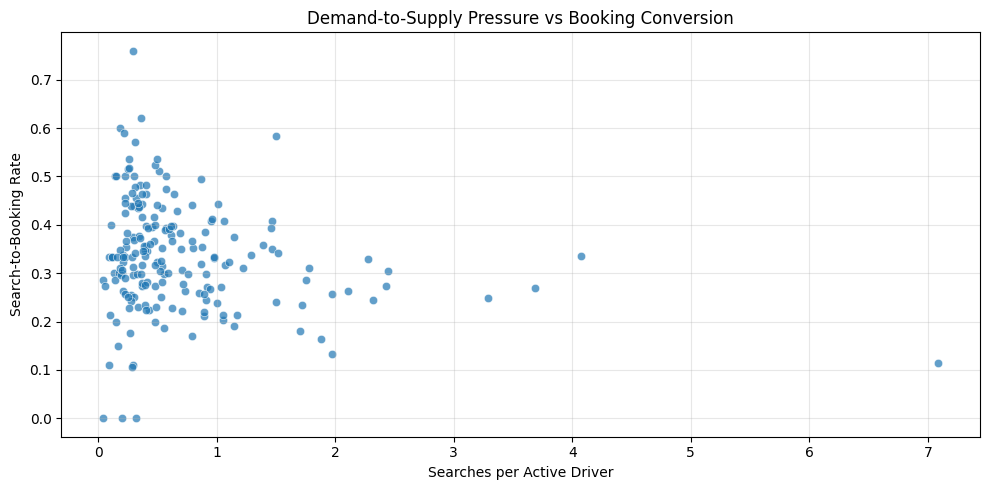


Feature investigation completed.


In [ ]:

# ============================================================
# 4.6.6 DEMAND-TO-SUPPLY FEATURE INVESTIGATION
# TRAINING DATA ONLY
# ============================================================

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Build diagnostic dataset from training observations only
feature_diagnostic = X_train.copy()
feature_diagnostic[target] = y_train

# Calculate demand relative to supply
feature_diagnostic["searches_per_active_driver"] = (
    feature_diagnostic["ward_searches"] /
    feature_diagnostic["active_drvr_auto_cab"]
        .replace(0, np.nan)
)

print("DEMAND-TO-SUPPLY FEATURE SUMMARY:")
display(
    feature_diagnostic[
        "searches_per_active_driver"
    ].describe()
)

print("\nMISSING OR INFINITE VALUES:")
ratio = feature_diagnostic[
    "searches_per_active_driver"
]

print("Missing:", ratio.isna().sum())
print("Infinite:", np.isinf(ratio.dropna()).sum())

# Pearson correlations
print("\nPEARSON CORRELATION WITH TARGET:")
display(
    feature_diagnostic[
        [
            "ward_searches",
            "active_drvr_auto_cab",
            "searches_per_active_driver",
            target
        ]
    ]
    .corr(method="pearson")[target]
    .round(4)
)

# Spearman correlations
print("\nSPEARMAN CORRELATION WITH TARGET:")
display(
    feature_diagnostic[
        [
            "ward_searches",
            "active_drvr_auto_cab",
            "searches_per_active_driver",
            target
        ]
    ]
    .corr(method="spearman")[target]
    .round(4)
)

# Visualize relationship
plt.figure(figsize=(10, 5))

sns.scatterplot(
    data=feature_diagnostic,
    x="searches_per_active_driver",
    y=target,
    alpha=0.7
)

plt.xlabel("Searches per Active Driver")
plt.ylabel("Search-to-Booking Rate")
plt.title("Demand-to-Supply Pressure vs Booking Conversion")
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

print("\nFeature investigation completed.")


**4.6.6 Key Findings and Interpretation**

- **New Feature:** Created `searches_per_active_driver` to measure search demand relative to active driver supply.
- **Data Quality:** All 195 training wards have valid ratio values, with no missing or infinite values.
- **Correlation:** The ratio has a weak negative correlation with booking conversion (Pearson = -0.2077, Spearman = -0.1351).
- **Business Insight:** Higher demand relative to driver supply may be associated with lower conversion, although causation is not established.
- **Next Decision:** Test whether the new feature improves Random Forest performance using the same cross-validation strategy.

**Conclusion:** The demand-to-supply ratio is a potentially useful operational feature, but its actual predictive value must be validated through model comparison.

In [ ]:
# Section 4.6.7.1 — Runtime and Variable Verification

required_variables = [
    "ward_ml",
    "model_df",
    "X_train",
    "X_test",
    "y_train",
    "y_test"
]

for variable in required_variables:
    if variable in globals():
        obj = globals()[variable]
        print(f"✅ {variable}: Available", end="")

        if hasattr(obj, "shape"):
            print(f" | Shape: {obj.shape}")
        else:
            print()
    else:
        print(f"❌ {variable}: Not available")

✅ ward_ml: Available | Shape: (244, 65)
✅ model_df: Available | Shape: (244, 6)
✅ X_train: Available | Shape: (195, 3)
✅ X_test: Available | Shape: (49, 3)
✅ y_train: Available | Shape: (195,)
✅ y_test: Available | Shape: (49,)


### 4.6.7 Random Forest Feature Experiment

**Objective:** Evaluate whether adding a demand-to-supply ratio improves Random Forest prediction accuracy.

**Method:** Compare the original three-feature Random Forest model with a four-feature model incorporating `searches_per_active_driver`.

**Evaluation:** Use the same 5-fold cross-validation strategy and Random Forest hyperparameters, comparing MAE, RMSE, and R².

**Leakage Prevention:** Construct the ratio using only predictor values. Do not use booking outcomes or held-out test observations for feature selection.

**Decision Rule:** Retain the new feature only if it provides meaningful and reasonably consistent improvements in validation performance.

**Feature availability and model configuration audit**

In [ ]:
# Section 4.6.7.2 — Feature and Model Audit

print("=== Original Model Features ===")
print(X_train.columns.tolist())

print("\n=== Potential Ratio Source Columns ===")
candidate_columns = [
    col for col in ward_ml.columns
    if any(term in col.lower()
           for term in ["search", "driver", "drvr", "supply"])
]

print(candidate_columns)

print("\n=== Existing Random Forest Objects ===")
from sklearn.ensemble import RandomForestRegressor

for name, obj in list(globals().items()):
    if isinstance(obj, RandomForestRegressor):
        print(f"\nModel: {name}")
        print("Parameters:", obj.get_params())

print("\n=== Existing Cross-Validation Configuration ===")
from sklearn.model_selection import BaseCrossValidator

for name, obj in list(globals().items()):
    if isinstance(obj, BaseCrossValidator):
        print(f"{name}: {obj}")

=== Original Model Features ===
['ward_searches', 'active_drvr_auto_cab', 'has_cab_supply']

=== Potential Ratio Source Columns ===
['ward_searches', 'ward_searches_got_e', 'ward_search_to_e_rate', 'ward_search_to_q_request_rate', 'ward_search_to_q_received_rate', 'ward_q_supply_gap', 'ward_q_supply_gap_rate', 'ward_search_to_q_received_gap', 'ward_driver_cancellations', 'ward_driver_cancel_share', 'supply_vehicle_coverage', 'active_drvr_auto_cab', 'notonride_drvr_auto_cab', 'onride_drvr_auto_cab', 'has_auto_supply', 'has_cab_supply', 'complete_auto_cab_supply', 'ward_driver_utilization_rate', 'ward_notonride_driver_share', 'ward_log_active_drivers', 'ward_driver_count_gap', 'ward_driver_share_sum', 'ward_search_to_booking_rate', 'ward_search_to_completion_rate', 'ward_search_to_booking_gap', 'ward_search_to_completion_gap', 'searches_per_active_driver', 'q_requests_per_active_driver', 'q_supply_gap_per_active_driver', 'searches_per_notonride_driver', 'q_requests_per_notonride_driver',

**Why are we doing this?**

We want to test whether adding searches_per_active_driver helps predict ward-level booking conversion.

For a fair experiment, the original and new models should use identical training folds, hyperparameters and evaluation metrics. Only the feature set should change.

**4.6.7.3 — Demand-to-Supply Feature Quality Validation**

**Objective:** Validate the existing `searches_per_active_driver`
feature before incorporating it into the Random Forest model.

**Checks:**
1. Confirm feature availability.
2. Identify missing and infinite values.
3. Examine the feature's statistical distribution.
4. Inspect zero-driver wards and confirm valid feature construction.

**Reason:** A feature must be reliable and correctly defined
before being introduced into a machine learning experiment.

In [ ]:
# Section 4.6.7.3 — Feature Quality Validation

import numpy as np
import pandas as pd

feature = "searches_per_active_driver"

assert feature in ward_ml.columns, "Feature not found!"

print("=== Feature Quality Report ===")

print("Total wards:", len(ward_ml))

print("Missing values:",
      ward_ml[feature].isna().sum())

print("Infinite values:",
      np.isinf(ward_ml[feature].dropna()).sum())

print("Negative values:",
      (ward_ml[feature] < 0).sum())

print("\n=== Statistical Summary ===")
print(ward_ml[feature].describe())

print("\n=== Zero Driver Wards ===")
zero_driver_wards = ward_ml[
    ward_ml["active_drvr_auto_cab"] == 0
]

print("Count:", len(zero_driver_wards))

print("\n=== Sample Values ===")
print(
    ward_ml[
        [
            "ward_searches",
            "active_drvr_auto_cab",
            feature
        ]
    ].head(10)
)

=== Feature Quality Report ===
Total wards: 244
Missing values: 2
Infinite values: 0
Negative values: 0

=== Statistical Summary ===
count    242.000000
mean       0.689792
std        0.797263
min        0.041667
25%        0.281705
50%        0.436380
75%        0.791007
max        7.087464
Name: searches_per_active_driver, dtype: float64

=== Zero Driver Wards ===
Count: 0

=== Sample Values ===
   ward_searches  active_drvr_auto_cab  searches_per_active_driver
0             72                   336                    0.214286
1            188                   491                    0.382892
2            159                   297                    0.535354
3             43                    86                    0.500000
4            127                    87                    1.459770
5            172                   117                    1.470085
6             70                   106                    0.660377
7            436                   463                    0.941

**What are we checking?**

The feature measures demand relative to available drivers:

**Searches_per_active_drivers = ward_searches / active_drivers**

For example, 500 searches with 10 active drivers would give a ratio of 50 searches per driver.

A higher ratio may indicate greater demand pressure, although it doesn't necessarily mean fewer bookings.

We must also handle wards with zero drivers carefully because division by zero is undefined.

**4.6.7.4 — Investigation of Missing Demand-to-Supply Ratios**

**Objective:** Identify wards with missing demand-to-supply ratios and determine whether missingness results from incomplete supply coverage.

**Decision Principle:** Preserve all 244 wards where possible without inventing unavailable driver counts or introducing target leakage.

In [ ]:
# Section 4.6.7.4 — Missing Ratio Investigation

feature = "searches_per_active_driver"

missing_ratio = ward_ml.loc[
    ward_ml[feature].isna()
].copy()

print("=== Wards With Missing Ratio ===")

columns_to_check = [
    "ward_num",
    "ward_searches",
    "active_drvr_auto_cab",
    "has_auto_supply",
    "has_cab_supply",
    "complete_auto_cab_supply",
    feature
]

available_columns = [
    col for col in columns_to_check
    if col in ward_ml.columns
]

display(missing_ratio[available_columns])

print("\nMissing ratio count:", len(missing_ratio))

print("\n=== Driver Count Missingness ===")

print(
    ward_ml["active_drvr_auto_cab"]
    .isna()
    .value_counts()
)

=== Wards With Missing Ratio ===


,ward_num,ward_searches,active_drvr_auto_cab,has_auto_supply,has_cab_supply,complete_auto_cab_supply,searches_per_active_driver
63,b_156,4,16,1,0,0,NaN
218,b_77,9,1,1,0,0,NaN



Missing ratio count: 2

=== Driver Count Missingness ===
active_drvr_auto_cab
False    244
Name: count, dtype: int64


**Why this matters**

We have 195 training samples and 49 testing samples. We want to preserve that split and avoid dropping wards unnecessarily.

If missing values reflect incomplete supply coverage, we'll consider a training-fold-only imputation strategy for the new model. That prevents validation data from influencing preprocessing.

**4.6.7.5 — Four-Feature Random Forest Dataset Preparation**

**Objective:** Extend the original three-feature dataset with
`searches_per_active_driver`.

**Method:** Preserve the original train/test split using existing
row indices.

**Missing Values:** Retain NaN values at this stage. Median imputation
will be performed within the cross-validation pipeline to prevent
data leakage.

**Validation:** Confirm unchanged sample counts, row alignment,
target alignment, and feature integrity.

In [ ]:
# Section 4.6.7.5 — Four-Feature Dataset Preparation

feature = "searches_per_active_driver"

# Preserve original feature dataset
X_train_4 = X_train.copy()
X_test_4 = X_test.copy()

# Align new feature by original row indices
X_train_4[feature] = ward_ml.loc[
    X_train.index, feature
]

X_test_4[feature] = ward_ml.loc[
    X_test.index, feature
]

print("=== Four-Feature Dataset ===")

print("Training shape:", X_train_4.shape)
print("Testing shape:", X_test_4.shape)

print("\nFeatures:")
print(X_train_4.columns.tolist())

print("\n=== Missing Values ===")
print("Training:")
print(X_train_4.isna().sum())

print("\nTesting:")
print(X_test_4.isna().sum())

print("\n=== Alignment Checks ===")

assert X_train_4.index.equals(X_train.index)
assert X_test_4.index.equals(X_test.index)

assert len(X_train_4) == len(y_train)
assert len(X_test_4) == len(y_test)

assert X_train_4.shape[1] == 4
assert X_test_4.shape[1] == 4

print("✅ All dataset alignment checks passed")

=== Four-Feature Dataset ===
Training shape: (195, 4)
Testing shape: (49, 4)

Features:
['ward_searches', 'active_drvr_auto_cab', 'has_cab_supply', 'searches_per_active_driver']

=== Missing Values ===
Training:
ward_searches                 0
active_drvr_auto_cab          0
has_cab_supply                0
searches_per_active_driver    1
dtype: int64

Testing:
ward_searches                 0
active_drvr_auto_cab          0
has_cab_supply                0
searches_per_active_driver    1
dtype: int64

=== Alignment Checks ===
✅ All dataset alignment checks passed


**4.6.7.6 — Random Forest Feature Experiment**

**Objective:** Determine whether adding the engineered
demand-to-supply ratio improves Random Forest predictions.

**Models:**
- Baseline: 3 original features
- Experimental: 4 features including searches_per_active_driver

**Evaluation:**
- 5-fold cross-validation on training data only
- Mean Absolute Error (MAE)
- Root Mean Squared Error (RMSE)
- R² Score

**Leakage Prevention:** Median imputation occurs within each
training fold through a scikit-learn Pipeline.

**Decision:** Prefer the additional feature only when validation
improvement is meaningful and reasonably consistent across folds.

In [ ]:
# Section 4.6.7.6 — Random Forest Feature Experiment

import numpy as np
import pandas as pd

from sklearn.base import clone
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.model_selection import cross_validate

# Model A: Original 3-feature Random Forest
baseline_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("model", clone(rf_model))
])

# Model B: New 4-feature Random Forest
experiment_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("model", clone(rf_model))
])

# Same folds and evaluation metrics
scoring = {
    "MAE": "neg_mean_absolute_error",
    "MSE": "neg_mean_squared_error",
    "R2": "r2"
}

def evaluate_rf(pipeline, X, y):
    results = cross_validate(
        pipeline,
        X,
        y,
        cv=cv,
        scoring=scoring,
        n_jobs=-1,
        error_score="raise"
    )

    return pd.DataFrame({
        "MAE": -results["test_MAE"],
        "RMSE": np.sqrt(-results["test_MSE"]),
        "R2": results["test_R2"]
    })

baseline_cv = evaluate_rf(
    baseline_pipeline, X_train, y_train
)

experiment_cv = evaluate_rf(
    experiment_pipeline, X_train_4, y_train
)

comparison = pd.DataFrame({
    "3-Feature RF": baseline_cv.mean(),
    "4-Feature RF": experiment_cv.mean()
})

comparison["Difference (4 - 3)"] = (
    comparison["4-Feature RF"]
    - comparison["3-Feature RF"]
)

print("=== Random Forest CV Comparison ===")
display(comparison.round(4))

print("\n=== Fold-by-Fold Results: 3 Features ===")
display(baseline_cv.round(4))

print("\n=== Fold-by-Fold Results: 4 Features ===")
display(experiment_cv.round(4))

=== Random Forest CV Comparison ===


,3-Feature RF,4-Feature RF,Difference (4 - 3)
MAE,0.0848,0.0855,0.0007
RMSE,0.1104,0.1104,-0.0001
R2,0.0092,0.0016,-0.0076



=== Fold-by-Fold Results: 3 Features ===


,MAE,RMSE,R2
0,0.0695,0.0859,0.2038
1,0.0943,0.1318,0.0993
2,0.0768,0.0923,0.0854
3,0.0809,0.1101,-0.2959
4,0.1025,0.1321,-0.0468



=== Fold-by-Fold Results: 4 Features ===


,MAE,RMSE,R2
0,0.0675,0.0837,0.2430
1,0.0975,0.1327,0.0869
2,0.0734,0.0883,0.1629
3,0.0887,0.1175,-0.4764
4,0.1005,0.1297,-0.0085


**4.6.7.7 — Understanding Evaluation Metrics and Experiment Results**

 **What Do These Metrics Tell Us?**

Our NammaFlow Random Forest model attempts to predict the
search-to-booking conversion rate for each Bengaluru ward.

Imagine a ward where 40% of searches become bookings. If our
model predicts 32%, the prediction error is 8 percentage points.

**1. Mean Absolute Error (MAE)**

MAE measures the average absolute difference between actual
and predicted conversion rates.

- 3-Feature Model: 0.0848 (8.48 percentage points)
- 4-Feature Model: 0.0855 (8.55 percentage points)

**Interpretation:** The original model makes slightly smaller
prediction errors on average. Lower MAE is better.

**2. Root Mean Squared Error (RMSE)**

RMSE measures prediction errors while giving greater
penalty to large mistakes.

- 3-Feature Model: approximately 0.1104
- 4-Feature Model: approximately 0.1104

**Interpretation:** Both models perform almost identically
when larger prediction errors are considered.

**3. R² (Coefficient of Determination)**

R² measures how well predictions explain variation in ward-level
conversion rates compared with predicting the validation-fold mean.

- 3-Feature Model: 0.0092
- 4-Feature Model: 0.0016

**Interpretation:** Both models demonstrate weak predictive
performance. Their average cross-validation R² values are close
to zero, indicating little improvement over a simple mean
prediction benchmark.

#### Business Interpretation

The demand-to-supply ratio was expected to improve predictions
because wards with greater search pressure relative to available
drivers might experience different booking conversion rates.

However, adding this feature did not consistently improve
cross-validation performance.

This suggests that demand-to-supply pressure alone, as represented
by this ratio, provides limited additional predictive value
under the current model configuration.

#### Final Decision

Retain the original three-feature Random Forest model because:

1. It produces slightly lower average MAE.
2. Both models have nearly identical RMSE.
3. The original model achieves slightly higher average R².
4. The additional feature does not demonstrate consistent improvement.

**Important Limitation:** Neither model currently provides strong
predictive accuracy. Further modeling experiments and additional
relevant features may be needed.

The held-out test dataset was not used to select the feature set.

**Final validation**

In [ ]:
# Section 4.6.7.8 — Final Experiment Validation

print("=== Feature Experiment Summary ===")

print("Original features:", X_train.shape[1])
print("Experimental features:", X_train_4.shape[1])

print("\n=== Performance Differences ===")

for metric in ["MAE", "RMSE", "R2"]:
    difference = (
        comparison.loc[metric, "4-Feature RF"]
        - comparison.loc[metric, "3-Feature RF"]
    )
    print(f"{metric}: {difference:+.6f}")

print("\n=== Fold Consistency ===")

mae_improved = (
    experiment_cv["MAE"] < baseline_cv["MAE"]
).sum()

print(f"MAE improved in {mae_improved}/5 folds")

print("\n=== Final Recommendation ===")

if (
    comparison.loc["MAE", "4-Feature RF"]
    < comparison.loc["MAE", "3-Feature RF"]
    and
    comparison.loc["R2", "4-Feature RF"]
    > comparison.loc["R2", "3-Feature RF"]
    and
    mae_improved >= 4
):
    print("Consider retaining the four-feature model.")
else:
    print("Retain the original three-feature Random Forest.")

=== Feature Experiment Summary ===
Original features: 3
Experimental features: 4

=== Performance Differences ===
MAE: +0.000735
RMSE: -0.000051
R2: -0.007571

=== Fold Consistency ===
MAE improved in 3/5 folds

=== Final Recommendation ===
Retain the original three-feature Random Forest.


**4.6.7.9 — Final Feature Experiment Conclusion**

The demand-to-supply feature experiment compared Random Forest
models using three and four predictors.

The additional `searches_per_active_driver` feature did not
demonstrate meaningful or consistent validation improvement.

The four-feature model increased MAE by approximately 0.000735,
produced a negligible RMSE reduction of 0.000051, and reduced
average R² by approximately 0.007571.

MAE improved in only three of five cross-validation folds.

**Decision:** Retain the original three-feature Random Forest.

**Limitation:** Both configurations demonstrated weak explanatory
performance, indicating that further model diagnostics and
experimentation may be necessary.


### 4.6.8 — Model Performance Diagnostics

**Objective:** Evaluate how well the selected three-feature Random Forest predicts ward-level search-to-booking conversion rates, identify systematic prediction errors, and assess whether the model is sufficiently reliable for operational insights.

**Diagnostic Plan:**
1. Generate predictions on the held-out test set.
2. Compare actual and predicted conversion rates.
3. Analyze residuals and potential prediction bias.
4. Investigate high-error wards.
5. Review model limitations and determine next steps.

**Important:** Diagnostics will use the original three-feature Random Forest retained in Section 4.6.7. They will not be used to tune the model on the test set.

In [ ]:

from sklearn.utils.validation import check_is_fitted

print("Model:", rf_model)
print("Training features:", X_train.columns.tolist())
print("Training shape:", X_train.shape)
print("Testing shape:", X_test.shape)

try:
    check_is_fitted(rf_model)
    print("Model status: FITTED")
except Exception as e:
    print("Model status: NOT FITTED")
    print(type(e).__name__)


Model: RandomForestRegressor(max_depth=4, min_samples_leaf=5, n_estimators=200,
                      n_jobs=1, random_state=42)
Training features: ['ward_searches', 'active_drvr_auto_cab', 'has_cab_supply']
Training shape: (195, 3)
Testing shape: (49, 3)
Model status: NOT FITTED
NotFittedError


**Training the original Random Forest**

In [ ]:

# Restore the selected three-feature Random Forest
rf_model.fit(X_train, y_train)

from sklearn.utils.validation import check_is_fitted
check_is_fitted(rf_model)

print("Random Forest trained successfully!")
print("Training samples:", X_train.shape[0])
print("Features used:", rf_model.n_features_in_)


Random Forest trained successfully!
Training samples: 195
Features used: 3


**Why are we doing this?**

The **.fit()** method trains the model using 195 ward observations. Once trained, it can predict conversion rates for the 49 held-out test observations.

We are preserving the original model configuration and not training on the test set.


In [ ]:

# 4.6.8.1 — Generate Test-Set Predictions

import numpy as np
import pandas as pd
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

# Use the retained original three-feature Random Forest
y_pred_rf = rf_model.predict(X_test)

# Evaluate held-out test performance
rf_test_mae = mean_absolute_error(y_test, y_pred_rf)
rf_test_rmse = np.sqrt(mean_squared_error(y_test, y_pred_rf))
rf_test_r2 = r2_score(y_test, y_pred_rf)

print("=== Random Forest Test-Set Diagnostics ===")
print(f"Test observations: {len(y_test)}")
print(f"Predictions: {len(y_pred_rf)}")
print(f"MAE: {rf_test_mae:.6f}")
print(f"RMSE: {rf_test_rmse:.6f}")
print(f"R²: {rf_test_r2:.6f}")

print("\n=== Prediction Range ===")
print(f"Actual: {np.min(y_test):.4f} to {np.max(y_test):.4f}")
print(f"Predicted: {np.min(y_pred_rf):.4f} to {np.max(y_pred_rf):.4f}")


=== Random Forest Test-Set Diagnostics ===
Test observations: 49
Predictions: 49
MAE: 0.090341
RMSE: 0.127207
R²: -0.286664

=== Prediction Range ===
Actual: 0.1053 to 0.6452
Predicted: 0.2249 to 0.4341


**4.6.8.1 — Model Performance Interpretation**

- **MAE (0.090341):** The model's predictions differ from actual ward conversion rates by approximately 9.03 percentage points on average.
- **RMSE (0.127207):** Indicates relatively large prediction errors for some wards.
- **R² (-0.286664):** The model performs worse than a baseline that predicts the test-set mean, indicating weak predictive performance.

**Actual vs. Predicted Conversion Rates:**
- **Actual range:** 10.53% – 64.52%
- **Predicted range:** 22.49% – 43.41%

**Key Insight:** The Random Forest produces a narrower prediction range than the actual values, suggesting that it struggles to capture extreme conversion rates and tends to predict values closer to the average.

**Conclusion:** The model's current predictive performance is insufficient for reliable ward-level forecasting. Further residual analysis and model improvements are necessary.

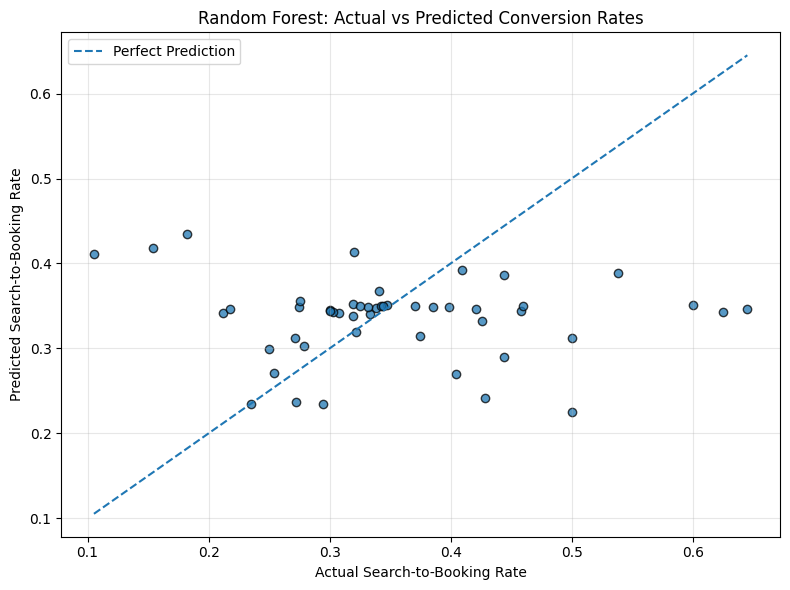

In [ ]:

# 4.6.8.2 — Actual vs. Predicted Conversion Rates

import matplotlib.pyplot as plt
import numpy as np

actual = np.asarray(y_test)
predicted = np.asarray(y_pred_rf)

plt.figure(figsize=(8, 6))

plt.scatter(
    actual,
    predicted,
    alpha=0.75,
    edgecolors="black"
)

# Perfect prediction reference line
lower = min(actual.min(), predicted.min())
upper = max(actual.max(), predicted.max())

plt.plot(
    [lower, upper],
    [lower, upper],
    linestyle="--",
    label="Perfect Prediction"
)

plt.xlabel("Actual Search-to-Booking Rate")
plt.ylabel("Predicted Search-to-Booking Rate")
plt.title("Random Forest: Actual vs Predicted Conversion Rates")

plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()


**4.6.8.2 — Diagnostic Interpretation**

The Actual vs. Predicted scatter plot reveals that Random Forest predictions are concentrated around 30–36%, while actual conversion rates vary from 10.53% to 64.52%.

The model generally overestimates low-conversion wards and underestimates high-conversion wards, indicating prediction compression and limited ability to capture ward-level variation.

**Conclusion:** The current three-feature Random Forest demonstrates weak generalization, consistent with its negative test R² (-0.2867). Further residual diagnostics are required to investigate prediction errors.

**Residual analysis**

Residula = actual - predicted

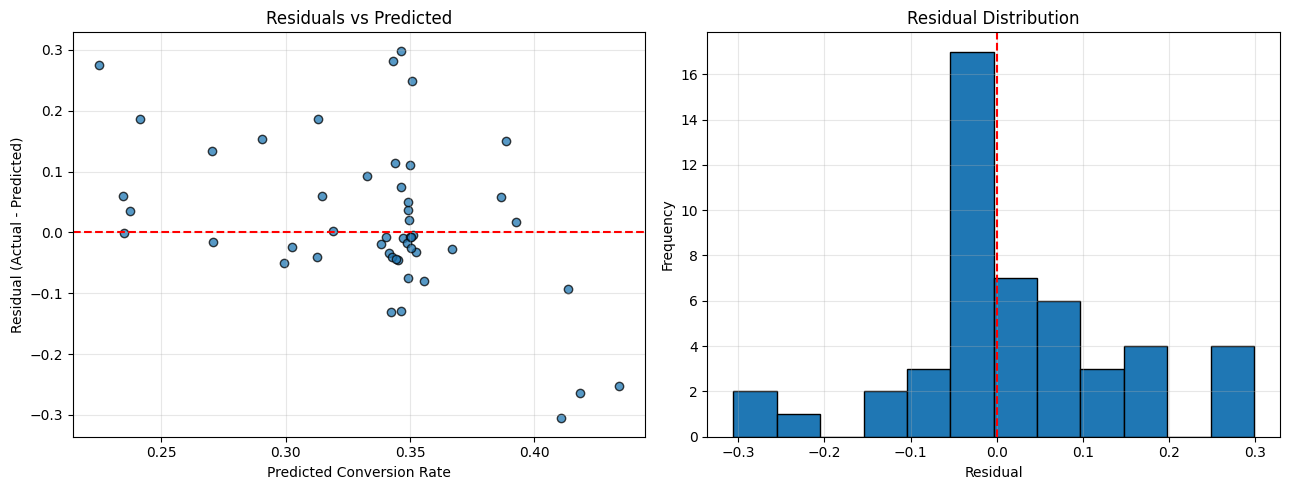

=== Residual Summary ===
Mean Residual: 0.017844
Residual Std: 0.125949
Minimum Residual: -0.305546
Maximum Residual: 0.298733


In [ ]:

# 4.6.8.3 — Random Forest Residual Analysis

import numpy as np
import matplotlib.pyplot as plt

residuals_rf = np.asarray(y_test) - np.asarray(y_pred_rf)

fig, axes = plt.subplots(1, 2, figsize=(13, 5))

# Residuals vs predicted values
axes[0].scatter(y_pred_rf, residuals_rf, alpha=0.75, edgecolors="black")
axes[0].axhline(0, linestyle="--", color="red")
axes[0].set_xlabel("Predicted Conversion Rate")
axes[0].set_ylabel("Residual (Actual - Predicted)")
axes[0].set_title("Residuals vs Predicted")
axes[0].grid(alpha=0.3)

# Residual distribution
axes[1].hist(residuals_rf, bins=12, edgecolor="black")
axes[1].axvline(0, linestyle="--", color="red")
axes[1].set_xlabel("Residual")
axes[1].set_ylabel("Frequency")
axes[1].set_title("Residual Distribution")
axes[1].grid(alpha=0.3)

plt.tight_layout()
plt.show()

print("=== Residual Summary ===")
print(f"Mean Residual: {np.mean(residuals_rf):.6f}")
print(f"Residual Std: {np.std(residuals_rf):.6f}")
print(f"Minimum Residual: {np.min(residuals_rf):.6f}")
print(f"Maximum Residual: {np.max(residuals_rf):.6f}")


**4.6.8.3 — Residual Diagnostic Interpretation**

The Random Forest produced a mean residual of +0.017844, indicating slight overall underprediction, with a residual standard deviation of 0.125949.

Residuals range from -0.305546 to +0.298733, showing that certain ward conversion rates are misestimated by approximately 30 percentage points.

The residual plots reveal substantial error variation and prediction clustering, suggesting that the three-feature model does not adequately capture differences in ward-level conversion behavior.

**Conclusion:** The model demonstrates limited predictive reliability. Further investigation of high-error wards is necessary before considering improvements to feature selection or model complexity.

### 4.6.8.4 — High-Error Ward Investigation

**Objective:** Identify test-set wards with the largest Random Forest prediction errors and investigate whether these errors are associated with differences in demand, driver supply, or cab availability.

Absolute residuals will be used to rank prediction errors, while signed residuals will distinguish overprediction from underprediction.

This diagnostic analysis will help identify model limitations without using the test set for model tuning.

In [ ]:

# 4.6.8.4 — High-Error Ward Investigation

# Preserve test-set indices for ward identification
rf_error_analysis = X_test.copy()

rf_error_analysis["actual_rate"] = np.asarray(y_test)
rf_error_analysis["predicted_rate"] = np.asarray(y_pred_rf)

rf_error_analysis["residual"] = (
    rf_error_analysis["actual_rate"]
    - rf_error_analysis["predicted_rate"]
)

rf_error_analysis["absolute_error"] = (
    rf_error_analysis["residual"].abs()
)

rf_error_analysis["error_direction"] = np.where(
    rf_error_analysis["residual"] > 0,
    "Underprediction",
    np.where(
        rf_error_analysis["residual"] < 0,
        "Overprediction",
        "Exact prediction"
    )
)

# Identify largest prediction errors
top_errors = rf_error_analysis.sort_values(
    "absolute_error",
    ascending=False
).head(10)

print("=== Top 10 Highest-Error Test Observations ===")

display(top_errors.round(4))

print("\n=== Error Direction Counts ===")
print(rf_error_analysis["error_direction"].value_counts())


=== Top 10 Highest-Error Test Observations ===


,ward_searches,active_drvr_auto_cab,has_cab_supply,actual_rate,predicted_rate,residual,absolute_error,error_direction
192,19,86,1,0.1053,0.4108,-0.3055,0.3055,Overprediction
45,31,144,1,0.6452,0.3464,0.2987,0.2987,Underprediction
196,16,31,1,0.6250,0.3429,0.2821,0.2821,Underprediction
195,4,41,1,0.5000,0.2249,0.2751,0.2751,Underprediction
159,26,54,1,0.1538,0.4184,-0.2646,0.2646,Overprediction
67,22,96,1,0.1818,0.4341,-0.2523,0.2523,Overprediction
117,30,104,1,0.6000,0.3508,0.2492,0.2492,Underprediction
120,14,42,1,0.5000,0.3128,0.1872,0.1872,Underprediction
75,7,45,1,0.4286,0.2416,0.1870,0.1870,Underprediction
218,9,1,0,0.4444,0.2904,0.1540,0.1540,Underprediction



=== Error Direction Counts ===
error_direction
Overprediction     27
Underprediction    22
Name: count, dtype: int64


**4.6.8.4 — High-Error Investigation: Findings**

The Random Forest overpredicted 27 of 49 test observations and underpredicted 22.

The largest absolute errors ranged from approximately 26 to 31 percentage points, particularly among observations with unusually low or high conversion rates.

Several high-error observations had relatively low search volumes, suggesting that conversion-rate instability may contribute to prediction difficulty.

**Conclusion:** The model struggles to predict extreme ward-level conversion rates. Further investigation of ward identities, search volumes, and supply characteristics is necessary before drawing operational conclusions.

### 4.6.8.5 — Ward Identity Verification

**Objective:** Map high-error test observations to their original ward identifiers using the source feature dataset.

This step ensures that subsequent ward-level diagnostic findings refer to actual ward records rather than dataframe row positions.

In [ ]:

# 4.6.8.5 — Verify Original Ward Identifiers

print("=== Model Dataframe Columns ===")
print(model_df.columns.tolist())

print("\n=== Source Feature Dataframe Columns ===")
print(ward_ml.columns.tolist())

print("\n=== Index Alignment ===")
print("Model dataframe index unique:", model_df.index.is_unique)
print("Source dataframe index unique:", ward_ml.index.is_unique)
print("Model indices match source rows:",
      model_df.index.isin(ward_ml.index).all())

print("\n=== Source Ward Identifier Preview ===")
display(ward_ml[["ward_num"]].head())

print("\n=== Top Error Row Indices ===")
print(top_errors.index.tolist())


=== Model Dataframe Columns ===
['ward_num', 'ward_searches', 'active_drvr_auto_cab', 'supply_vehicle_coverage', 'has_cab_supply', 'ward_search_to_booking_rate']

=== Source Feature Dataframe Columns ===
['ward_num', 'ward_searches', 'ward_searches_got_e', 'ward_q_requests', 'ward_q_received', 'ward_search_to_e_rate', 'ward_e_to_q_request_rate', 'ward_q_accept_rate', 'ward_search_to_q_request_rate', 'ward_search_to_q_received_rate', 'ward_q_supply_gap', 'ward_q_supply_gap_rate', 'ward_search_to_q_received_gap', 'ward_bookings', 'ward_rides', 'ward_completed_rides', 'ward_cancellations', 'ward_driver_cancellations', 'ward_rider_cancellations', 'ward_earnings', 'ward_booking_to_ride_rate', 'ward_ride_completion_rate', 'ward_booking_completion_rate', 'ward_cancel_per_booking', 'ward_other_cancellations', 'ward_driver_cancel_share', 'ward_rider_cancel_share', 'ward_other_cancel_share', 'ward_earning_per_ride', 'ward_earning_per_completed_ride', 'ward_booking_to_ride_gap', 'ward_ride_comple

,ward_num
0,b_1
1,b_10
2,b_100
3,b_101
4,b_102



=== Top Error Row Indices ===
[192, 45, 196, 195, 159, 67, 117, 120, 75, 218]


 Matching indices alone doesn't guarantee that the ward identifiers are aligned. We'll verify that both dataframes associate the same ward with each index.

**Map errors to actual ward IDs**

In [ ]:

# 4.6.8.5 — Final Ward Identity Mapping

# Verify index-to-ward consistency
matching_wards = (
    model_df["ward_num"].equals(
        ward_ml.loc[model_df.index, "ward_num"]
    )
)

print("Ward identity alignment:", matching_wards)

if not matching_wards:
    raise ValueError("Ward identifiers do not align!")

# Attach verified ward IDs to error observations
top_errors_verified = top_errors.copy()

top_errors_verified.insert(
    0,
    "ward_num",
    model_df.loc[top_errors.index, "ward_num"].to_numpy()
)

# Display only useful diagnostic columns
display(
    top_errors_verified[
        [
            "ward_num",
            "ward_searches",
            "active_drvr_auto_cab",
            "has_cab_supply",
            "actual_rate",
            "predicted_rate",
            "absolute_error",
            "error_direction"
        ]
    ].round(4)
)


Ward identity alignment: True


,ward_num,ward_searches,active_drvr_auto_cab,has_cab_supply,actual_rate,predicted_rate,absolute_error,error_direction
192,b_53,19,86,1,0.1053,0.4108,0.3055,Overprediction
45,b_14,31,144,1,0.6452,0.3464,0.2987,Underprediction
196,b_57,16,31,1,0.6250,0.3429,0.2821,Underprediction
195,b_56,4,41,1,0.5000,0.2249,0.2751,Underprediction
159,b_242,26,54,1,0.1538,0.4184,0.2646,Overprediction
67,b_16,22,96,1,0.1818,0.4341,0.2523,Overprediction
117,b_204,30,104,1,0.6000,0.3508,0.2492,Underprediction
120,b_207,14,42,1,0.5000,0.3128,0.1872,Underprediction
75,b_167,7,45,1,0.4286,0.2416,0.1870,Underprediction
218,b_77,9,1,0,0.4444,0.2904,0.1540,Underprediction


**What this does**

It maps the largest prediction errors to their actual ward identifiers, such as b_181 or b_77, rather than using row numbers such as 192 or 45.

That way, we can connect our machine learning diagnostics to the ward-level analysis we performed in Phase 2.

**4.6.8.5 — Ward Identity Verification: Findings**

Ward identifier alignment between `model_df` and `ward_ml` was verified successfully.

The highest-error wards include `b_53`, `b_14`, `b_57`, `b_56`, and `b_242`, with absolute prediction errors ranging from approximately 26 to 31 percentage points.

All top 10 high-error observations have relatively low recorded search volumes (4–31), suggesting that small-sample variability may contribute to unstable conversion rates.

**Conclusion:** Model errors are concentrated in several low-volume wards. Additional analysis is required to determine whether prediction error varies systematically with ward search volume.

### 4.6.8.6 — Search Volume vs Prediction Error

**Objective:** Investigate the relationship between ward-level search volume and Random Forest prediction error.

This diagnostic evaluates whether wards with fewer searches exhibit larger absolute prediction errors, potentially due to increased variability in observed conversion rates.

The analysis is descriptive and does not establish causation.

=== Search Volume vs Error ===
Spearman correlation: -0.4923


,ward_count,median_searches,mean_absolute_error,median_absolute_error
search_volume_group,,,,
Low,16,18.0,0.1535,0.1519
Medium,16,51.0,0.0735,0.0394
High,17,216.0,0.0468,0.0366


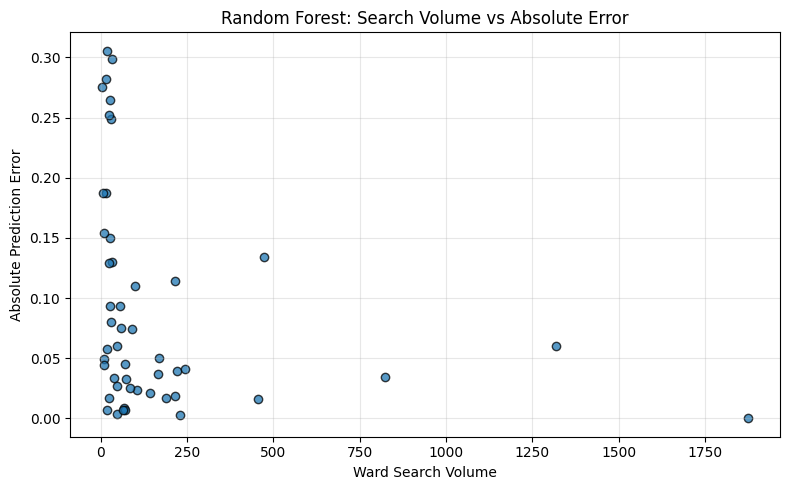

In [ ]:

# 4.6.8.6 — Search Volume vs Prediction Error

import matplotlib.pyplot as plt
import pandas as pd
import numpy as np

diagnostic_df = rf_error_analysis.copy()

# Rank correlation between volume and error
spearman_corr = diagnostic_df[
    ["ward_searches", "absolute_error"]
].corr(method="spearman").iloc[0, 1]

# Three search-volume groups
diagnostic_df["search_volume_group"] = pd.qcut(
    diagnostic_df["ward_searches"].rank(method="first"),
    q=3,
    labels=["Low", "Medium", "High"]
)

volume_summary = diagnostic_df.groupby(
    "search_volume_group",
    observed=True
).agg(
    ward_count=("absolute_error", "size"),
    median_searches=("ward_searches", "median"),
    mean_absolute_error=("absolute_error", "mean"),
    median_absolute_error=("absolute_error", "median")
)

print("=== Search Volume vs Error ===")
print(f"Spearman correlation: {spearman_corr:.4f}")
display(volume_summary.round(4))

plt.figure(figsize=(8, 5))
plt.scatter(
    diagnostic_df["ward_searches"],
    diagnostic_df["absolute_error"],
    alpha=0.75,
    edgecolors="black"
)

plt.xlabel("Ward Search Volume")
plt.ylabel("Absolute Prediction Error")
plt.title("Random Forest: Search Volume vs Absolute Error")
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()


**4.6.8.6 — Search Volume vs Prediction Error: Findings**

A moderate negative Spearman correlation (-0.4923) was observed between ward search volume and absolute prediction error.

Low-volume wards recorded the highest MAE (0.1535), followed by medium-volume wards (0.0735) and high-volume wards (0.0468).

**Key Insight:** Prediction errors are substantially larger in low-search wards, suggesting that small-sample variability may affect conversion-rate predictability.

**Conclusion:** The model performs more accurately in higher-volume wards. Volume-aware evaluation and statistical reliability should be considered in future modeling experiments.

### 4.6.8.7 — Volume-Weighted Error Diagnostics

**Objective:** Evaluate Random Forest prediction errors while accounting for differences in ward search volumes.

The unweighted MAE treats every ward equally, whereas volume-weighted MAE gives higher influence to wards with more searches.

This analysis provides an additional operational perspective on prediction quality without modifying the model or tuning against the held-out test set.

In [ ]:

# 4.6.8.7 — Volume-Weighted Error Diagnostics

import numpy as np

weights = diagnostic_df["ward_searches"].to_numpy()
errors = diagnostic_df["absolute_error"].to_numpy()
residuals = diagnostic_df["residual"].to_numpy()

# Validate search-volume weights
assert np.isfinite(weights).all()
assert (weights >= 0).all()
assert weights.sum() > 0

# Equal weight for every ward
unweighted_mae = np.mean(errors)

# Higher weight for wards with more searches
weighted_mae = np.average(errors, weights=weights)

# Weighted RMSE
weighted_rmse = np.sqrt(
    np.average(residuals ** 2, weights=weights)
)

# Weighted mean residual
weighted_bias = np.average(residuals, weights=weights)

print("=== Volume-Weighted Model Diagnostics ===")
print(f"Unweighted MAE: {unweighted_mae:.6f}")
print(f"Weighted MAE: {weighted_mae:.6f}")
print(f"Weighted RMSE: {weighted_rmse:.6f}")
print(f"Weighted Mean Residual: {weighted_bias:.6f}")

print("\n=== Test-Set Search Volume ===")
print(f"Total Searches: {int(weights.sum())}")
print(f"Minimum Searches: {int(weights.min())}")
print(f"Maximum Searches: {int(weights.max())}")


=== Volume-Weighted Model Diagnostics ===
Unweighted MAE: 0.090341
Weighted MAE: 0.043796
Weighted RMSE: 0.066634
Weighted Mean Residual: 0.022693

=== Test-Set Search Volume ===
Total Searches: 8138
Minimum Searches: 4
Maximum Searches: 1874


**Why this matters**

Suppose two wards have the same conversion-rate prediction error of 10 percentage points, but one has 10 searches and the other has 1,000 searches.

Their unweighted errors are identical. A volume-weighted metric assigns greater importance to the second ward because more searches are associated with its observed conversion rate.

This doesn't replace ordinary MAE. Both metrics answer different business questions, and weighting cannot by itself prove that the model is reliable.

**4.6.8.7 — Volume-Weighted Error Interpretation**

The Random Forest achieved an unweighted MAE of 0.090341 (9.03 percentage points) and a volume-weighted MAE of 0.043796 (4.38 percentage points).

The weighted MAE is approximately 51.5% lower, indicating that prediction errors are smaller when higher-search-volume wards receive greater importance.

The weighted RMSE was 0.066634, while the weighted mean residual of +0.022693 indicates slight underprediction on a search-volume-weighted basis.

**Conclusion:** Model performance is more favorable for high-volume operational activity, but overall ward-level predictive reliability remains limited. Weighted evaluation complements rather than replaces standard metrics.

### 4.6.8.8 — Naive Baseline Comparison

**Objective:** Compare the selected Random Forest against a simple mean-prediction baseline.

The baseline predicts the average conversion rate observed in the training set for every test ward.

Both models are evaluated on the same held-out test set using MAE, RMSE, and R², including search-volume-weighted error metrics.

This comparison helps determine whether Random Forest provides meaningful predictive value beyond a constant prediction.

In [ ]:

# 4.6.8.8 — Random Forest vs Mean Baseline

from sklearn.dummy import DummyRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
import numpy as np
import pandas as pd

# Constant baseline trained only on the training set
baseline_model = DummyRegressor(strategy="mean")
baseline_model.fit(X_train, y_train)

baseline_pred = baseline_model.predict(X_test)

# Use the same test observations and aligned weights
assert X_test.index.equals(diagnostic_df.index)
weights = diagnostic_df["ward_searches"].to_numpy()

results = []

for name, pred in [
    ("Mean Baseline", baseline_pred),
    ("Random Forest", y_pred_rf)
]:
    results.append({
        "Model": name,
        "MAE": mean_absolute_error(y_test, pred),
        "RMSE": np.sqrt(mean_squared_error(y_test, pred)),
        "R2": r2_score(y_test, pred),
        "Weighted_MAE": mean_absolute_error(
            y_test, pred, sample_weight=weights
        ),
        "Weighted_RMSE": np.sqrt(
            mean_squared_error(
                y_test, pred, sample_weight=weights
            )
        )
    })

baseline_comparison = pd.DataFrame(results)

print("=== Random Forest vs Mean Baseline ===")
display(baseline_comparison.round(6))

print("\nTraining Mean Conversion Rate:",
      round(float(np.mean(y_train)), 6))


=== Random Forest vs Mean Baseline ===


,Model,MAE,RMSE,R2,Weighted_MAE,Weighted_RMSE
0,Mean Baseline,0.084156,0.113571,-0.025595,0.066898,0.078847
1,Random Forest,0.090341,0.127207,-0.286664,0.043796,0.066634



Training Mean Conversion Rate: 0.335269


**4.6.8.8 — Baseline Comparison: Findings**

The mean baseline outperformed Random Forest on unweighted MAE (0.0842 vs. 0.0903), RMSE (0.1136 vs. 0.1272), and R² (-0.0256 vs. -0.2867).

However, Random Forest achieved better volume-weighted MAE (0.0438 vs. 0.0669) and weighted RMSE (0.0666 vs. 0.0788).

**Key Insight:** Random Forest performs more favorably when higher-search-volume wards receive greater evaluation weight, but does not outperform a simple mean baseline across all wards equally.

**Conclusion:** The current model is not sufficiently reliable for unrestricted ward-level forecasting. Further training-only validation and careful consideration of the operational evaluation objective are necessary.

### 4.6.8.9 — Final Model Performance Diagnostic Summary

**Model:** Three-feature Random Forest Regressor  
**Evaluation:** 49 held-out Bengaluru wards

**Key Findings:**
- Test MAE: 0.090341; RMSE: 0.127207; R²: -0.286664.
- Predictions were compressed toward moderate conversion rates, with substantial errors at both extremes.
- Absolute prediction error decreased as search volume increased (Spearman correlation: -0.4923).
- Low-volume wards had higher mean absolute error (0.1535) than high-volume wards (0.0468).
- The mean baseline outperformed Random Forest on unweighted metrics.
- Random Forest outperformed the mean baseline on search-volume-weighted MAE and RMSE.

**Model Decision:** Retain the three-feature Random Forest as an experimental candidate, not as a production-ready forecasting model.

**Limitations:** Small ward-level sample size, considerable low-volume conversion-rate variability, limited feature representation, and weak unweighted generalization. These are observed limitations or plausible explanations, not proven causes.

**Next Steps:** Investigate improvements using training-only cross-validation, evaluate volume-aware modeling approaches, and preserve the current held-out test results as exploratory diagnostic evidence. Any model selected after inspecting these results should ultimately be assessed on fresh, untouched validation data.

**Conclusion:** NammaFlow's current machine learning model provides useful diagnostic insights, but further validation is necessary before predictions can safely inform operational decisions.


# 4.7 — Model Improvement Strategy

## Objective

The objective of this section is to investigate and improve the predictive performance, stability, and business usefulness of the ward-level Random Forest regression model developed in earlier sections.

### Current Model Limitations

The selected three-feature Random Forest model produced:

- Test MAE: 0.090341
- Test RMSE: 0.127207
- Test R²: -0.286664
- Volume-weighted MAE: 0.043796
- Volume-weighted baseline MAE: 0.066898

The negative test R² indicates that the model performs worse than the test-set mean predictor under the standard squared-error evaluation.

However, the improved volume-weighted MAE suggests potential usefulness for high-demand wards.

### Improvement Strategy

We will investigate:

1. Model stability through training-only cross-validation.
2. Potential feature improvements using leakage-safe predictors.
3. Simpler regression models and appropriate Random Forest configurations.
4. Performance differences between unweighted and volume-weighted evaluation.
5. Generalization limitations caused by the small ward-level dataset.

### Evaluation Principles

- Preserve the existing train/test split.
- Conduct model selection using training data only.
- Avoid features derived from booking outcomes or target information.
- Compare candidates against simple baselines.
- Do not select models solely from previously observed test results.
- Document all improvements, failures, trade-offs, and limitations.

### Expected Outcome

Identify a defensible prediction strategy that can support NammaFlow's ward-level mobility demand intelligence and operational decision-making.


In [ ]:

# 4.7.1 — Runtime and Model State Verification

required_objects = [
    "ward_ml",
    "model_df",
    "X_train",
    "X_test",
    "y_train",
    "y_test",
    "rf_model"
]

print("NAMMAFLOW — SECTION 4.7 RUNTIME CHECK")
print("=" * 48)

missing_objects = []

for name in required_objects:
    if name in globals():
        obj = globals()[name]
        shape = getattr(obj, "shape", "Available")
        print(f"{name:<15}: {shape}")
    else:
        missing_objects.append(name)
        print(f"{name:<15}: MISSING")

print("=" * 48)

if missing_objects:
    print("Runtime objects missing:", missing_objects)
    print("Re-run the earlier Phase 4 setup and model cells.")
else:
    print("Training features:", list(X_train.columns))
    print("Target:", y_train.name)
    print("Model:", type(rf_model).__name__)
    print("Runtime verification complete.")


NAMMAFLOW — SECTION 4.7 RUNTIME CHECK
ward_ml        : (244, 65)
model_df       : (244, 6)
X_train        : (195, 3)
X_test         : (49, 3)
y_train        : (195,)
y_test         : (49,)
rf_model       : Available
Training features: ['ward_searches', 'active_drvr_auto_cab', 'has_cab_supply']
Target: ward_search_to_booking_rate
Model: RandomForestRegressor
Runtime verification complete.



## 4.7.2 — Training-Only Cross-Validation

### Objective

Evaluate the stability and generalization performance of the selected Random Forest model using 5-fold cross-validation on the training dataset.

### Methodology

- Use 5-fold shuffled KFold cross-validation.
- Keep the existing 49-row test set untouched.
- Evaluate MAE, RMSE, and R² across folds.
- Compare the Random Forest against a DummyRegressor mean baseline.
- Examine the average and variability of validation performance.

This experiment helps determine whether the selected model consistently learns useful predictive relationships or performs inconsistently across different training subsets.


In [ ]:

# 4.7.2 — 5-Fold Training-Only Cross-Validation

import pandas as pd

from sklearn.model_selection import KFold, cross_validate
from sklearn.dummy import DummyRegressor

# Configure five reproducible folds
cv = KFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

# Evaluation metrics
scoring = {
    "MAE": "neg_mean_absolute_error",
    "RMSE": "neg_root_mean_squared_error",
    "R2": "r2"
}

# Evaluate Random Forest using only training data
rf_cv = cross_validate(
    rf_model,
    X_train,
    y_train,
    cv=cv,
    scoring=scoring,
    n_jobs=-1
)

# Evaluate simple mean-prediction baseline
dummy_model = DummyRegressor(strategy="mean")

dummy_cv = cross_validate(
    dummy_model,
    X_train,
    y_train,
    cv=cv,
    scoring=scoring
)

# Store fold-level results
cv_results = pd.DataFrame({
    "Fold": range(1, 6),
    "RF_MAE": -rf_cv["test_MAE"],
    "RF_RMSE": -rf_cv["test_RMSE"],
    "RF_R2": rf_cv["test_R2"],
    "Baseline_MAE": -dummy_cv["test_MAE"],
    "Baseline_RMSE": -dummy_cv["test_RMSE"],
    "Baseline_R2": dummy_cv["test_R2"]
})

print("NAMMAFLOW — 5-FOLD CROSS-VALIDATION")
print("=" * 65)

print(cv_results.round(4).to_string(index=False))

print("\nAVERAGE CROSS-VALIDATION PERFORMANCE")
print("=" * 65)

print(cv_results.drop(columns="Fold").mean().round(4))

print("\nSTANDARD DEVIATION ACROSS FOLDS")
print("=" * 65)

print(
    cv_results[
        ["RF_MAE", "RF_RMSE", "RF_R2"]
    ].std().round(4)
)


NAMMAFLOW — 5-FOLD CROSS-VALIDATION
 Fold  RF_MAE  RF_RMSE   RF_R2  Baseline_MAE  Baseline_RMSE  Baseline_R2
    1  0.0695   0.0859  0.2038        0.0808         0.0962      -0.0006
    2  0.0943   0.1318  0.0993        0.0987         0.1389      -0.0005
    3  0.0768   0.0923  0.0854        0.0791         0.0968      -0.0061
    4  0.0809   0.1101 -0.2959        0.0724         0.0969      -0.0042
    5  0.1025   0.1321 -0.0468        0.0990         0.1291      -0.0000

AVERAGE CROSS-VALIDATION PERFORMANCE
RF_MAE           0.0848
RF_RMSE          0.1104
RF_R2            0.0092
Baseline_MAE     0.0860
Baseline_RMSE    0.1116
Baseline_R2     -0.0023
dtype: float64

STANDARD DEVIATION ACROSS FOLDS
RF_MAE     0.0134
RF_RMSE    0.0216
RF_R2      0.1924
dtype: float64



**4.7.2.1 — Cross-Validation Findings**

Five-fold cross-validation was performed on the 195 training observations using the selected three-feature Random Forest model.

#### Results

| Metric | Random Forest | Mean Baseline |
|---|---:|---:|
| Mean MAE | 0.0848 | 0.0860 |
| Mean RMSE | 0.1104 | 0.1116 |
| Mean R² | 0.0092 | -0.0023 |

#### Interpretation

1. Random Forest marginally outperformed the mean baseline in average MAE and RMSE.

2. Mean validation R² was approximately 0.0092, indicating limited explanatory power.

3. The model achieved positive R² in three folds and negative R² in two folds.

4. The standard deviation of R² was 0.1924, indicating substantial variability in generalization performance.

5. The previous negative holdout-test R² is consistent with the model's observed instability.

#### Conclusion

The current Random Forest demonstrates limited predictive improvement over the mean baseline.

Feature experimentation and model-complexity comparisons are warranted before selecting a final model.

Because previous feature experiments used the holdout test set, these results should not be presented as independent confirmation of the final model.

Subsequent experiments will perform candidate selection on training data only.


In [ ]:

# 4.7.3.1 — Feature Inventory Audit

print("NAMMAFLOW — AVAILABLE FEATURE INVENTORY")
print("=" * 85)

columns = ward_ml.columns.tolist()

for start in range(0, len(columns), 3):
    group = [
        f"{i+1:02d}. {columns[i]}"
        for i in range(start, min(start + 3, len(columns)))
    ]
    print(" | ".join(group))

print("\n" + "=" * 85)
print("Total columns:", len(columns))
print("Total ward records:", len(ward_ml))

print("\nCURRENT MODEL FEATURES:")
for feature in X_train.columns:
    print("-", feature)

print("\nTARGET:")
print(y_train.name)

print("\nCOLUMNS WITH MISSING VALUES:")
missing = ward_ml.isna().sum()
print(missing[missing > 0].to_string())


NAMMAFLOW — AVAILABLE FEATURE INVENTORY
01. ward_num | 02. ward_searches | 03. ward_searches_got_e
04. ward_q_requests | 05. ward_q_received | 06. ward_search_to_e_rate
07. ward_e_to_q_request_rate | 08. ward_q_accept_rate | 09. ward_search_to_q_request_rate
10. ward_search_to_q_received_rate | 11. ward_q_supply_gap | 12. ward_q_supply_gap_rate
13. ward_search_to_q_received_gap | 14. ward_bookings | 15. ward_rides
16. ward_completed_rides | 17. ward_cancellations | 18. ward_driver_cancellations
19. ward_rider_cancellations | 20. ward_earnings | 21. ward_booking_to_ride_rate
22. ward_ride_completion_rate | 23. ward_booking_completion_rate | 24. ward_cancel_per_booking
25. ward_other_cancellations | 26. ward_driver_cancel_share | 27. ward_rider_cancel_share
28. ward_other_cancel_share | 29. ward_earning_per_ride | 30. ward_earning_per_completed_ride
31. ward_booking_to_ride_gap | 32. ward_ride_completion_gap | 33. ward_booking_to_completion_gap
34. ward_ride_booking_mismatch | 35. supply


### 4.7.3.2 — Candidate Feature Screening

#### Objective

Identify potentially useful demand and driver-supply features for improving ward-level booking conversion predictions.

#### Feature Selection Principles

1. Exclude booking, ride-completion, cancellation, and target-derived features.
2. Prioritize demand-volume and driver-supply indicators.
3. Check missing values and feature distributions before modeling.
4. Evaluate feature availability at the intended prediction time.
5. Avoid automatically treating contemporaneous operational indicators as valid future predictors.

The following screening is exploratory. It does not establish that every candidate is leakage-safe.


In [ ]:

# 4.7.3.2 — Candidate Feature Screening

candidate_features = [
    "ward_searches",
    "active_drvr_auto_cab",
    "has_cab_supply",
    "has_auto_supply",
    "complete_auto_cab_supply",
    "supply_vehicle_coverage",
    "notonride_drvr_auto_cab",
    "onride_drvr_auto_cab",
    "ward_log_active_drivers",
    "ward_driver_utilization_rate",
    "ward_notonride_driver_share"
]

# Verify columns exist
missing_cols = [
    col for col in candidate_features
    if col not in ward_ml.columns
]

if missing_cols:
    raise ValueError(
        f"Missing candidate columns: {missing_cols}"
    )

# Prepare feature audit
feature_audit = pd.DataFrame({
    "Feature": candidate_features,
    "Missing": [
        ward_ml[col].isna().sum()
        for col in candidate_features
    ],
    "Unique_Values": [
        ward_ml[col].nunique(dropna=True)
        for col in candidate_features
    ],
    "Min": [
        ward_ml[col].min()
        for col in candidate_features
    ],
    "Median": [
        ward_ml[col].median()
        for col in candidate_features
    ],
    "Max": [
        ward_ml[col].max()
        for col in candidate_features
    ]
})

print("NAMMAFLOW — CANDIDATE FEATURE AUDIT")
print("=" * 85)

print(
    feature_audit.round(4).to_string(index=False)
)

print("\nTotal candidate features:",
      len(candidate_features))


NAMMAFLOW — CANDIDATE FEATURE AUDIT
                     Feature  Missing  Unique_Values    Min   Median       Max
               ward_searches        0            140 2.0000  48.5000 4862.0000
        active_drvr_auto_cab        0            170 1.0000 116.0000 8519.0000
              has_cab_supply        0              2 0.0000   1.0000    1.0000
             has_auto_supply        0              1 1.0000   1.0000    1.0000
    complete_auto_cab_supply        0              2 0.0000   1.0000    1.0000
     supply_vehicle_coverage        0              2 1.0000   2.0000    2.0000
     notonride_drvr_auto_cab        0            165 1.0000  96.0000 8135.0000
        onride_drvr_auto_cab        0             73 0.0000  16.0000  384.0000
     ward_log_active_drivers        0            170 0.6931   4.7621    9.0502
ward_driver_utilization_rate        0            217 0.0000   0.1394    0.4500
 ward_notonride_driver_share        0            217 0.5500   0.8606    1.0000

Total candidate

**Why are we doing this?**

We want to understand whether features such as available drivers, vehicle coverage, and driver utilization offer more predictive information than our original three features.

This audit will tell us whether these indicators have enough variation, contain missing values, or appear redundant. We will also need to confirm their timing before using them in a predictive experiment.


### 4.7.3.3 — Feature Redundancy Validation

#### Objective

Identify mathematically redundant or closely related demand and driver-supply features before model experimentation.

This validation examines:

- Constant supply indicators
- Overlapping vehicle coverage indicators
- Relationships between active, occupied, and available drivers
- Driver utilization and availability shares
- Log-transformed driver supply

Feature redundancy should be investigated to avoid unnecessarily increasing model complexity.

This check does not establish that the features are temporally valid for prediction. That must be assessed separately before modeling.


In [ ]:

# 4.7.3.3 — Feature Redundancy Validation

import numpy as np
import pandas as pd

print("NAMMAFLOW — FEATURE REDUNDANCY CHECK")
print("=" * 65)

checks = {
    "Auto supply always equals 1":
        ward_ml["has_auto_supply"].eq(1),

    "Complete supply equals auto AND cab":
        ward_ml["complete_auto_cab_supply"].eq(
            ward_ml["has_auto_supply"] *
            ward_ml["has_cab_supply"]
        ),

    "Coverage equals auto + cab supply":
        ward_ml["supply_vehicle_coverage"].eq(
            ward_ml["has_auto_supply"] +
            ward_ml["has_cab_supply"]
        ),

    "Active drivers equals onride + notonride":
        np.isclose(
            ward_ml["active_drvr_auto_cab"],
            ward_ml["onride_drvr_auto_cab"] +
            ward_ml["notonride_drvr_auto_cab"]
        ),

    "Utilization equals onride / active":
        np.isclose(
            ward_ml["ward_driver_utilization_rate"],
            ward_ml["onride_drvr_auto_cab"] /
            ward_ml["active_drvr_auto_cab"],
            atol=1e-6
        ),

    "Notonride share equals 1 - utilization":
        np.isclose(
            ward_ml["ward_notonride_driver_share"],
            1 - ward_ml["ward_driver_utilization_rate"],
            atol=1e-6
        ),

    "Log drivers equals log1p(active drivers)":
        np.isclose(
            ward_ml["ward_log_active_drivers"],
            np.log1p(ward_ml["active_drvr_auto_cab"]),
            atol=1e-6
        )
}

for name, matches in checks.items():
    match_percentage = np.mean(matches) * 100
    print(f"{name}: {match_percentage:.2f}%")

print("\nRedundancy validation complete.")


NAMMAFLOW — FEATURE REDUNDANCY CHECK
Auto supply always equals 1: 100.00%
Complete supply equals auto AND cab: 100.00%
Coverage equals auto + cab supply: 100.00%
Active drivers equals onride + notonride: 100.00%
Utilization equals onride / active: 100.00%
Notonride share equals 1 - utilization: 100.00%
Log drivers equals log1p(active drivers): 100.00%

Redundancy validation complete.



**4.7.3.3.1 — Feature Redundancy Findings**

All seven mathematical consistency checks returned 100% across 244 wards.

#### Key Findings

1. `has_auto_supply` is constant and provides no predictive variation.
2. `complete_auto_cab_supply` is equivalent to `has_cab_supply`.
3. `supply_vehicle_coverage` is a deterministic transformation of `has_cab_supply`.
4. Total active drivers equal the sum of on-ride and not-on-ride drivers.
5. Driver utilization and not-on-ride share are complementary.
6. Log-transformed active drivers contain no new raw information, although the transformation may assist some model classes.

#### Modeling Decision

Exclude constant features and avoid unnecessary equivalent supply indicators.

Preserve potentially meaningful driver-availability and utilization information for controlled experiments.

These relationships establish mathematical redundancy, not temporal availability or predictive usefulness.

The next step will validate dataset alignment before constructing training-only feature experiments.


In [ ]:

# 4.7.3.4 — Dataset Alignment and Leakage Safety

import numpy as np

print("NAMMAFLOW — DATASET ALIGNMENT CHECK")
print("=" * 65)

print("Model dataframe columns:")
print(model_df.columns.tolist())

print("\nWard ID uniqueness:")
print("ward_ml:", ward_ml["ward_num"].is_unique)

if "ward_num" in model_df.columns:
    print("model_df:", model_df["ward_num"].is_unique)

print("\nIndex validation:")
print("ward_ml unique index:", ward_ml.index.is_unique)
print("model_df unique index:", model_df.index.is_unique)

print(
    "ward_ml and model_df indexes identical:",
    ward_ml.index.equals(model_df.index)
)

print(
    "Training indexes present in model_df:",
    X_train.index.isin(model_df.index).all()
)

print(
    "Test indexes present in model_df:",
    X_test.index.isin(model_df.index).all()
)

print(
    "Overlapping train/test indexes:",
    len(set(X_train.index) & set(X_test.index))
)

print("\nOriginal training feature alignment:")

if (
    model_df.index.is_unique
    and X_train.index.isin(model_df.index).all()
):
    aligned = np.allclose(
        X_train.to_numpy(),
        model_df.loc[
            X_train.index,
            X_train.columns
        ].to_numpy(),
        equal_nan=True
    )
    print("Training features match model_df:", aligned)
else:
    print("Cannot safely verify index alignment.")

print("\nPotential time/date columns:")
time_cols = [
    c for c in ward_ml.columns
    if any(term in c.lower()
           for term in ["date", "time", "hour"])
]

print(time_cols)

print("\nDataset alignment audit complete.")


NAMMAFLOW — DATASET ALIGNMENT CHECK
Model dataframe columns:
['ward_num', 'ward_searches', 'active_drvr_auto_cab', 'supply_vehicle_coverage', 'has_cab_supply', 'ward_search_to_booking_rate']

Ward ID uniqueness:
ward_ml: True
model_df: True

Index validation:
ward_ml unique index: True
model_df unique index: True
ward_ml and model_df indexes identical: True
Training indexes present in model_df: True
Test indexes present in model_df: True
Overlapping train/test indexes: 0

Original training feature alignment:
Training features match model_df: True

Potential time/date columns:
[]

Dataset alignment audit complete.



**4.7.3.4.1 — Dataset Alignment Findings**

The dataset alignment audit was successfully completed.

#### Results

- 244 unique ward records confirmed.
- Both modeling dataframes have unique indexes.
- `ward_ml` and `model_df` indexes match.
- Training and test indexes are valid.
- Zero overlapping train/test indexes.
- Training feature values match their original modeling records.
- No date or time columns exist in the ward-level feature table.

#### Conclusion

The dataset alignment checks passed, supporting safe row-level feature selection for the next experiment.

However, the ward-level dataset is cross-sectional and aggregated. Temporal availability of the predictors cannot be independently established from this table.

Consequently, the current task is historical ward-level conversion estimation, not validated future forecasting.



### 4.7.3.5 — Controlled Demand-Supply Feature Experiment

#### Objective

Investigate whether a demand-to-active-driver ratio improves the Random Forest model's ability to estimate historical ward-level booking conversion.

#### Experimental Design

Compare the original three-feature model against alternative combinations of demand, driver supply, cab availability, and demand pressure.

#### Validation

- Use the existing 195 training observations only.
- Apply identical five-fold cross-validation splits.
- Compare MAE, RMSE, and R².
- Preserve the existing holdout test set.
- Avoid booking-derived and ride-outcome-derived features.

The pressure ratio is computed from demand and supply measurements only. Its suitability for future prediction would still require temporal validation.


**Demand pressure = ward_searches / active_drivers**

In [ ]:

# 4.7.3.5 — Controlled Feature Experiment

import numpy as np
import pandas as pd

from sklearn.model_selection import KFold, cross_validate
from sklearn.base import clone
from sklearn.dummy import DummyRegressor

# Work only with existing training data
X_experiment = X_train.copy()

# Create a demand-supply pressure feature
X_experiment["demand_per_active_driver"] = (
    X_experiment["ward_searches"] /
    X_experiment["active_drvr_auto_cab"]
        .replace(0, np.nan)
)

# Validate experimental features
assert not X_experiment.isna().any().any(), \
    "Missing values detected in experimental features."

assert X_experiment.index.equals(y_train.index), \
    "Training feature/target indexes do not match."

# Candidate feature combinations
feature_sets = {
    "Original_3": [
        "ward_searches",
        "active_drvr_auto_cab",
        "has_cab_supply"
    ],
    "Demand_Supply_2": [
        "ward_searches",
        "active_drvr_auto_cab"
    ],
    "Demand_Supply_Pressure_3": [
        "ward_searches",
        "active_drvr_auto_cab",
        "demand_per_active_driver"
    ],
    "Original_Plus_Pressure_4": [
        "ward_searches",
        "active_drvr_auto_cab",
        "has_cab_supply",
        "demand_per_active_driver"
    ]
}

cv_experiment = KFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

scoring_experiment = {
    "MAE": "neg_mean_absolute_error",
    "RMSE": "neg_root_mean_squared_error",
    "R2": "r2"
}

experiment_results = []

for name, features in feature_sets.items():

    scores = cross_validate(
        clone(rf_model),
        X_experiment[features],
        y_train,
        cv=cv_experiment,
        scoring=scoring_experiment,
        n_jobs=-1
    )

    experiment_results.append({
        "Feature_Set": name,
        "Feature_Count": len(features),
        "CV_MAE": -scores["test_MAE"].mean(),
        "CV_RMSE": -scores["test_RMSE"].mean(),
        "CV_R2": scores["test_R2"].mean(),
        "CV_R2_STD": scores["test_R2"].std(ddof=1)
    })

# Mean baseline for reference
baseline_scores = cross_validate(
    DummyRegressor(strategy="mean"),
    X_experiment,
    y_train,
    cv=cv_experiment,
    scoring=scoring_experiment
)

experiment_results.append({
    "Feature_Set": "Mean_Baseline",
    "Feature_Count": 0,
    "CV_MAE": -baseline_scores["test_MAE"].mean(),
    "CV_RMSE": -baseline_scores["test_RMSE"].mean(),
    "CV_R2": baseline_scores["test_R2"].mean(),
    "CV_R2_STD": baseline_scores["test_R2"].std(ddof=1)
})

feature_experiment_df = pd.DataFrame(
    experiment_results
)

print("NAMMAFLOW — CONTROLLED FEATURE EXPERIMENT")
print("=" * 85)

print(
    feature_experiment_df.round(4).to_string(
        index=False
    )
)

print("\nFeature experiment completed.")
print("Holdout test set was not used.")


NAMMAFLOW — CONTROLLED FEATURE EXPERIMENT
             Feature_Set  Feature_Count  CV_MAE  CV_RMSE   CV_R2  CV_R2_STD
              Original_3              3  0.0848   0.1104  0.0092     0.1924
         Demand_Supply_2              2  0.0848   0.1104  0.0092     0.1924
Demand_Supply_Pressure_3              3  0.0856   0.1105  0.0004     0.2813
Original_Plus_Pressure_4              4  0.0855   0.1105  0.0004     0.2816
           Mean_Baseline              0  0.0860   0.1116 -0.0023     0.0027

Feature experiment completed.
Holdout test set was not used.



**4.7.3.5.1 — Controlled Feature Experiment Findings**

Five-fold training-only cross-validation was performed to compare four demand-supply feature combinations.

#### Results

| Feature Set | CV MAE | CV RMSE | CV R² | R² Std |
|---|---:|---:|---:|---:|
| Original 3 | 0.0848 | 0.1104 | 0.0092 | 0.1924 |
| Demand + Supply 2 | 0.0848 | 0.1104 | 0.0092 | 0.1924 |
| Demand + Supply + Pressure | 0.0856 | 0.1105 | 0.0004 | 0.2813 |
| Original + Pressure | 0.0855 | 0.1105 | 0.0004 | 0.2816 |
| Mean Baseline | 0.0860 | 0.1116 | -0.0023 | 0.0027 |

#### Findings

1. Removing the binary cab-supply indicator did not change cross-validation performance at the reported precision.
2. Demand-per-active-driver pressure did not improve predictive accuracy.
3. Pressure-based feature combinations showed greater R² variability.
4. The original Random Forest continues to provide only modest improvement over the mean baseline.

#### Decision

Retain the original three-feature model as the reference and the two-feature configuration as a simpler alternative.

Do not adopt the pressure feature based on this experiment.

Further experiments will compare model complexity and alternative regression approaches using training-only cross-validation.

#### Limitation

These findings reflect historical cross-sectional ward-level estimation. They do not establish future forecasting accuracy or causal relationships.



## 4.7.4 — Model and Hyperparameter Experiments

### 4.7.4.1 — Regression Model Complexity Comparison

#### Objective

Determine whether simpler regression models or different Random Forest depths improve cross-validation performance.

#### Experimental Design

Compare a mean baseline, Ridge Regression, and Random Forest configurations with depths 2, 4, and 6.

All models use the original three predictors and the same five training-only cross-validation folds.

#### Evaluation Metrics

- Cross-validation MAE
- Cross-validation RMSE
- Cross-validation R²
- R² standard deviation

The purpose is to investigate the relationship between model complexity and generalization, not to maximize training accuracy.


In [ ]:

# 4.7.4.1 — Regression Model Complexity Comparison

import pandas as pd

from sklearn.model_selection import KFold, cross_validate
from sklearn.dummy import DummyRegressor
from sklearn.ensemble import RandomForestRegressor
from sklearn.linear_model import Ridge
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.base import clone

# Use the original three training features
X_compare = X_train.copy()

cv_compare = KFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

scoring_compare = {
    "MAE": "neg_mean_absolute_error",
    "RMSE": "neg_root_mean_squared_error",
    "R2": "r2"
}

# Define model candidates
models = {
    "Mean_Baseline": DummyRegressor(
        strategy="mean"
    ),

    "Ridge_Regression": make_pipeline(
        StandardScaler(),
        Ridge(alpha=10.0)
    ),

    "RF_Depth_2": RandomForestRegressor(
        n_estimators=200,
        max_depth=2,
        min_samples_leaf=5,
        random_state=42,
        n_jobs=-1
    ),

    "RF_Depth_4_Current": clone(rf_model),

    "RF_Depth_6": RandomForestRegressor(
        n_estimators=200,
        max_depth=6,
        min_samples_leaf=5,
        random_state=42,
        n_jobs=-1
    )
}

comparison_results = []

for name, model in models.items():

    scores = cross_validate(
        model,
        X_compare,
        y_train,
        cv=cv_compare,
        scoring=scoring_compare,
        n_jobs=1
    )

    comparison_results.append({
        "Model": name,
        "CV_MAE": -scores["test_MAE"].mean(),
        "CV_RMSE": -scores["test_RMSE"].mean(),
        "CV_R2": scores["test_R2"].mean(),
        "CV_R2_STD": scores["test_R2"].std(ddof=1)
    })

model_comparison_df = pd.DataFrame(
    comparison_results
)

print("NAMMAFLOW — MODEL COMPLEXITY COMPARISON")
print("=" * 80)

print(
    model_comparison_df.round(4).to_string(
        index=False
    )
)

print("\nModel comparison completed.")
print("Only training data used for cross-validation.")


NAMMAFLOW — MODEL COMPLEXITY COMPARISON
             Model  CV_MAE  CV_RMSE   CV_R2  CV_R2_STD
     Mean_Baseline  0.0860   0.1116 -0.0023     0.0027
  Ridge_Regression  0.0838   0.1096  0.0300     0.0396
        RF_Depth_2  0.0866   0.1112  0.0007     0.1210
RF_Depth_4_Current  0.0848   0.1104  0.0092     0.1924
        RF_Depth_6  0.0864   0.1120 -0.0230     0.2246

Model comparison completed.
Only training data used for cross-validation.


**What we're testing**

If Random Forest depth 2 performs better than depth 4 or 6, that suggests the simpler trees may generalize better. If Ridge Regression performs better, a simpler regularized model may be more appropriate for our small dataset.

These are controlled experiments, not final model selection. We'll assess the size and consistency of any improvement before deciding


**4.7.4.1.1 — Model Complexity Comparison Findings**

Five regression configurations were evaluated using identical five-fold cross-validation splits on the training dataset.

#### Results

| Model | CV MAE | CV RMSE | CV R² | R² Std |
|---|---:|---:|---:|---:|
| Mean Baseline | 0.0860 | 0.1116 | -0.0023 | 0.0027 |
| Ridge Regression | 0.0838 | 0.1096 | 0.0300 | 0.0396 |
| Random Forest Depth 2 | 0.0866 | 0.1112 | 0.0007 | 0.1210 |
| Random Forest Depth 4 | 0.0848 | 0.1104 | 0.0092 | 0.1924 |
| Random Forest Depth 6 | 0.0864 | 0.1120 | -0.0230 | 0.2246 |

#### Key Findings

1. Ridge Regression achieved the lowest average validation MAE and RMSE.
2. Ridge Regression achieved the highest average R² of 0.0300, although overall explanatory power remains low.
3. Ridge showed substantially lower R² variability than the tested Random Forest models.
4. Increasing Random Forest depth to 6 did not improve performance.
5. Simpler regularized regression appears promising for this small ward-level dataset.

#### Modeling Decision

Retain Ridge Regression as the leading experimental candidate.

Preserve the original Random Forest as a comparison model.

Investigate the sensitivity of Ridge Regression to its regularization parameter before deciding whether it should replace the existing model.

#### Limitations

Observed performance differences are small and may reflect sampling variation.

The cross-validation results do not establish future forecasting performance.

The existing holdout set was used in earlier experiments and cannot be considered fully independent for final model selection.



### 4.7.4.2 — Ridge Regularization Sensitivity

#### Objective

Investigate whether different Ridge Regression regularization strengths improve the stability and predictive accuracy of NammaFlow's ward-level conversion estimation model.

#### Methodology

- Evaluate alpha values of 0.1, 1, 10, 100, and 1000.
- Use the original three predictors.
- Standardize features inside a scikit-learn Pipeline.
- Perform five-fold cross-validation using training data only.
- Evaluate MAE, RMSE, R², and fold variability.

#### Expected Outcome

Identify whether Ridge performance is stable across different regularization strengths and determine a reasonable candidate configuration.

The experiment is exploratory, and selecting the best alpha from the same cross-validation results introduces model-selection uncertainty.


In [ ]:

# 4.7.4.2 — Ridge Regularization Sensitivity

import pandas as pd

from sklearn.linear_model import Ridge
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline
from sklearn.model_selection import KFold, cross_validate

# Training data only
X_ridge = X_train.copy()

# Regularization strengths
alpha_values = [0.1, 1, 10, 100, 1000]

cv_ridge = KFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

scoring_ridge = {
    "MAE": "neg_mean_absolute_error",
    "RMSE": "neg_root_mean_squared_error",
    "R2": "r2"
}

ridge_results = []

for alpha in alpha_values:

    ridge_pipeline = make_pipeline(
        StandardScaler(),
        Ridge(alpha=alpha)
    )

    scores = cross_validate(
        ridge_pipeline,
        X_ridge,
        y_train,
        cv=cv_ridge,
        scoring=scoring_ridge,
        n_jobs=1
    )

    ridge_results.append({
        "Alpha": alpha,
        "CV_MAE": -scores["test_MAE"].mean(),
        "CV_RMSE": -scores["test_RMSE"].mean(),
        "CV_R2": scores["test_R2"].mean(),
        "CV_R2_STD": scores["test_R2"].std(ddof=1)
    })

ridge_alpha_df = pd.DataFrame(ridge_results)

print("NAMMAFLOW — RIDGE REGULARIZATION EXPERIMENT")
print("=" * 75)

print(
    ridge_alpha_df.round(5).to_string(
        index=False
    )
)

print("\nLowest-MAE candidate in this CV experiment:")

best_row = ridge_alpha_df.loc[
    ridge_alpha_df["CV_MAE"].idxmin()
]

print(best_row.to_string())

print("\nExperiment completed.")
print("Holdout test set was not used.")


NAMMAFLOW — RIDGE REGULARIZATION EXPERIMENT
 Alpha  CV_MAE  CV_RMSE   CV_R2  CV_R2_STD
   0.1 0.08462  0.11059 0.01547    0.01268
   1.0 0.08448  0.11038 0.01868    0.01651
  10.0 0.08380  0.10961 0.02997    0.03961
 100.0 0.08498  0.11034 0.01855    0.03215
1000.0 0.08531  0.11103 0.00680    0.01100

Lowest-MAE candidate in this CV experiment:
Alpha        10.000000
CV_MAE        0.083803
CV_RMSE       0.109613
CV_R2         0.029975
CV_R2_STD     0.039609

Experiment completed.
Holdout test set was not used.


**4.7.4.2.1 — Ridge Regularization Findings**

Five regularization strengths were evaluated using five-fold training-only cross-validation.

#### Results

| Alpha | CV MAE | CV RMSE | CV R² | R² Std |
|---|---:|---:|---:|---:|
| 0.1 | 0.08462 | 0.11059 | 0.01547 | 0.01268 |
| 1 | 0.08448 | 0.11038 | 0.01868 | 0.01651 |
| 10 | 0.08380 | 0.10961 | 0.02997 | 0.03961 |
| 100 | 0.08498 | 0.11034 | 0.01855 | 0.03215 |
| 1000 | 0.08531 | 0.11103 | 0.00680 | 0.01100 |

#### Findings

1. Alpha 10 achieved the lowest average validation MAE and RMSE.
2. Alpha 10 achieved the highest average validation R².
3. Stronger regularization did not consistently improve performance.
4. Alpha 10 showed greater R² variability than several alternatives.
5. All configurations demonstrated limited explanatory power.

#### Decision

Retain Ridge Regression with alpha 10 as the leading experimental candidate.

Further validation is required before final model selection.

The improvement is modest and should not be interpreted as proof of superior generalization.



### 4.7.4.3 — Nested Cross-Validation

#### Objective

Evaluate Ridge Regression while selecting its regularization parameter inside each training fold.

#### Methodology

- Use five outer cross-validation folds.
- Use five inner folds for Ridge alpha selection.
- Search alpha values: 0.1, 1, 10, 100, 1000.
- Compare tuned Ridge with the existing Random Forest and mean baseline.
- Evaluate outer-fold MAE and R².
- Keep the 49-row holdout test set unused.

#### Limitation

Nested cross-validation reduces bias associated with hyperparameter tuning, but repeated exploratory decisions on the same dataset can still produce optimistic conclusions.


In [ ]:

# 4.7.4.3 — Nested Cross-Validation

import numpy as np
import pandas as pd

from sklearn.model_selection import KFold, GridSearchCV
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import Ridge
from sklearn.dummy import DummyRegressor
from sklearn.base import clone
from sklearn.metrics import mean_absolute_error, r2_score

# Use training data only
X_nested = X_train.copy()
y_nested = y_train.copy()

outer_cv = KFold(
    n_splits=5,
    shuffle=True,
    random_state=73
)

inner_cv = KFold(
    n_splits=5,
    shuffle=True,
    random_state=17
)

ridge_pipe = make_pipeline(
    StandardScaler(),
    Ridge()
)

param_grid = {
    "ridge__alpha": [0.1, 1, 10, 100, 1000]
}

nested_results = []

for fold, (train_idx, val_idx) in enumerate(
    outer_cv.split(X_nested), start=1
):

    X_tr = X_nested.iloc[train_idx]
    X_val = X_nested.iloc[val_idx]

    y_tr = y_nested.iloc[train_idx]
    y_val = y_nested.iloc[val_idx]

    # Inner CV selects alpha
    ridge_search = GridSearchCV(
        estimator=ridge_pipe,
        param_grid=param_grid,
        scoring="neg_mean_absolute_error",
        cv=inner_cv,
        n_jobs=-1
    )

    ridge_search.fit(X_tr, y_tr)

    ridge_pred = ridge_search.predict(X_val)

    # Existing Random Forest reference
    rf_reference = clone(rf_model)
    rf_reference.fit(X_tr, y_tr)

    rf_pred = rf_reference.predict(X_val)

    # Mean baseline
    dummy = DummyRegressor(strategy="mean")
    dummy.fit(X_tr, y_tr)

    dummy_pred = dummy.predict(X_val)

    nested_results.append({
        "Fold": fold,
        "Selected_Alpha": ridge_search.best_params_["ridge__alpha"],
        "Ridge_MAE": mean_absolute_error(y_val, ridge_pred),
        "RF_MAE": mean_absolute_error(y_val, rf_pred),
        "Baseline_MAE": mean_absolute_error(y_val, dummy_pred),
        "Ridge_R2": r2_score(y_val, ridge_pred),
        "RF_R2": r2_score(y_val, rf_pred),
        "Baseline_R2": r2_score(y_val, dummy_pred)
    })

nested_cv_df = pd.DataFrame(nested_results)

print("NAMMAFLOW — NESTED CROSS-VALIDATION")
print("=" * 90)

print(nested_cv_df.round(4).to_string(index=False))

print("\nAVERAGE PERFORMANCE")
print("=" * 90)

metrics = [
    "Ridge_MAE", "RF_MAE", "Baseline_MAE",
    "Ridge_R2", "RF_R2", "Baseline_R2"
]

print(nested_cv_df[metrics].mean().round(4))

print("\nSELECTED ALPHA FREQUENCY")
print("=" * 90)

print(
    nested_cv_df["Selected_Alpha"]
    .value_counts()
    .sort_index()
)

print("\nNested CV completed.")
print("Only original training data was used.")


NAMMAFLOW — NESTED CROSS-VALIDATION
 Fold  Selected_Alpha  Ridge_MAE  RF_MAE  Baseline_MAE  Ridge_R2   RF_R2  Baseline_R2
    1             100     0.0733  0.0779        0.0771    0.0083 -0.1508      -0.0494
    2              10     0.0806  0.0752        0.0827    0.0842  0.2018      -0.0004
    3             100     0.1068  0.1017        0.1081   -0.0126  0.0130      -0.0294
    4            1000     0.0752  0.0730        0.0752   -0.0002  0.1032      -0.0030
    5             100     0.0874  0.0854        0.0876   -0.0089  0.0087      -0.0029

AVERAGE PERFORMANCE
Ridge_MAE       0.0846
RF_MAE          0.0826
Baseline_MAE    0.0861
Ridge_R2        0.0142
RF_R2           0.0352
Baseline_R2    -0.0170
dtype: float64

SELECTED ALPHA FREQUENCY
Selected_Alpha
10      1
100     3
1000    1
Name: count, dtype: int64

Nested CV completed.
Only original training data was used.



**4.7.4.3.1 — Nested Cross-Validation Findings**

Five outer folds and five inner folds were used to evaluate Ridge Regression with hyperparameter selection performed inside the outer training partitions.

The original Random Forest and mean baseline were evaluated on the same outer validation folds.

#### Average Results

| Model | Mean MAE | Mean R² |
|---|---:|---:|
| Tuned Ridge | 0.0846 | 0.0142 |
| Random Forest | 0.0826 | 0.0352 |
| Mean Baseline | 0.0861 | -0.0170 |

#### Ridge Alpha Selection

- Alpha 10: selected once
- Alpha 100: selected three times
- Alpha 1000: selected once

#### Findings

1. Random Forest achieved the lowest average MAE in this experiment.
2. Tuned Ridge improved on the mean baseline but did not outperform Random Forest.
3. Ridge alpha selection varied across outer folds.
4. Both predictive models showed limited explanatory power.
5. Differences between model performance estimates were modest.

#### Interpretation

The results do not establish a definitive winner.

The comparison is sensitive to validation splits, and the dataset contains only 195 training observations.

Although Ridge tuning occurred within the outer folds, previous feature and model-family experimentation was not fully nested.

#### Decision

Retain Random Forest and Ridge as candidate models for final comparison.

Do not claim statistically significant superiority based on these results alone.

The holdout test set was not used during this experiment.


In [ ]:

# 4.7.4.4 — Fold-Level Model Comparison

import pandas as pd

paired_results = nested_cv_df[
    ["Fold", "Ridge_MAE", "RF_MAE", "Baseline_MAE"]
].copy()

# Difference in MAE: negative means RF performs better
paired_results["RF_vs_Ridge"] = (
    paired_results["RF_MAE"] -
    paired_results["Ridge_MAE"]
)

paired_results["RF_vs_Baseline"] = (
    paired_results["RF_MAE"] -
    paired_results["Baseline_MAE"]
)

print("NAMMAFLOW — FOLD-LEVEL MODEL COMPARISON")
print("=" * 75)

print(
    paired_results.round(5).to_string(index=False)
)

print("\nMODEL WIN COUNTS")
print("=" * 75)

rf_wins_ridge = (
    paired_results["RF_vs_Ridge"] < 0
).sum()

rf_wins_baseline = (
    paired_results["RF_vs_Baseline"] < 0
).sum()

print(
    f"Random Forest better than Ridge: "
    f"{rf_wins_ridge}/5 folds"
)

print(
    f"Random Forest better than baseline: "
    f"{rf_wins_baseline}/5 folds"
)

print("\nAVERAGE MAE DIFFERENCES")
print("=" * 75)

print(
    "RF minus Ridge:",
    round(paired_results["RF_vs_Ridge"].mean(), 5)
)

print(
    "RF minus Baseline:",
    round(paired_results["RF_vs_Baseline"].mean(), 5)
)

print("\nMAE STANDARD DEVIATION BY MODEL")
print("=" * 75)

print(
    nested_cv_df[
        ["Ridge_MAE", "RF_MAE", "Baseline_MAE"]
    ].std().round(5)
)

print("\nFold-level comparison complete.")


NAMMAFLOW — FOLD-LEVEL MODEL COMPARISON
 Fold  Ridge_MAE  RF_MAE  Baseline_MAE  RF_vs_Ridge  RF_vs_Baseline
    1    0.07328 0.07793       0.07714      0.00465         0.00079
    2    0.08058 0.07515       0.08272     -0.00542        -0.00757
    3    0.10680 0.10171       0.10808     -0.00509        -0.00637
    4    0.07520 0.07297       0.07518     -0.00223        -0.00221
    5    0.08739 0.08539       0.08759     -0.00200        -0.00220

MODEL WIN COUNTS
Random Forest better than Ridge: 4/5 folds
Random Forest better than baseline: 4/5 folds

AVERAGE MAE DIFFERENCES
RF minus Ridge: -0.00202
RF minus Baseline: -0.00351

MAE STANDARD DEVIATION BY MODEL
Ridge_MAE       0.01354
RF_MAE          0.01165
Baseline_MAE    0.01319
dtype: float64

Fold-level comparison complete.


**Why this step matters**

A model with slightly better average performance is not necessarily more dependable.

This experiment will show how consistently Random Forest improves on its alternatives across these five folds. Win counts are descriptive, not a statistical significance test.


**4.7.4.4.1 — Fold-Level Comparison Findings**

#### Objective

Examine the consistency of Random Forest performance against tuned Ridge Regression and the mean baseline across five outer validation folds.

#### Results

- Random Forest outperformed Ridge in 4 of 5 folds.
- Random Forest outperformed the mean baseline in 4 of 5 folds.
- Mean MAE difference (RF minus Ridge): -0.00202.
- Mean MAE difference (RF minus Baseline): -0.00351.

#### MAE Standard Deviation

| Model | Standard Deviation |
|---|---:|
| Random Forest | 0.01165 |
| Ridge | 0.01354 |
| Mean Baseline | 0.01319 |

#### Interpretation

1. Random Forest achieved a lower average MAE than Ridge and the baseline.
2. Its advantage appeared in four of five validation folds.
3. Random Forest demonstrated slightly lower fold-to-fold MAE variability in this experiment.
4. The improvements were small and do not establish statistical significance.
5. Both candidate models demonstrated limited explanatory power.

#### Decision

Retain the original three-feature Random Forest as the leading candidate for historical ward-level conversion estimation.

Keep Ridge Regression as a challenger model.

Do not describe the Random Forest as a validated future forecasting solution.

#### Limitations

The model comparisons are exploratory, and previous decisions were influenced by earlier validation experiments.

An independent future-period dataset would be required to establish forecasting generalization.



## 4.7.5 — Model Selection and Documentation

### 4.7.5.1 — Provisional Model Selection

#### Selected Candidate

Random Forest Regressor with:

- n_estimators = 200
- max_depth = 4
- min_samples_leaf = 5
- random_state = 42

#### Predictors

1. ward_searches
2. active_drvr_auto_cab
3. has_cab_supply

#### Target

ward_search_to_booking_rate

#### Selection Rationale

Random Forest achieved lower average MAE than tuned Ridge Regression and the mean baseline in the outer-fold comparison.

Its MAE was lower in four of five folds against each comparator.

However, performance improvements remain modest and are sensitive to validation design.

This model is selected provisionally for historical ward-level conversion estimation.

The earlier holdout test R² was negative, and the model is not validated for prospective forecasting.

#### Next Action

Fit a fresh copy of the selected model using the 195 original training observations without accessing the holdout test data.


In [ ]:

# 4.7.5.1 — Fit Provisional Selected Model

from sklearn.base import clone
from sklearn.ensemble import RandomForestRegressor
from sklearn.utils.validation import check_is_fitted

selected_features = [
    "ward_searches",
    "active_drvr_auto_cab",
    "has_cab_supply"
]

# Create a fresh copy of the existing RF configuration
selected_rf_model = clone(rf_model)

# Fit using original training data only
selected_rf_model.fit(
    X_train[selected_features],
    y_train
)

# Verify model was fitted successfully
check_is_fitted(selected_rf_model)

print("NAMMAFLOW — PROVISIONAL MODEL SELECTION")
print("=" * 65)

print("Algorithm:", type(selected_rf_model).__name__)
print("Selected features:", selected_features)
print("Training observations:", len(X_train))
print("Model parameters:")

for key in [
    "n_estimators",
    "max_depth",
    "min_samples_leaf",
    "random_state"
]:
    print(f"  {key}: {selected_rf_model.get_params()[key]}")

print("\nModel fitted successfully.")
print("Holdout test set was not accessed.")
print("Model status: PROVISIONAL")


NAMMAFLOW — PROVISIONAL MODEL SELECTION
Algorithm: RandomForestRegressor
Selected features: ['ward_searches', 'active_drvr_auto_cab', 'has_cab_supply']
Training observations: 195
Model parameters:
  n_estimators: 200
  max_depth: 4
  min_samples_leaf: 5
  random_state: 42

Model fitted successfully.
Holdout test set was not accessed.
Model status: PROVISIONAL


**4.7.5.2 — Final Model Evaluation Summary**

#### Objective

Consolidate existing model performance evidence without conducting additional holdout-test experiments.

#### Provisional Model

RandomForestRegressor with 200 trees, maximum depth 4, and minimum leaf size 5.

Predictors:
- ward_searches
- active_drvr_auto_cab
- has_cab_supply

Target:
- ward_search_to_booking_rate

#### Existing Evaluation Evidence

| Evaluation | MAE | R² |
|---|---:|---:|
| Initial 5-fold training CV | 0.0848 | 0.0092 |
| Later outer-fold CV | 0.0826 | 0.0352 |
| Previously evaluated holdout | 0.0903 | -0.2867 |

The previously reported holdout RMSE was 0.1272.

#### Interpretation

1. Random Forest achieved modest improvements over simple baselines in cross-validation.
2. Performance varied across validation folds.
3. Negative holdout R² indicates weak generalization on the previously examined test partition.
4. Historical volume-weighted evaluation showed potential usefulness for higher-search-volume wards.
5. The model cannot currently be described as a reliable future forecasting system.

#### Model Status

PROVISIONAL — Historical ward-level conversion estimation.

#### Limitations

- Only 244 ward-level observations are available.
- Predictors and target are based on aggregated historical operational information.
- Temporal generalization has not been established.
- Earlier feature experiments examined the holdout set, limiting its independence.
- Independent future-period validation is required before production deployment.

#### Decision

Retain Random Forest as a reproducible experimental model for NammaFlow while documenting its predictive limitations transparently.


In [ ]:

# 4.7.5.2 — Provisional Model Documentation

model_metadata = {
    "project": "NammaFlow",
    "phase": "Phase 4 - Machine Learning",
    "model_status": "PROVISIONAL",
    "model_type": "RandomForestRegressor",
    "training_rows": len(X_train),
    "test_rows": len(X_test),
    "features": selected_features,
    "target": "ward_search_to_booking_rate",
    "parameters": {
        "n_estimators": 200,
        "max_depth": 4,
        "min_samples_leaf": 5,
        "random_state": 42
    },
    "validation": {
        "initial_cv_mae": 0.0848,
        "initial_cv_r2": 0.0092,
        "outer_cv_mae": 0.0826,
        "outer_cv_r2": 0.0352,
        "previous_holdout_mae": 0.090341,
        "previous_holdout_rmse": 0.127207,
        "previous_holdout_r2": -0.286664
    },
    "intended_use": (
        "Historical ward-level booking "
        "conversion estimation"
    ),
    "limitations": [
        "Small ward-level dataset",
        "Weak overall explanatory power",
        "No independent temporal validation",
        "Previously examined holdout set"
    ]
}

# Check metadata agrees with fitted model
assert selected_rf_model.get_params()[
    "n_estimators"
] == model_metadata["parameters"]["n_estimators"]

assert list(
    selected_rf_model.feature_names_in_
) == selected_features

print("NAMMAFLOW — MODEL DOCUMENTATION")
print("=" * 65)

print("Project:", model_metadata["project"])
print("Model:", model_metadata["model_type"])
print("Status:", model_metadata["model_status"])
print("Training rows:", model_metadata["training_rows"])
print("Features:", model_metadata["features"])

print("\nPERFORMANCE SUMMARY")
for metric, value in model_metadata["validation"].items():
    print(f"{metric}: {value}")

print("\nMODEL LIMITATIONS")
for limitation in model_metadata["limitations"]:
    print("-", limitation)

print("\nModel documentation verified.")
print("No additional holdout evaluation performed.")


NAMMAFLOW — MODEL DOCUMENTATION
Project: NammaFlow
Model: RandomForestRegressor
Status: PROVISIONAL
Training rows: 195
Features: ['ward_searches', 'active_drvr_auto_cab', 'has_cab_supply']

PERFORMANCE SUMMARY
initial_cv_mae: 0.0848
initial_cv_r2: 0.0092
outer_cv_mae: 0.0826
outer_cv_r2: 0.0352
previous_holdout_mae: 0.090341
previous_holdout_rmse: 0.127207
previous_holdout_r2: -0.286664

MODEL LIMITATIONS
- Small ward-level dataset
- Weak overall explanatory power
- No independent temporal validation
- Previously examined holdout set

Model documentation verified.
No additional holdout evaluation performed.



### 4.7.5.3 — Model Artifact Saving and Reproducibility

#### Objective

Save the provisionally selected Random Forest model and its metadata in the NammaFlow repository.

#### Artifacts

1. Serialized Random Forest model (.joblib)
2. Model metadata (.json)

#### Reproducibility

- Preserve the fitted model configuration.
- Record the selected feature order.
- Record model evaluation history and limitations.
- Record relevant software versions.
- Verify that the saved model can be reloaded successfully.

#### Model Status

PROVISIONAL — Historical ward-level conversion estimation.

The saved model is not validated for production deployment or future-period forecasting.

Serialized model files should only be loaded from trusted sources.


In [ ]:

# 4.7.5.3 — Save Model and Metadata

import json
import joblib
import numpy as np
import pandas as pd
import sklearn
import platform

from pathlib import Path

# NammaFlow repository location in Colab
repo_path = Path("/content/NammaFlow")

# Confirm repository exists before saving
if not (repo_path / ".git").is_dir():
    raise FileNotFoundError(
        "NammaFlow Git repository not found. "
        "Verify the Colab repository location."
    )

# Create model directory
model_dir = repo_path / "models"
model_dir.mkdir(parents=True, exist_ok=True)

model_path = (
    model_dir /
    "nammaflow_ward_conversion_rf_v1.joblib"
)

metadata_path = (
    model_dir /
    "nammaflow_ward_conversion_rf_v1.json"
)

# Save fitted Random Forest
joblib.dump(selected_rf_model, model_path)

# Prepare metadata with software versions
saved_metadata = model_metadata.copy()

saved_metadata["artifact_filename"] = model_path.name

saved_metadata["software_versions"] = {
    "python": platform.python_version(),
    "scikit_learn": sklearn.__version__,
    "pandas": pd.__version__,
    "numpy": np.__version__,
    "joblib": joblib.__version__
}

# Save metadata
with open(metadata_path, "w") as f:
    json.dump(saved_metadata, f, indent=4)

# Verify serialized model
reloaded_model = joblib.load(model_path)

# Use training rows only for round-trip verification
sample = X_train[selected_features].iloc[:5]

original_predictions = selected_rf_model.predict(sample)
reloaded_predictions = reloaded_model.predict(sample)

assert np.allclose(
    original_predictions,
    reloaded_predictions
), "Reloaded model predictions do not match."

print("NAMMAFLOW — MODEL ARTIFACT SAVING")
print("=" * 65)

print("Model saved:", model_path.exists())
print("Metadata saved:", metadata_path.exists())

print("\nMODEL FILE:")
print(model_path)

print("\nMETADATA FILE:")
print(metadata_path)

print("\nReload verification: PASSED")
print("Predictions match:", True)

print("\nModel status: PROVISIONAL")
print("No holdout test data accessed.")


NAMMAFLOW — MODEL ARTIFACT SAVING
Model saved: True
Metadata saved: True

MODEL FILE:
/content/NammaFlow/models/nammaflow_ward_conversion_rf_v1.joblib

METADATA FILE:
/content/NammaFlow/models/nammaflow_ward_conversion_rf_v1.json

Reload verification: PASSED
Predictions match: True

Model status: PROVISIONAL
No holdout test data accessed.



### 4.7.5.4 — GitHub Repository Pre-Push Audit

#### Objective

Verify the NammaFlow repository structure and generated model artifacts before committing Phase 4.

#### Checks

1. Confirm the repository exists.
2. Confirm the active Git branch.
3. Inspect Git working-tree changes.
4. Verify both model artifacts exist.
5. Check whether the Phase 4 notebook exists inside the repository.
6. Inspect model artifact file sizes.

#### Safety

No files will be committed or pushed during this audit.


In [ ]:

# 4.7.5.4 — Repository Pre-Push Audit

from pathlib import Path
import subprocess

repo = Path("/content/NammaFlow")

print("NAMMAFLOW — GITHUB PRE-PUSH AUDIT")
print("=" * 65)

assert (repo / ".git").exists(), \
    "Git repository not found."

def git_output(*args):
    result = subprocess.run(
        ["git", "-C", str(repo), *args],
        capture_output=True,
        text=True,
        check=True
    )
    return result.stdout.strip()

print("Repository:", repo)
print("Branch:", git_output("branch", "--show-current"))
print("Latest commit:", git_output("log", "-1", "--oneline"))

print("\nMODEL ARTIFACTS")
print("=" * 65)

files_to_check = [
    repo / "models" /
    "nammaflow_ward_conversion_rf_v1.joblib",

    repo / "models" /
    "nammaflow_ward_conversion_rf_v1.json",

    repo / "notebooks" /
    "04_machine_learning.ipynb"
]

for file in files_to_check:
    if file.exists():
        print(
            f"FOUND: {file.relative_to(repo)} "
            f"({file.stat().st_size / 1024:.2f} KB)"
        )
    else:
        print(f"MISSING: {file.relative_to(repo)}")

print("\nGIT WORKING TREE STATUS")
print("=" * 65)

status = git_output("status", "--short", "--untracked-files=all")
print(status if status else "Working tree clean")

print("\nPre-push audit completed.")
print("No commit or push performed.")


NAMMAFLOW — GITHUB PRE-PUSH AUDIT
Repository: /content/NammaFlow
Branch: main
Latest commit: f7636ba Complete Phase 3 feature engineering

MODEL ARTIFACTS
FOUND: models/nammaflow_ward_conversion_rf_v1.joblib (282.89 KB)
FOUND: models/nammaflow_ward_conversion_rf_v1.json (1.25 KB)
MISSING: notebooks/04_machine_learning.ipynb

GIT WORKING TREE STATUS
?? models/nammaflow_ward_conversion_rf_v1.joblib
?? models/nammaflow_ward_conversion_rf_v1.json

Pre-push audit completed.
No commit or push performed.


In [65]:

# 4.7.5.5 — Restore Phase 4 Notebook to Repository

from google.colab import files
from pathlib import Path
import json

print("Select the downloaded 04_machine_learning.ipynb")

uploaded = files.upload()

if len(uploaded) != 1:
    raise ValueError("Please upload exactly one notebook.")

filename, content = next(iter(uploaded.items()))

if not filename.endswith(".ipynb"):
    raise ValueError("Uploaded file must be an .ipynb notebook.")

# Verify notebook structure before writing
notebook_data = json.loads(content.decode("utf-8"))

if notebook_data.get("nbformat") != 4:
    raise ValueError("Unexpected notebook format.")

# Save to cloned GitHub repository
destination = Path(
    "/content/NammaFlow/notebooks/04_machine_learning.ipynb"
)

destination.parent.mkdir(parents=True, exist_ok=True)
destination.write_bytes(content)

print("\nNAMMAFLOW — NOTEBOOK RESTORATION")
print("=" * 60)

print("Source:", filename)
print("Saved to:", destination)
print("File exists:", destination.exists())
print("Total cells:", len(notebook_data["cells"]))
print("Size (KB):", round(
    destination.stat().st_size / 1024, 2
))

print("\nPhase 4 notebook successfully copied.")
print("No Git commit or push performed.")


Select the downloaded 04_machine_learning.ipynb


ValueError: Please upload exactly one notebook.